# Temperature and seeds: new ideas or rewording? A CPU replay of the Qwen3-8B path-search screen

**The question.** Is sampling temperature an LLM's "creativity knob"? When **Qwen3-8B** is asked to write a
path-search function, does a higher temperature, a random context seed (`seed=d32qxk4nt43`,
`seed=(horse chair roof love)`) or an instruction ("Make a fully novel algorithm never seen before") change
**which algorithm** it writes (a new *idea*)? Or does it only change **how the code is worded** (a new *phrasing*)?
And where does a cue move the model's hidden state before the first token is generated?

**Two tasks.**
- T1: path on an unweighted grid. Any valid path is accepted, and the model's default answer is BFS.
- T2: weighted directed shortest path. The model's default answer is Dijkstra.

Every program is labelled by **what it does when executed**:
- hidden tests decide whether it is correct;
- a runtime-signature tracer and AST rules decide which algorithm it implements;
- a blind LLM judge settles the cases where the two labellers disagree.

**What the original artifact ran** (`method.py`; each stage runs in its own process) and what this notebook does with each stage:

| stage | original run | in this notebook |
|---|---|---|
| `setup` | hidden tests from fixed seeds, per-case time limits, reference gate and negative controls, the 552-prompt scaffold with its token assertions, labeller and metric self-tests, check that the hash-committed forecast exists | **runs** (CPU) |
| `generate` | vLLM 0.11 on an RTX 5090: 5,220 generations, arms A0–A6 | **replayed**: 100 stored T2 generations from `mini_demo_data.json` |
| `label` | hidden tests, runtime tracer and AST rules for every program; blind judge on disagreements | **runs** (CPU). The judge's stored verdicts are reused |
| `gate` | gold set labelled by two LLM judges and an adjudicator | stored result (needs three LLM judges) |
| `hooks` | Hugging Face forward hooks: read-position states at all 36 layers, probes, layer l*, trajectory states | stored read-position states of T2 at layer l* = 22 |
| `analyze` | sections 8a–8i | **runs** on the replayed programs and on the real hidden states: algorithm shares, ideas vs phrasings, cues vs baseline, subspace test, T2 verdicts. The variance split (8e) and thinking traces (8f) are stored values |
| `output` | `method_out.json` in the shared `exp_gen_sol_out` schema | **runs** |

**Results of the full run (N = 100 per cell).**
1. Temperature and sampler do not change the algorithm. Dijkstra's share on T2 is 797/800 with thinking off and 800/800 with thinking on. BFS's share on T1 is 797/800 and 800/800.
2. The wording of the code varies more as T rises; the algorithm does not. On T1, phrasing clusters grow from 3–4 to 24–36 while there are about 1–2 ideas.
3. Random seeds shift behaviour by at most 1 pp. A *semantic* seed, a story that implies an approach without naming it, moves T2 by **+66 pp toward Bellman–Ford**. At the read position, it moves the state 3.7× more than rewording the preamble does. 42% of that movement lies inside the 4-dimensional subspace that separates the algorithms, more than for any random subspace of that size.
4. "Fully novel" lowers Dijkstra on T2 by 15 pp.

The full run's mechanical verdict is **MIXED**, and its labeller gate failed by the strict criteria, so all of its results are descriptive.

The notebook needs **no GPU and no API key**. With the default configuration it replays all 100 stored generations with the original bootstrap and permutation counts, and takes about 1.5 minutes on 2 CPUs, package installs included.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (every stage script of the artifact logs with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, transformers/tokenizers/huggingface_hub (the Qwen3 tokenizer for the prompt
# assertions of the setup stage) and openai (only for the optional judge, USE_JUDGE) -- pre-installed on Colab;
# install locally only, at Colab's versions. vllm and torch are not needed: no GPU stage runs in this notebook.
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'transformers==5.0.0',
         'tokenizers==0.22.2', 'huggingface_hub==1.4.0', 'openai==2.17.0')

In [2]:
from __future__ import annotations

# ---- method.py
import argparse
import hashlib
import json
import subprocess
import sys
import time
from pathlib import Path

# ---- notebook additions: working folder, replaying the stored stages, figures
import base64
import os
import shutil
from collections import Counter, defaultdict
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-1/experiment-6/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["metadata"]["title"])
print(data["metadata"]["description"])
shapes = {k: v["shape"] for k, v in data["states"]["arrays"].items()}
print(f"stored generations: {len(data['datasets'][0]['examples'])} | cached judge verdicts: {len(data['judge_cache'])} | "
      f"read-position states at layer {data['states']['layer']}: {shapes}")
print("generations per cell:", data["metadata"]["per_cell"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Temperature and seeds: new ideas or rewording? (Qwen3-8B screen, T2 demo subset)
100 stored Qwen3-8B generations for T2 (weighted directed shortest path, thinking off): A0 no-cue baseline, the temperature x sampler grid (A1), three context seeds (A2) and four creativity instructions (A3), plus the read-position hidden states of every T2 prompt at layer l*=22 and the full-run reference results.
stored generations: 100 | cached judge verdicts: 7 | read-position states at layer 22: {'R_named_T2': [100, 4096], 'R_described_T2': [50, 4096], 'R_conditions_T2': [110, 4096]}
generations per cell: {'A0|baseline|pure|T1.0': 10, 'A1|baseline|topk10|T0.3': 6, 'A1|baseline|topk10|T0.7': 6, 'A1|baseline|topk10|T1.0': 6, 'A1|baseline|topk10|T1.3': 6, 'A1|baseline|topp095|T0.3': 6, 'A1|baseline|topp095|T0.7': 6, 'A1|baseline|topp095|T1.0': 6, 'A1|baseline|topp095|T1.3': 6, 'A2|seed_entropy|pure|T1.0': 6, 'A2|seed_word|

## Configuration

All tunable parameters are set here; the comments give the original values.
- `N_PER_CELL` caps how many stored generations per decoding/condition cell are replayed and re-labelled. The demo file holds 10 for A0 and 6 for every other cell, so the default `N_PER_CELL = 10` uses all 100. The full run had 100 per cell. `N_PER_CELL = 1` is the smallest setting: 16 programs, about 1 minute.
- The bootstrap and permutation counts default to their original values. Smaller counts only coarsen the intervals and p-values; they do not change the point estimates. The displacement ratios of the subspace test are computed from the stored hidden states, so they match the full run exactly.
- `USE_JUDGE = True` calls the blind OpenRouter judge for runtime/AST disagreements that have no stored verdict. It needs `OPENROUTER_API_KEY` and `OPENROUTER_BASE_URL`.

In [5]:
TASKS_RUN = ["T2"]        # tasks analysed (original: ["T1", "T2"]; the demo data holds T2 generations and T2 states only)
N_PER_CELL = 10           # stored generations replayed per cell (demo file: 10 for A0, 6 per other cell -> 100 in total;
                          # original: 100 per cell, 5,220 generations over both tasks and all arms A0-A6)
LABEL_WORKERS = 2         # labelling processes (original: --workers 12; Colab has 2 vCPUs)
USE_JUDGE = False         # blind OpenRouter judge on runtime/AST disagreements without a stored verdict (original: True,
                          # --judge-cap 1.0 USD)
N_BOOT = 2000             # paraphrase-cluster bootstrap draws in 8a / 8c / 8d (original: 2000)
N_PERM = 5000             # cluster permutations in 8c (original: 5000)
N_PERM_SUBSPACE = 10000   # mean-shift permutations of the subspace test 8d (original: 10000)
N_BOOT_PHRASING = 1000    # program-bootstrap draws of the phrasing slopes in 8b (original: 1000)

## The original modules

The labeller executes model-written code, which is untrusted, in separate `python -I` subprocesses with resource
limits, and every stage of `method.py` is a script started as its own process. So the modules must exist as files. The
next cell creates a fresh working folder `temp_seeds_demo/` laid out like the original artifact folder. The
`%%writefile` cells after it copy the original source files into it **unchanged**; the output stage checks this with
sha256 at the end. Modules of the artifact that no stage below needs are not copied:
- `labeller/gold.py`, the gold set and gate, which needs three LLM judges;
- `analysis/thinking.py`, for thinking traces;
- `analysis/figures.py` and `analysis/run_all.py`, for the figures and the analysis driver (the driver is run cell by cell below);
- `verify_headlines.py`.

In [6]:
WS_DIR = "temp_seeds_demo"  # the %%writefile cells below write into this folder
shutil.rmtree(WS_DIR, ignore_errors=True)  # every run starts from a clean folder
for sub in ("tasks", "harness", "labeller", "prompts", "gen", "hooks", "analysis"):
    os.makedirs(os.path.join(WS_DIR, sub), exist_ok=True)
    Path(WS_DIR, sub, "__init__.py").write_text("")
print(sorted(os.listdir(WS_DIR)))

['analysis', 'gen', 'harness', 'hooks', 'labeller', 'prompts', 'tasks']


### `common.py`: paths, task texts, algorithm catalogue, seeds
Every stage imports this module. It defines:
- the folder layout (`logs/`, `results/raw/`, `states/`, `tests/`, ...);
- the two task texts given to the model;
- the **algorithm catalogue**, with the one-line definitions the judge sees:
  - T1: BFS, DFS, bidirectional BFS, IDDFS, A*/greedy best-first, unit-cost Dijkstra;
  - T2: Dijkstra, Bellman–Ford/SPFA, bidirectional Dijkstra, Floyd–Warshall, Dial's bucket queue;
- the alias lexicon, used to check that no seed or description names an algorithm;
- `stable_seed`, which gives every vLLM request its own seed from a sha256 of its coordinates;
- JSONL helpers.

In [7]:
%%writefile temp_seeds_demo/common.py
#!/usr/bin/env python3
"""Shared constants and helpers: paths, model id, task texts, algorithm catalogue, seeds, JSONL I/O, hardware."""

from __future__ import annotations

import hashlib
import json
import math
import os
import sys
from pathlib import Path
from typing import Any, Iterable, Iterator

WS = Path(__file__).resolve().parent
LOGS = WS / "logs"
RESULTS = WS / "results"
RAW = RESULTS / "raw"
LABELS = RESULTS / "labels"
STATES = WS / "states"
FIGURES = WS / "figures"
PROMPTS_DIR = WS / "prompts"
TESTS_DIR = WS / "tests"
REFS_DIR = WS / "references"
FORECAST_DIR = WS / "forecast"
for _d in (LOGS, RESULTS, RAW, LABELS, STATES, FIGURES, PROMPTS_DIR, TESTS_DIR, REFS_DIR, FORECAST_DIR):
    _d.mkdir(parents=True, exist_ok=True)

CAPACITY_FILE = LOGS / "capacity.json"
DEFAULT_MODEL = "Qwen/Qwen3-8B"
FALLBACK_MODEL = "Qwen/Qwen3-4B"
THINK_END_ID = 151668  # </think>
EARLY_STOP_TEXT = ("\n\nConsidering the limited time by the user, I have to give the solution based on the "
                   "thinking directly now.\n")


def model_id() -> str:
    """The single model used for every arm (decided once by the capacity probe)."""
    if CAPACITY_FILE.exists():
        try:
            return json.loads(CAPACITY_FILE.read_text()).get("model", DEFAULT_MODEL)
        except json.JSONDecodeError:
            return DEFAULT_MODEL
    return DEFAULT_MODEL


TASKS = ("T1", "T2")
TASK_TEXT = {
    "T1": ("Write a Python function solve(grid, start, goal). grid is a list of strings of equal length; . is an "
           "open cell and # is a wall. start and goal are (row, col) tuples of open cells. Moves go up, down, left "
           "or right. Return any valid path from start to goal as a list of (row, col) tuples that begins with "
           "start, ends with goal and visits only open cells, or [] if goal is unreachable. Grids have at most 30 "
           "rows and 30 columns. Return only one ```python code block containing solve and any helpers."),
    "T2": ("Write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
           "edges is a list of (u, v, w) tuples with integer weight 0 <= w <= 100; cycles, self-loops and parallel "
           "edges may occur. Return the length of the shortest path from s to t, 0 if s == t, or -1 if t is "
           "unreachable. Return only one ```python code block containing solve and any helpers."),
}
OUTPUT_FORMAT_SENTENCE = "Return only one ```python code block containing solve and any helpers."
TASK_TEXT_NO_FORMAT = {k: v.replace(" " + OUTPUT_FORMAT_SENTENCE, "") for k, v in TASK_TEXT.items()}

# Catalogue: mode -> (display name used in forced prompts, one-line definition used by the judge)
CATALOGUE: dict[str, dict[str, tuple[str, str]]] = {
    "T1": {
        "bfs": ("breadth-first search (BFS)",
                "breadth-first search: a FIFO queue expands cells in order of distance from start"),
        "dfs": ("depth-first search (DFS)",
                "depth-first search: a LIFO stack or recursion follows one branch as deep as possible before "
                "backtracking (recursive and iterative versions are the same algorithm)"),
        "bidirectional_bfs": ("bidirectional breadth-first search",
                              "bidirectional BFS: two FIFO frontiers grow from start and from goal and stop "
                              "when they meet"),
        "iddfs": ("iterative deepening depth-first search (IDDFS)",
                  "iterative deepening DFS: repeated depth-limited DFS with an increasing depth limit"),
        "astar_greedy": ("A* search with a Manhattan-distance heuristic",
                         "heuristic best-first search: a priority queue ordered by a goal-distance heuristic "
                         "h (greedy best-first) or by g+h (A*)"),
        "dijkstra_unit": ("Dijkstra's algorithm with a priority queue",
                          "Dijkstra / uniform-cost search: a priority queue ordered by path cost g only, "
                          "no heuristic"),
    },
    "T2": {
        "dijkstra": ("Dijkstra's algorithm",
                     "Dijkstra: repeatedly settle the unsettled node with the smallest tentative distance "
                     "(binary heap or linear scan), relaxing its outgoing edges"),
        "bellman_ford_spfa": ("the Bellman-Ford algorithm",
                              "Bellman-Ford / SPFA: relax all edges in rounds until nothing changes, or a FIFO "
                              "queue of nodes whose distance changed (nodes may be processed many times)"),
        "bidirectional_dijkstra": ("bidirectional Dijkstra's algorithm",
                                   "bidirectional Dijkstra: one Dijkstra search forward from s and one backward "
                                   "from t over reversed edges, stopping when the frontiers meet"),
        "floyd_warshall": ("the Floyd-Warshall algorithm",
                           "Floyd-Warshall: all-pairs dynamic programming over an n x n distance matrix with "
                           "three nested loops over k, i, j"),
        "dial": ("Dial's algorithm (a bucket-based priority queue)",
                 "Dial's algorithm: Dijkstra with an array of buckets indexed by integer distance instead of "
                 "a heap"),
    },
}
MODES = {t: list(CATALOGUE[t]) for t in TASKS}
PRIMARY_MODE = {"T1": "bfs", "T2": "dijkstra"}
NON_CLASSIFIED = {"other", "unparseable", "unresolved", None}

# Lexicon of catalogue names and aliases (used to check that seeds and descriptions never name an algorithm,
# and to find plan statements in thinking traces).
ALIAS_LEXICON = {
    "bfs": [r"\bbfs\b", r"breadth[- ]first", r"breadth first"],
    "dfs": [r"\bdfs\b", r"depth[- ]first", r"backtrack"],
    "bidirectional_bfs": [r"bi-?directional", r"two[- ]way search", r"meet in the middle", r"meet-in-the-middle"],
    "iddfs": [r"\biddfs\b", r"iterative[- ]deepening", r"depth[- ]limited"],
    "astar_greedy": [r"\ba\*", r"\ba-star\b", r"\bastar\b", r"best[- ]first", r"greedy best"],
    "dijkstra_unit": [r"dijkstra", r"uniform[- ]cost"],
    "dijkstra": [r"dijkstra"],
    "bellman_ford_spfa": [r"bellman", r"\bford\b", r"\bspfa\b", r"shortest path faster"],
    "bidirectional_dijkstra": [r"bi-?directional dijkstra"],
    "floyd_warshall": [r"floyd", r"warshall", r"all[- ]pairs"],
    "dial": [r"\bdial'?s?\b(?! a)", r"bucket[- ]?queue", r"radix heap"],
}


def stable_seed(*parts: Any) -> int:
    """Deterministic 31-bit seed from arbitrary parts (stable across processes, unlike hash())."""
    h = hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()
    return int(h[:8], 16) & 0x7FFFFFFF


def sha256_file(path: Path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def sha256_text(text: str) -> str:
    return hashlib.sha256(text.encode()).hexdigest()


def read_jsonl(path: Path) -> Iterator[dict]:
    path = Path(path)
    if not path.exists():
        return
    with path.open() as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                continue  # a torn last line after a crash; the row is regenerated on resume


def append_jsonl(path: Path, rows: Iterable[dict]) -> int:
    n = 0
    with Path(path).open("a") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
            n += 1
        f.flush()
        os.fsync(f.fileno())
    return n


def write_json(path: Path, obj: Any, indent: int | None = 2) -> None:
    tmp = Path(str(path) + ".tmp")
    tmp.write_text(json.dumps(obj, indent=indent, default=_json_default))
    tmp.replace(path)


def _json_default(o: Any) -> Any:
    try:
        import numpy as np
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not math.isfinite(float(o)) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serializable: {type(o)}")


def detect_cpus() -> int:
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, int(int(parts[0]) / int(parts[1])))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def container_ram_gb() -> float:
    for p in ["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"]:
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    import psutil
    return psutil.virtual_memory().total / 1e9


def setup_logging(name: str, level: str = "INFO"):
    from loguru import logger
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")
    return logger


def truncate(s: str, n: int = 300) -> str:
    s = str(s)
    return s if len(s) <= n else s[:n] + f"...[+{len(s) - n} chars]"


NPY_PART_BYTES = 45_000_000  # keep every published binary well under GitHub's 100 MB file limit


def save_npy_parts(base: Path, arr, max_bytes: int = NPY_PART_BYTES) -> list[Path]:
    """Save `arr` split along axis 0 as <base>_part_001.npy, <base>_part_002.npy, ... (each < max_bytes)."""
    import numpy as np
    base = Path(base)
    for old in base.parent.glob(base.name + "_part_*.npy"):
        old.unlink()
    n_parts = max(1, math.ceil(arr.nbytes / max_bytes))
    paths = []
    for i, chunk in enumerate(np.array_split(arr, n_parts, axis=0), 1):
        p = base.parent / f"{base.name}_part_{i:03d}.npy"
        np.save(p, chunk)
        paths.append(p)
    return paths


def load_npy_parts(base: Path):
    """Load an array saved by save_npy_parts (sorted parts concatenated on axis 0); falls back to <base>.npy."""
    import numpy as np
    base = Path(base)
    parts = sorted(base.parent.glob(base.name + "_part_*.npy"))
    if not parts:
        return np.load(base.parent / (base.name + ".npy"))
    return np.concatenate([np.load(p) for p in parts], axis=0)


Writing temp_seeds_demo/common.py


### `tasks/t1_grid.py`: T1 hidden tests
41 grids from a fixed RNG (seed 1019): edge cases, recursive-backtracker mazes, U-shaped traps, open grids and
unreachable goals. Also the path checker and a BFS oracle. Any valid 4-connected path passes, so the task does not
force BFS.

In [8]:
%%writefile temp_seeds_demo/tasks/t1_grid.py
#!/usr/bin/env python3
"""T1: unweighted 4-connected grid path search. Hidden tests (fixed RNG), path checker, BFS oracle."""

from __future__ import annotations

import json
import random
import sys
from collections import deque
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import TESTS_DIR, sha256_file  # noqa: E402

SEED = 1019


def bfs_dist(grid: list[str], src: tuple[int, int]) -> dict[tuple[int, int], int]:
    R, C = len(grid), len(grid[0])
    dist = {src: 0}
    q = deque([src])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in dist:
                dist[(nr, nc)] = dist[(r, c)] + 1
                q.append((nr, nc))
    return dist


def shortest_len(grid, start, goal) -> int | None:
    d = bfs_dist(grid, tuple(start))
    return d.get(tuple(goal))


def maze(h: int, w: int, rng: random.Random) -> list[str]:
    """Recursive-backtracker maze on odd dimensions (cells at odd coordinates)."""
    g = [["#"] * w for _ in range(h)]
    stack = [(1, 1)]
    g[1][1] = "."
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 < r + dr < h - 1 and 0 < c + dc < w - 1 and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return ["".join(row) for row in g]


def random_grid(h: int, w: int, density: float, rng: random.Random) -> list[str]:
    return ["".join("#" if rng.random() < density else "." for _ in range(w)) for _ in range(h)]


def open_cells(grid):
    return [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]


def pick_pair(grid, rng: random.Random, want_reachable: bool | None):
    cells = open_cells(grid)
    for _ in range(500):
        s, g = rng.choice(cells), rng.choice(cells)
        if s == g:
            continue
        reach = shortest_len(grid, s, g) is not None
        if want_reachable is None or reach == want_reachable:
            return s, g
    return None


def make_cases() -> list[dict]:
    rng = random.Random(SEED)
    cases: list[dict] = []

    def add(name, grid, start, goal):
        cases.append(dict(case_id=f"t1_{len(cases):02d}_{name}", grid=grid, start=list(start), goal=list(goal),
                          reachable=shortest_len(grid, start, goal) is not None,
                          shortest=shortest_len(grid, start, goal)))

    # edge cases
    add("1x1", ["."], (0, 0), (0, 0))
    add("row", ["........"], (0, 0), (0, 7))
    add("row_wall", ["...#...."], (0, 0), (0, 7))
    add("col", ["."] * 9, (0, 0), (8, 0))
    add("col_rev", ["."] * 6, (5, 0), (0, 0))
    g = random_grid(12, 12, 0.2, rng)
    g = [row[:5] + "." + row[6:] if i == 5 else row for i, row in enumerate(g)]
    add("start_eq_goal", g, (5, 5), (5, 5))
    # unreachable: walled-off goal and walled-off start region
    g = ["." * 10 for _ in range(10)]
    g = [list(r) for r in g]
    for r, c in ((6, 7), (8, 7), (7, 6), (7, 8)):
        g[r][c] = "#"
    add("goal_walled", ["".join(r) for r in g], (0, 0), (7, 7))
    g = [list("." * 15) for _ in range(15)]
    for r in range(15):
        g[r][4] = "#"
    add("start_region_walled", ["".join(r) for r in g], (3, 1), (10, 12))
    g = [list("." * 20) for _ in range(20)]
    for c in range(20):
        g[9][c] = "#"
    add("split_rows", ["".join(r) for r in g], (2, 2), (17, 15))
    # corridor mazes 15x15 and 29x29
    for k in range(3):
        m = maze(15, 15, rng)
        add(f"maze15_{k}", m, (1, 1), (13, 13))
    for k in range(3):
        m = maze(29, 29, rng)
        add(f"maze29_{k}", m, (1, 1), (27, 27))
    m = maze(29, 29, rng)
    add("maze29_mid", m, (27, 1), (1, 27))
    # random grids 5x5 .. 30x30 at densities 0.0 0.15 0.3 0.45, reachable and unreachable pairs
    sizes = [(5, 5), (8, 12), (12, 8), (15, 15), (20, 20), (25, 18), (30, 30)]
    for dens in (0.0, 0.15, 0.3, 0.45):
        for (h, w) in rng.sample(sizes, 4):
            for _ in range(50):
                grid = random_grid(h, w, dens, rng)
                want = None if dens < 0.3 else rng.random() < 0.6
                pair = pick_pair(grid, rng, want)
                if pair:
                    add(f"rand{h}x{w}_d{int(dens * 100)}", grid, *pair)
                    break
    # extra unreachable random cases (target about 25% unreachable overall)
    while sum(not c["reachable"] for c in cases) < 12:
        h, w = rng.choice(sizes)
        grid = random_grid(h, w, 0.42, rng)
        pair = pick_pair(grid, rng, False)
        if pair:
            add(f"unreach{h}x{w}", grid, *pair)
    # open 30x30 corner to corner (stress case for DFS and IDDFS)
    add("open30_corner", ["." * 30 for _ in range(30)], (0, 0), (29, 29))
    add("open30_corner_rev", ["." * 30 for _ in range(30)], (29, 29), (0, 0))
    # serpentine corridor 30x30 (long single path)
    g = []
    for r in range(29):
        if r % 2 == 0:
            g.append("." * 30)
        elif r % 4 == 1:
            g.append("#" * 29 + ".")
        else:
            g.append("." + "#" * 29)
    g.append("#" * 30)
    assert g[28][29] == "." and g[0][0] == "."
    add("serpentine30", g, (0, 0), (28, 29))
    return cases


def check(case: dict, out) -> tuple[bool, str, bool]:
    """Return (ok, reason, lenient_io)."""
    grid, start, goal = case["grid"], tuple(case["start"]), tuple(case["goal"])
    R, C = len(grid), len(grid[0])
    if not case["reachable"]:
        if out is None:
            return True, "ok_none_lenient", True
        if isinstance(out, (list, tuple)) and len(out) == 0:
            return True, "ok", False
        return False, "expected_empty", False
    if not isinstance(out, (list, tuple)) or len(out) == 0:
        return False, "no_path_for_reachable", False
    path = []
    for cell in out:
        if not isinstance(cell, (list, tuple)) or len(cell) != 2:
            return False, "bad_cell_type", False
        try:
            r, c = int(cell[0]), int(cell[1])
        except (TypeError, ValueError):
            return False, "bad_cell_value", False
        if r != cell[0] or c != cell[1]:
            return False, "non_integer_cell", False
        path.append((r, c))
    if path[0] != start:
        return False, "wrong_start", False
    if path[-1] != goal:
        return False, "wrong_goal", False
    for (r, c) in path:
        if not (0 <= r < R and 0 <= c < C) or grid[r][c] != ".":
            return False, "invalid_cell", False
    for (a, b), (c, d) in zip(path, path[1:]):
        if abs(a - c) + abs(b - d) != 1:
            return False, "non_adjacent_step", False
    return True, "ok", False


def call_args(case: dict):
    return ([str(r) for r in case["grid"]], tuple(case["start"]), tuple(case["goal"]))


def write_cases() -> Path:
    path = TESTS_DIR / "t1_hidden.json"
    path.write_text(json.dumps(make_cases()))
    return path


if __name__ == "__main__":
    p = write_cases()
    cs = json.loads(p.read_text())
    print(len(cs), "cases;", sum(not c["reachable"] for c in cs), "unreachable; sha256", sha256_file(p))


Writing temp_seeds_demo/tasks/t1_grid.py


### `tasks/t2_sssp.py`: T2 hidden tests
39 directed graphs from a fixed RNG (seed 2019): n ≤ 100, integer weights 0–100 including zero weights, cycles,
self-loops and parallel edges, and unreachable targets. Expected answers come from scipy's Dijkstra.

In [9]:
%%writefile temp_seeds_demo/tasks/t2_sssp.py
#!/usr/bin/env python3
"""T2: directed weighted single-pair shortest path. Hidden tests (fixed RNG), scipy oracle, checker."""

from __future__ import annotations

import json
import random
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import TESTS_DIR, sha256_file  # noqa: E402

SEED = 2019


def oracle(n: int, edges: list, s: int, t: int) -> int:
    """scipy dijkstra on the graph after keeping the minimum weight of each parallel edge (zero weights kept)."""
    from scipy.sparse.csgraph import csgraph_from_dense, dijkstra
    if s == t:
        return 0
    M = np.full((n, n), np.inf)
    for u, v, w in edges:
        if u != v and w < M[u, v]:
            M[u, v] = w
    G = csgraph_from_dense(M, null_value=np.inf)
    d = dijkstra(G, directed=True, indices=s)[t]
    return -1 if not np.isfinite(d) else int(round(d))


def rand_graph(n: int, m: int, rng: random.Random, wmin: int = 0, wmax: int = 100) -> list:
    return [(rng.randrange(n), rng.randrange(n), rng.randint(wmin, wmax)) for _ in range(m)]


def make_cases() -> list[dict]:
    rng = random.Random(SEED)
    cases: list[dict] = []

    def add(name, n, edges, s, t):
        edges = [list(map(int, e)) for e in edges]
        cases.append(dict(case_id=f"t2_{len(cases):02d}_{name}", n=n, edges=edges, s=s, t=t,
                          expected=oracle(n, edges, s, t)))

    # edge cases
    add("n1", 1, [], 0, 0)
    add("n1_selfloop", 1, [(0, 0, 5)], 0, 0)
    add("s_eq_t", 5, [(0, 1, 3), (1, 2, 4), (2, 0, 1)], 2, 2)
    add("unreachable", 6, [(0, 1, 2), (1, 2, 2), (3, 4, 1), (4, 5, 1)], 0, 5)
    add("unreachable_reverse_only", 4, [(1, 0, 1), (2, 1, 1), (3, 2, 1)], 0, 3)
    add("no_edges", 7, [], 2, 5)
    # zero weights, zero-weight cycles, self-loops, parallel edges
    add("zero_weights", 6, [(0, 1, 0), (1, 2, 0), (2, 3, 5), (0, 3, 6), (3, 4, 0), (4, 5, 0)], 0, 5)
    add("zero_cycle", 5, [(0, 1, 0), (1, 2, 0), (2, 0, 0), (2, 3, 7), (1, 3, 9), (3, 4, 0)], 0, 4)
    add("self_loops", 5, [(0, 0, 3), (0, 1, 4), (1, 1, 0), (1, 2, 2), (2, 2, 9), (2, 4, 1), (0, 4, 10)], 0, 4)
    add("parallel", 4, [(0, 1, 9), (0, 1, 2), (0, 1, 5), (1, 2, 4), (1, 2, 1), (2, 3, 7), (0, 3, 50), (0, 3, 11)],
        0, 3)
    add("zero_heavy_mix", 30, rand_graph(30, 120, rng, 0, 3), 0, 29)
    # DAGs and long chains
    add("chain100", 100, [(i, i + 1, rng.randint(0, 100)) for i in range(99)], 0, 99)
    add("chain100_rev_query", 100, [(i, i + 1, rng.randint(1, 100)) for i in range(99)], 99, 0)
    dag = [(u, v, rng.randint(0, 100)) for u in range(60) for v in range(u + 1, min(60, u + 6))]
    add("dag60", 60, dag, 0, 59)
    dag2 = [(u, v, rng.randint(0, 100)) for u in range(100) for v in rng.sample(range(u + 1, 100), min(3, 99 - u))
            if u < 99]
    add("dag100", 100, dag2, 0, 99)
    # long path that beats a short heavy edge
    add("detour", 50, [(i, i + 1, 1) for i in range(49)] + [(0, 49, 100)], 0, 49)
    # dense n=100 (E ~ 2000) and sparse n=100 (E ~ 200)
    for k in range(3):
        add(f"dense100_{k}", 100, rand_graph(100, 2000, rng), rng.randrange(100), rng.randrange(100))
    for k in range(3):
        add(f"sparse100_{k}", 100, rand_graph(100, 200, rng), rng.randrange(100), rng.randrange(100))
    # random graphs n in {5,20,50,100}
    for n in (5, 20, 50, 100):
        for k in range(4):
            m = rng.choice([n, 2 * n, 4 * n])
            s, t = rng.randrange(n), rng.randrange(n)
            while t == s and n > 1:
                t = rng.randrange(n)
            add(f"rand{n}_{k}", n, rand_graph(n, m, rng), s, t)
    # unreachable random (sparse) graphs
    tries = 0
    while sum(c["expected"] == -1 for c in cases) < 8 and tries < 1000:
        tries += 1
        n = rng.choice([10, 30, 60, 100])
        edges = rand_graph(n, n // 2, rng)
        s, t = rng.randrange(n), rng.randrange(n)
        if s != t and oracle(n, edges, s, t) == -1:
            add(f"unreach{n}", n, edges, s, t)
    # grid-like weighted graph with many equal paths
    edges = []
    for r in range(10):
        for c in range(10):
            u = r * 10 + c
            if c < 9:
                edges.append((u, u + 1, 1))
            if r < 9:
                edges.append((u, u + 10, 1))
    add("grid10_weighted", 100, edges, 0, 99)
    return cases


def check(case: dict, out) -> tuple[bool, str, bool]:
    exp = case["expected"]
    if isinstance(out, bool):
        return False, "bool_output", False
    if isinstance(out, (int, np.integer)) or (isinstance(out, float) and out == int(out)):
        return (int(out) == exp), ("ok" if int(out) == exp else f"wrong_value({int(out)}!={exp})"), \
            isinstance(out, float)
    if isinstance(out, float) and out == float("inf") and exp == -1:
        return False, "inf_instead_of_minus1", False
    return False, f"bad_type({type(out).__name__})", False


def call_args(case: dict):
    return (int(case["n"]), [tuple(e) for e in case["edges"]], int(case["s"]), int(case["t"]))


def write_cases() -> Path:
    path = TESTS_DIR / "t2_hidden.json"
    path.write_text(json.dumps(make_cases()))
    return path


if __name__ == "__main__":
    p = write_cases()
    cs = json.loads(p.read_text())
    print(len(cs), "cases;", sum(c["expected"] == -1 for c in cs), "unreachable; sha256", sha256_file(p))


Writing temp_seeds_demo/tasks/t2_sssp.py


### `harness/_driver.py` and `harness/run_tests.py`: the sandboxed test harness
Candidate programs never run in the notebook process. `run_program_tests` writes the program to a temporary folder and runs
it on every hidden case in one isolated `python -I` subprocess:
- a 2 GB address-space limit;
- one worker thread per case;
- a per-case wall-clock limit of max(1 s, 10 × the median time of the BFS/Dijkstra reference).

`reference_gate` checks that every catalogue reference passes within a third of the limit. It also checks that three
wrong programs fail: a constant answer, an infinite loop, and enumeration of all simple paths.

In [10]:
%%writefile temp_seeds_demo/harness/_driver.py
"""Subprocess driver: exec a candidate program and call solve() on hidden cases, one worker thread per case.

argv: prog_path cases_path limits_path start_index out_path task
Writes one JSON line per case to out_path; on a per-case timeout writes a timeout record and exits immediately.
Run with `python -I` in a temporary working directory.
"""

import io
import json
import os
import resource
import sys
import threading
import time


def to_jsonable(x, depth=0):
    if depth > 4:
        return repr(x)[:200]
    if x is None or isinstance(x, (bool, int, str)):
        return x
    if isinstance(x, float):
        if x != x:
            return "NaN"
        if x in (float("inf"), float("-inf")):
            return {"__float__": "inf" if x > 0 else "-inf"}
        return x
    if isinstance(x, (list, tuple)):
        if len(x) > 5000:
            return {"__too_long__": len(x)}
        return {"__seq__": "tuple" if isinstance(x, tuple) else "list",
                "items": [to_jsonable(v, depth + 1) for v in x]}
    try:
        import numpy as np  # noqa: F401
        if hasattr(x, "item") and hasattr(x, "dtype"):
            return to_jsonable(x.item(), depth + 1)
    except Exception:  # noqa: BLE001
        pass
    return {"__repr__": repr(x)[:200], "__type__": type(x).__name__}


def main():
    prog_path, cases_path, limits_path, start, out_path, task = sys.argv[1:7]
    start = int(start)
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024 ** 3, 2 * 1024 ** 3))
    sys.setrecursionlimit(100000)
    threading.stack_size(256 * 1024 * 1024)
    cases = json.loads(open(cases_path).read())
    limits = json.loads(open(limits_path).read())
    out = open(out_path, "a")
    real_stdout = sys.stdout
    sys.stdout = io.StringIO()
    sys.stdin = io.StringIO("")
    ns = {"__name__": "solution", "__builtins__": __builtins__}
    try:
        src = open(prog_path).read()
        code = compile(src, "solution.py", "exec")
        holder = {}

        def _load():
            try:
                exec(code, ns)
            except BaseException as e:  # noqa: BLE001
                holder["err"] = f"{type(e).__name__}: {str(e)[:200]}"

        th = threading.Thread(target=_load, daemon=True)
        th.start()
        th.join(10.0)
        if th.is_alive():
            out.write(json.dumps({"i": -1, "status": "load_timeout"}) + "\n")
            out.flush()
            os._exit(0)
        if "err" in holder:
            out.write(json.dumps({"i": -1, "status": "load_error", "err": holder["err"]}) + "\n")
            out.flush()
            os._exit(0)
        solve = ns.get("solve")
        if not callable(solve):
            out.write(json.dumps({"i": -1, "status": "no_solve"}) + "\n")
            out.flush()
            os._exit(0)
    except SyntaxError as e:
        out.write(json.dumps({"i": -1, "status": "syntax_error", "err": str(e)[:200]}) + "\n")
        out.flush()
        os._exit(0)
    for i in range(start, len(cases)):
        c = cases[i]
        if task == "T1":
            args = ([str(r) for r in c["grid"]], tuple(c["start"]), tuple(c["goal"]))
        else:
            args = (int(c["n"]), [tuple(e) for e in c["edges"]], int(c["s"]), int(c["t"]))
        res = {}

        def _run():
            t0 = time.perf_counter()
            try:
                res["out"] = solve(*args)
                res["status"] = "ok"
            except RecursionError as e:
                res["status"] = "exception"
                res["err"] = f"RecursionError: {str(e)[:100]}"
            except MemoryError:
                res["status"] = "exception"
                res["err"] = "MemoryError"
            except BaseException as e:  # noqa: BLE001
                res["status"] = "exception"
                res["err"] = f"{type(e).__name__}: {str(e)[:150]}"
            res["t"] = time.perf_counter() - t0

        th = threading.Thread(target=_run, daemon=True)
        t0 = time.perf_counter()
        th.start()
        th.join(limits[i])
        if th.is_alive():
            out.write(json.dumps({"i": i, "status": "timeout", "t": time.perf_counter() - t0}) + "\n")
            out.flush()
            os._exit(0)
        rec = {"i": i, "status": res.get("status", "exception"), "t": res.get("t", 0.0)}
        if rec["status"] == "ok":
            rec["out"] = to_jsonable(res.get("out"))
        else:
            rec["err"] = res.get("err", "")
        out.write(json.dumps(rec) + "\n")
        out.flush()
    sys.stdout = real_stdout
    out.close()
    os._exit(0)


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/harness/_driver.py


In [11]:
%%writefile temp_seeds_demo/harness/run_tests.py
#!/usr/bin/env python3
"""Test harness: run one candidate program on every hidden case of its task in ONE `python -I` subprocess.

Per-case wall-clock limit = max(1.0 s, 10 x the primary reference's median time on that case under this harness);
a timed-out case kills the subprocess and the run resumes at the next case (at most 3 timeouts, then the remaining
cases count as failed). Output: passed, n_cases_passed, first_fail {case_id, reason}, wall_s, lenient_io.
"""

from __future__ import annotations

import json
import os
import subprocess
import sys
import tempfile
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import REFS_DIR, TESTS_DIR, write_json  # noqa: E402
from tasks import t1_grid, t2_sssp  # noqa: E402

DRIVER = Path(__file__).resolve().parent / "_driver.py"
CHECK = {"T1": t1_grid.check, "T2": t2_sssp.check}
PRIMARY_REF = {"T1": "t1_bfs.py", "T2": "t2_dijkstra.py"}
MAX_TIMEOUTS = 3
_CASES: dict = {}
_LIMITS: dict = {}


def cases_path(task: str) -> Path:
    return TESTS_DIR / f"{task.lower()}_hidden.json"


def limits_path(task: str) -> Path:
    return TESTS_DIR / f"{task.lower()}_limits.json"


def load_cases(task: str) -> list[dict]:
    if task not in _CASES:
        _CASES[task] = json.loads(cases_path(task).read_text())
    return _CASES[task]


def load_limits(task: str) -> list[float]:
    if task not in _LIMITS:
        p = limits_path(task)
        _LIMITS[task] = json.loads(p.read_text()) if p.exists() else [5.0] * len(load_cases(task))
    return _LIMITS[task]


def from_jsonable(x):
    if isinstance(x, dict):
        if "__seq__" in x:
            items = [from_jsonable(v) for v in x["items"]]
            return tuple(items) if x["__seq__"] == "tuple" else items
        if "__float__" in x:
            return float(x["__float__"])
        return x  # repr of an unsupported object, too-long marker
    if x == "NaN":
        return float("nan")
    return x


def run_program_tests(code: str, task: str, limits: list[float] | None = None,
                      collect_times: bool = False) -> dict:
    cases = load_cases(task)
    limits = list(limits if limits is not None else load_limits(task))
    with tempfile.TemporaryDirectory(prefix="h_") as td:
        td = Path(td)
        prog = td / "solution.py"
        prog.write_text(code)
        lim_p = td / "limits.json"
        lim_p.write_text(json.dumps(limits))
        out_p = td / "out.jsonl"
        start, n_timeouts, status_note = 0, 0, None
        records: dict[int, dict] = {}
        while start < len(cases):
            budget = sum(limits[start:]) + 5.0
            try:
                subprocess.run([sys.executable, "-I", str(DRIVER), str(prog), str(cases_path(task)), str(lim_p),
                                str(start), str(out_p), task], cwd=td, stdin=subprocess.DEVNULL,
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=budget)
            except subprocess.TimeoutExpired:
                status_note = "subprocess_timeout"
            recs = []
            if out_p.exists():
                for line in out_p.read_text().splitlines():
                    try:
                        recs.append(json.loads(line))
                    except json.JSONDecodeError:
                        pass
            out_p.unlink(missing_ok=True)
            if recs and recs[0].get("i") == -1:
                return dict(passed=False, n_cases_passed=0, n_cases=len(cases),
                            first_fail=dict(case_id=None, reason=recs[0]["status"] + ":" + recs[0].get("err", "")),
                            wall_s=0.0, lenient_io=False, n_timeouts=0)
            for r in recs:
                records[r["i"]] = r
            last = max((r["i"] for r in recs), default=start - 1)
            if recs and recs[-1]["status"] == "timeout":
                n_timeouts += 1
                if n_timeouts >= MAX_TIMEOUTS:
                    break
                start = last + 1
            elif last + 1 >= len(cases):
                break
            else:
                # the process died without a timeout record (crash, memory limit): mark the case and move on
                records[last + 1] = {"i": last + 1, "status": "crash"}
                start = last + 2
    n_pass, first_fail, wall, lenient = 0, None, 0.0, False
    times = []
    for i, c in enumerate(cases):
        r = records.get(i)
        if r is None:
            reason = "not_run_after_timeouts"
            ok = False
        elif r["status"] == "ok":
            ok, reason, len_flag = CHECK[task](c, from_jsonable(r.get("out")))
            lenient = lenient or len_flag
            wall += r.get("t", 0.0)
            times.append(r.get("t", 0.0))
        else:
            ok, reason = False, r["status"] + (":" + r.get("err", "") if r.get("err") else "")
            wall += r.get("t", 0.0) or 0.0
            times.append(r.get("t", None))
        if ok:
            n_pass += 1
        elif first_fail is None:
            first_fail = dict(case_id=c["case_id"], reason=reason[:200])
    res = dict(passed=n_pass == len(cases), n_cases_passed=n_pass, n_cases=len(cases), first_fail=first_fail,
               wall_s=round(wall, 4), lenient_io=lenient, n_timeouts=n_timeouts)
    if status_note:
        res["note"] = status_note
    if collect_times:
        res["times"] = [records.get(i, {}).get("t") for i in range(len(cases))]
    return res


def calibrate_limits(task: str, reps: int = 3) -> list[float]:
    """Per-case limit = max(1.0, 10 x median primary-reference time over `reps` harness runs)."""
    code = (REFS_DIR / PRIMARY_REF[task]).read_text()
    big = [30.0] * len(load_cases(task))
    runs = []
    for _ in range(reps):
        r = run_program_tests(code, task, limits=big, collect_times=True)
        assert r["passed"], f"primary reference failed on {task}: {r['first_fail']}"
        runs.append(r["times"])
    import numpy as np
    med = np.median(np.array(runs, dtype=float), axis=0)
    limits = [round(max(1.0, 10.0 * float(t)), 4) for t in med]
    limits_path(task).write_text(json.dumps(limits))
    _LIMITS[task] = limits
    write_json(TESTS_DIR / f"{task.lower()}_ref_times.json", {"median_s": med.tolist(), "limits": limits})
    return limits


NEG_CONTROLS = {
    "T1": {
        "returns_zero": "def solve(grid, start, goal):\n    return 0\n",
        "infinite_loop": "def solve(grid, start, goal):\n    while True:\n        pass\n",
        "returns_start_only": "def solve(grid, start, goal):\n    return [start]\n",
    },
    "T2": {
        "returns_zero": "def solve(n, edges, s, t):\n    return 0\n",
        "infinite_loop": "def solve(n, edges, s, t):\n    while True:\n        pass\n",
        "all_simple_paths": (
            "def solve(n, edges, s, t):\n"
            "    adj = {}\n"
            "    for u, v, w in edges:\n"
            "        adj.setdefault(u, []).append((v, w))\n"
            "    best = [float('inf')]\n"
            "    def go(u, d, seen):\n"
            "        if u == t:\n"
            "            best[0] = min(best[0], d)\n"
            "            return\n"
            "        for v, w in adj.get(u, []):\n"
            "            if v not in seen:\n"
            "                seen.add(v)\n"
            "                go(v, d + w, seen)\n"
            "                seen.discard(v)\n"
            "    if s == t:\n"
            "        return 0\n"
            "    go(s, 0, {s})\n"
            "    return best[0] if best[0] < float('inf') else -1\n"),
    },
}


def reference_gate() -> dict:
    """Every catalogue reference (and variant) passes every case within limit/3; negative controls fail."""
    report: dict = {}
    for task in ("T1", "T2"):
        limits = load_limits(task)
        third = [x / 3.0 for x in limits]
        for f in sorted(REFS_DIR.glob(f"{task.lower()}_*.py")):
            r = run_program_tests(f.read_text(), task, limits=third, collect_times=True)
            slow = [load_cases(task)[i]["case_id"] for i, t in enumerate(r["times"])
                    if t is None or t > third[i]]
            report[f.name] = dict(passed_within_third=r["passed"], first_fail=r["first_fail"],
                                  max_time=max((t for t in r["times"] if t is not None), default=None), slow=slow)
        for name, code in NEG_CONTROLS[task].items():
            r = run_program_tests(code, task)
            report[f"neg_{task}_{name}"] = dict(passed=r["passed"], first_fail=r["first_fail"],
                                                n_timeouts=r["n_timeouts"])
    return report


if __name__ == "__main__":
    import time
    t0 = time.time()
    for task in ("T1", "T2"):
        print(task, "limits:", calibrate_limits(task)[:10], "...")
    rep = reference_gate()
    write_json(TESTS_DIR / "reference_gate.json", rep)
    print(json.dumps(rep, indent=1))
    print(f"{time.time() - t0:.1f}s")

Writing temp_seeds_demo/harness/run_tests.py


### `labeller/_trace_driver.py` and `labeller/tracer.py`: the runtime-signature tracer
The algorithm is labelled by what the program **does**, never by its names or comments. `_trace_driver.py` runs the
program on crafted inputs with:
- `heapq`, `collections.deque` and `queue` replaced by logging versions;
- `list.pop/append` calls rewritten through a tracer, so a list used as a FIFO queue is told apart from a stack;
- `sys.settrace` counting line events and recursion depth.

`tracer.py` turns the event log into features, such as pops per node, heap order and re-relaxations. It applies
ordered rules. On T2:
- heap pops that skip stale entries mean Dijkstra;
- nodes processed again from a FIFO queue, or rounds over all edges, mean Bellman–Ford/SPFA;
- cubic growth over a distance matrix means Floyd–Warshall.

In [12]:
%%writefile temp_seeds_demo/labeller/_trace_driver.py
"""Runtime-signature tracer driver (run with `python -I` in a temp dir, one crafted input per process).

argv: prog_path task input_json out_path
Instrumentation is installed BEFORE the program is exec'd:
  * heapq.heappush/heappop/heapify/heappushpop/heapreplace -> logging wrappers
  * collections.deque -> logging subclass; queue.Queue/LifoQueue/PriorityQueue/SimpleQueue -> logging subclasses
  * an ast.NodeTransformer routes obj.pop/append/add/insert(...) through _aii_tr(obj, method, ...) so list-as-queue
    pop(0) and list-as-stack pop() are separated
  * sys.settrace (program code only) counts line events and records calls of user functions whose arguments
    contain a cell (T1) or a node (T2), with the per-function recursion depth
  * on T2 the edge list is a list subclass counting full iterations and indexed reads
Writes one JSON object with the event log summary to out_path.
"""

import ast
import json
import os
import resource
import sys
import threading
import time

# import queue/threading BEFORE patching so their internals keep the original deque/heapq
import queue as _queue_mod  # noqa: E402
import heapq as _heapq_mod  # noqa: E402
import collections as _collections_mod  # noqa: E402

PROG_FILE = "solution.py"
MAX_EVENTS = 200000
EVENTS = []          # (kind, ctype, cid, method, node, key)
CALLS = []           # (func, depth, node)
STATE = {"lines": 0, "edge_iters": 0, "edge_getitem": 0, "n_events": 0, "max_depth": 0, "seq": 0}
DEPTH = {}
CTX = {"task": None, "R": 0, "C": 0, "grid": None, "n": 0}


def is_int(x):
    return isinstance(x, int) and not isinstance(x, bool)


def is_cell(x):
    if isinstance(x, (tuple, list)) and len(x) == 2 and is_int(x[0]) and is_int(x[1]):
        return 0 <= x[0] < CTX["R"] and 0 <= x[1] < CTX["C"]
    return False


def cell_of(item, heap=False, depth=0):
    """Extract a grid cell from a container item (T1)."""
    if depth > 3:
        return None
    if is_cell(item):
        return (item[0], item[1])
    if isinstance(item, (tuple, list)) and len(item) > 0:
        if len(item) <= 2000 and all(is_cell(x) for x in item):
            return tuple(item[-1])  # a path: the current cell is its last element
        for x in item:
            if is_cell(x):
                return (x[0], x[1])
        for x in item:
            if isinstance(x, (tuple, list)) and x and len(x) <= 2000 and all(is_cell(y) for y in x):
                return tuple(x[-1])
        ints = [x for x in item if is_int(x)]
        if len(ints) >= 2 and len(ints) == len(item):
            cand = (ints[-2], ints[-1]) if heap else (ints[0], ints[1])
            if is_cell(cand):
                return cand
        for x in item:
            if isinstance(x, (tuple, list)) or hasattr(x, "__dict__"):
                c = cell_of(x, heap, depth + 1)
                if c is not None:
                    return c
        return None
    d = getattr(item, "__dict__", None)
    if isinstance(d, dict):
        for v in d.values():
            if is_cell(v):
                return (v[0], v[1])
        for a, b in (("row", "col"), ("r", "c"), ("x", "y"), ("i", "j")):
            if a in d and b in d and is_cell((d[a], d[b])):
                return (d[a], d[b])
    return None


def node_of(item, heap=False):
    """Extract a node id (< n) from a container item (T2): heap items -> last top-level int < n except item[0]."""
    n = CTX["n"]
    if is_int(item):
        return item if 0 <= item < n else None
    if isinstance(item, (tuple, list)) and item:
        if heap:
            for x in reversed(item[1:]):
                if is_int(x) and 0 <= x < n:
                    return x
            return None
        for x in item:
            if is_int(x) and 0 <= x < n:
                return x
        return None
    d = getattr(item, "__dict__", None)
    if isinstance(d, dict):
        for k in ("node", "v", "u", "id", "vertex"):
            if k in d and is_int(d[k]) and 0 <= d[k] < n:
                return d[k]
    return None


def key_of(item):
    if isinstance(item, (tuple, list)) and item:
        k = item[0]
        if isinstance(k, (tuple, list)) and k and isinstance(k[0], (int, float)) and not isinstance(k[0], bool):
            k = k[0]
        if isinstance(k, (int, float)) and not isinstance(k, bool):
            return float(k)
        return None
    if isinstance(item, (int, float)) and not isinstance(item, bool):
        return float(item)
    for a in ("f", "priority", "cost", "dist", "g", "key"):
        v = getattr(item, a, None)
        if isinstance(v, (int, float)) and not isinstance(v, bool):
            return float(v)
    return None


def where(item, heap=False):
    if CTX["task"] == "T1":
        return cell_of(item, heap)
    return node_of(item, heap)


def log(kind, ctype, cid, method, item, heap=False):
    STATE["n_events"] += 1
    if len(EVENTS) >= MAX_EVENTS:
        return
    try:
        node = where(item, heap)
        key = key_of(item) if heap else None
    except Exception:  # noqa: BLE001
        node, key = None, None
    STATE["seq"] += 1
    EVENTS.append((kind, ctype, cid, method, node, key, STATE["seq"]))


# ---------------- heapq ----------------
_orig = {k: getattr(_heapq_mod, k) for k in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")}


def _heappush(h, item):
    log("push", "heap", id(h), "heappush", item, heap=True)
    return _orig["heappush"](h, item)


def _heappop(h):
    item = _orig["heappop"](h)
    log("pop", "heap", id(h), "heappop", item, heap=True)
    return item


def _heapify(h):
    for it in list(h)[:1000]:
        log("push", "heap", id(h), "heapify", it, heap=True)
    return _orig["heapify"](h)


def _heappushpop(h, item):
    res = _orig["heappushpop"](h, item)
    log("push", "heap", id(h), "heappushpop", item, heap=True)
    log("pop", "heap", id(h), "heappushpop", res, heap=True)
    return res


def _heapreplace(h, item):
    res = _orig["heapreplace"](h, item)
    log("pop", "heap", id(h), "heapreplace", res, heap=True)
    log("push", "heap", id(h), "heapreplace", item, heap=True)
    return res


_heapq_mod.heappush = _heappush
_heapq_mod.heappop = _heappop
_heapq_mod.heapify = _heapify
_heapq_mod.heappushpop = _heappushpop
_heapq_mod.heapreplace = _heapreplace


# ---------------- deque ----------------
_RealDeque = _collections_mod.deque


class LoggingDeque(_RealDeque):
    def append(self, x):
        log("push", "deque", id(self), "append", x)
        return _RealDeque.append(self, x)

    def appendleft(self, x):
        log("push", "deque", id(self), "appendleft", x)
        return _RealDeque.appendleft(self, x)

    def extend(self, it):
        it = list(it)
        for x in it:
            log("push", "deque", id(self), "append", x)
        return _RealDeque.extend(self, it)

    def extendleft(self, it):
        it = list(it)
        for x in it:
            log("push", "deque", id(self), "appendleft", x)
        return _RealDeque.extendleft(self, it)

    def pop(self):
        x = _RealDeque.pop(self)
        log("pop", "deque", id(self), "pop", x)
        return x

    def popleft(self):
        x = _RealDeque.popleft(self)
        log("pop", "deque", id(self), "popleft", x)
        return x


LoggingDeque.__name__ = "deque"
LoggingDeque.__qualname__ = "deque"


# ---------------- queue ----------------
class LogQueue(_queue_mod.Queue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_fifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_fifo", id(self), "get", x)
        return x


class LogLifo(_queue_mod.LifoQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_lifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_lifo", id(self), "get", x)
        return x


class LogPQ(_queue_mod.PriorityQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "heap", id(self), "pq_put", item, heap=True)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "heap", id(self), "pq_get", x, heap=True)
        return x


class LogSimple(_queue_mod.SimpleQueue):
    def put(self, item, block=True, timeout=None):
        log("push", "queue_fifo", id(self), "put", item)
        return super().put(item, block, timeout)

    def get(self, block=True, timeout=None):
        x = super().get(False)
        log("pop", "queue_fifo", id(self), "get", x)
        return x


for _cls, _name in ((LogQueue, "Queue"), (LogLifo, "LifoQueue"), (LogPQ, "PriorityQueue"),
                    (LogSimple, "SimpleQueue")):
    _cls.__name__ = _name
    _cls.__qualname__ = _name

INSTRUMENTED = (LoggingDeque, LogQueue, LogLifo, LogPQ, LogSimple)


# ---------------- AST rewrite of container methods ----------------
TRACKED = {"pop", "append", "add", "insert"}


class Rewriter(ast.NodeTransformer):
    def visit_Call(self, node):
        self.generic_visit(node)
        f = node.func
        if isinstance(f, ast.Attribute) and f.attr in TRACKED and not any(isinstance(a, ast.Starred)
                                                                          for a in node.args):
            return ast.copy_location(ast.Call(func=ast.Name(id="_aii_tr", ctx=ast.Load()),
                                              args=[f.value, ast.Constant(f.attr)] + node.args,
                                              keywords=node.keywords), node)
        return node


def _aii_tr(obj, method, *a, **k):
    meth = getattr(obj, method)
    if isinstance(obj, INSTRUMENTED):
        return meth(*a, **k)
    tname = type(obj).__name__
    if method == "pop":
        n_before = len(obj) if isinstance(obj, list) else 0
        res = meth(*a, **k)
        if isinstance(obj, list):
            idx = a[0] if a else -1
            if is_int(idx) and (idx == 0 or (idx == -n_before and n_before > 1)):
                m = "pop0"
            elif idx == -1 or idx == n_before - 1:
                m = "pop"
            else:
                m = "pop_mid"
            log("pop", "list", id(obj), m, res)
        elif isinstance(obj, (set, frozenset)):
            log("pop", "set", id(obj), "set_pop", res)
        elif isinstance(obj, dict):
            pass
        else:
            log("pop", tname, id(obj), "pop", res)
        return res
    if isinstance(obj, list):
        if method == "append":
            log("push", "list", id(obj), "append", a[0] if a else None)
        elif method == "insert" and len(a) >= 2:
            log("push", "list", id(obj), "insert0" if a[0] == 0 else "insert", a[1])
    elif isinstance(obj, (set, frozenset)) and method == "add":
        log("push", "set", id(obj), "add", a[0] if a else None)
    return meth(*a, **k)


# ---------------- T2 edge list ----------------
class EdgeList(list):
    def __iter__(self):
        STATE["edge_iters"] += 1
        return list.__iter__(self)

    def __getitem__(self, i):
        STATE["edge_getitem"] += 1
        return list.__getitem__(self, i)


# ---------------- settrace ----------------
def arg_where(frame):
    co = frame.f_code
    names = co.co_varnames[:co.co_argcount + co.co_kwonlyargcount]
    loc = frame.f_locals
    vals = [loc.get(nm) for nm in names]
    if CTX["task"] == "T1":
        for v in vals:
            if is_cell(v):
                return (v[0], v[1])
        for a, b in zip(vals, vals[1:]):
            if is_int(a) and is_int(b) and is_cell((a, b)):
                return (a, b)
        return None
    n = CTX["n"]
    for v in vals:
        if is_int(v) and 0 <= v < n:
            return v
    return None


def local_trace(frame, event, arg):
    if event == "line":
        STATE["lines"] += 1
    elif event == "return":
        nm = frame.f_code.co_name
        DEPTH[nm] = DEPTH.get(nm, 1) - 1
    return local_trace


def global_trace(frame, event, arg):
    if event != "call" or frame.f_code.co_filename != PROG_FILE:
        return None
    nm = frame.f_code.co_name
    d = DEPTH.get(nm, 0) + 1
    DEPTH[nm] = d
    if d > STATE["max_depth"]:
        STATE["max_depth"] = d
    if len(CALLS) < MAX_EVENTS and nm not in ("<module>", "<genexpr>", "<listcomp>", "<lambda>", "<dictcomp>",
                                              "<setcomp>"):
        try:
            STATE["seq"] += 1
            CALLS.append((nm, d, arg_where(frame), STATE["seq"]))
        except Exception:  # noqa: BLE001
            pass
    return local_trace


def main():
    prog_path, task, input_path, out_path = sys.argv[1:5]
    resource.setrlimit(resource.RLIMIT_AS, (2 * 1024 ** 3, 2 * 1024 ** 3))
    sys.setrecursionlimit(100000)
    threading.stack_size(256 * 1024 * 1024)
    inp = json.loads(open(input_path).read())
    CTX["task"] = task
    src = open(prog_path).read()
    tree = ast.parse(src)
    tree = Rewriter().visit(tree)
    ast.fix_missing_locations(tree)
    code = compile(tree, PROG_FILE, "exec")
    _collections_mod.deque = LoggingDeque
    _queue_mod.Queue = LogQueue
    _queue_mod.LifoQueue = LogLifo
    _queue_mod.PriorityQueue = LogPQ
    _queue_mod.SimpleQueue = LogSimple
    import io
    sys.stdout = io.StringIO()
    sys.stdin = io.StringIO("")
    ns = {"__name__": "solution", "__builtins__": __builtins__, "_aii_tr": _aii_tr}
    if task == "T1":
        grid = [str(r) for r in inp["grid"]]
        CTX.update(R=len(grid), C=len(grid[0]), grid=grid)
        args = (grid, tuple(inp["start"]), tuple(inp["goal"]))
    else:
        CTX.update(n=int(inp["n"]))
        args = (int(inp["n"]), EdgeList([tuple(e) for e in inp["edges"]]), int(inp["s"]), int(inp["t"]))
    res = {}

    def _run():
        try:
            exec(code, ns)
            solve = ns.get("solve")
            if not callable(solve):
                res["status"] = "no_solve"
                return
            sys.settrace(global_trace)
            t0 = time.perf_counter()
            out = solve(*args)
            sys.settrace(None)
            res["t"] = time.perf_counter() - t0
            res["status"] = "ok"
            if task == "T1":
                if isinstance(out, (list, tuple)):
                    res["out_len"] = len(out)
                    res["out_valid_cells"] = all(is_cell(c) for c in out)
                else:
                    res["out_len"] = None
            else:
                res["out"] = out if isinstance(out, (int, float)) and not isinstance(out, bool) else repr(out)[:50]
        except BaseException as e:  # noqa: BLE001
            sys.settrace(None)
            res["status"] = "exception"
            res["err"] = f"{type(e).__name__}: {str(e)[:150]}"

    th = threading.Thread(target=_run, daemon=True)
    th.start()
    th.join(float(inp.get("timeout", 6.0)))
    if th.is_alive():
        res["status"] = "timeout"
    payload = dict(res=res, events=EVENTS[:MAX_EVENTS], calls=CALLS[:MAX_EVENTS], state=STATE,
                   truncated=STATE["n_events"] > MAX_EVENTS)
    with open(out_path, "w") as f:
        f.write(json.dumps(payload, default=lambda o: list(o) if isinstance(o, tuple) else repr(o)[:30]))
    sys.stdout = sys.__stdout__
    os._exit(0)


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/labeller/_trace_driver.py


In [13]:
%%writefile temp_seeds_demo/labeller/tracer.py
#!/usr/bin/env python3
"""Runtime-signature labeller: run a program on crafted inputs under instrumentation, derive features, apply rules.

T1 crafted inputs: G1 open 15x15 (start (7,1), goal (7,13)); G2 a U-shaped trap opening away from the goal;
G3 a 15x15 maze. T2: W1 sparse n=20/E=40, W2 n=30/E=60 (same generator, weights 40..100), W3 n=6 with a negative
edge (informational). Rules are applied in a fixed order, first match wins (see t1_rules / t2_rules).
"""

from __future__ import annotations

import json
import math
import random
import subprocess
import sys
import tempfile
from collections import Counter
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from tasks.t1_grid import bfs_dist, maze  # noqa: E402

DRIVER = Path(__file__).resolve().parent / "_trace_driver.py"
CONST_FILE = Path(__file__).resolve().parent / "constants.json"


def _g1():
    return dict(grid=["." * 15 for _ in range(15)], start=[7, 1], goal=[7, 13])


def _g2():
    g = [list("." * 15) for _ in range(15)]
    for r in range(3, 12):
        g[r][9] = "#"          # wall between the cup and the goal
    for c in range(3, 10):
        g[3][c] = "#"
        g[11][c] = "#"          # cup opens to the left, away from the goal
    return dict(grid=["".join(r) for r in g], start=[7, 7], goal=[7, 13])


def _g3():
    return dict(grid=maze(15, 15, random.Random(77)), start=[1, 1], goal=[13, 13])


def _w(n: int, m: int, seed: int):
    """Strongly connected sparse graph (a Hamiltonian cycle plus random edges, weights 40..100) with a FIFO
    re-relaxation gadget next to s: s->a (100) is listed before s->b (40) and b->a (40), so a queue-based
    relaxation pops a, then improves it through b and pops it again."""
    rng = random.Random(seed)
    s, t = 0, n - 1
    a, b = 1, 2
    edges = [(s, a, 100), (s, b, 40), (b, a, 40)]
    order = [s] + rng.sample(range(1, n), n - 1)
    edges += [(u, v, rng.randint(40, 100)) for u, v in zip(order, order[1:] + order[:1])]
    while len(edges) < m:
        u, v = rng.randrange(n), rng.randrange(n)
        if u != v:
            edges.append((u, v, rng.randint(40, 100)))
    return dict(n=n, edges=edges, s=s, t=t)


def _w3():
    return dict(n=6, edges=[(0, 1, 50), (1, 2, 50), (0, 3, 60), (3, 2, -30), (2, 5, 40), (3, 4, 45), (4, 5, 70)],
                s=0, t=5)


CRAFTED = {"T1": {"G1": _g1(), "G2": _g2(), "G3": _g3()},
           "T2": {"W1": _w(20, 40, 5), "W2": _w(30, 60, 5), "W3": _w3()}}


def run_trace(code: str, task: str, name: str, timeout: float = 6.0) -> dict:
    inp = dict(CRAFTED[task][name], timeout=timeout)
    with tempfile.TemporaryDirectory(prefix="tr_") as td:
        td = Path(td)
        prog, ip, op = td / "solution.py", td / "input.json", td / "out.json"
        prog.write_text(code)
        ip.write_text(json.dumps(inp))
        try:
            subprocess.run([sys.executable, "-I", str(DRIVER), str(prog), task, str(ip), str(op)], cwd=td,
                           stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                           timeout=timeout + 6)
        except subprocess.TimeoutExpired:
            return {"res": {"status": "driver_timeout"}, "events": [], "calls": [], "state": {}}
        if not op.exists():
            return {"res": {"status": "driver_crash"}, "events": [], "calls": [], "state": {}}
        try:
            return json.loads(op.read_text())
        except json.JSONDecodeError:
            return {"res": {"status": "bad_output"}, "events": [], "calls": [], "state": {}}


def spearman(a: list[float], b: list[float]) -> float | None:
    if len(a) < 4:
        return None
    from scipy.stats import spearmanr
    if len(set(a)) < 2 or len(set(b)) < 2:
        return None
    r = spearmanr(a, b).statistic
    return None if r is None or math.isnan(r) else float(r)


FIFO = {("deque", "popleft"), ("list", "pop0"), ("queue_fifo", "get")}
LIFO = {("deque", "pop"), ("list", "pop"), ("queue_lifo", "get")}


def t1_features(payload: dict, inp: dict) -> dict:
    grid = inp["grid"]
    start, goal = tuple(inp["start"]), tuple(inp["goal"])
    dist = bfs_dist(grid, start)

    def h(c):
        return abs(c[0] - goal[0]) + abs(c[1] - goal[1])

    ev = payload.get("events", [])
    calls = payload.get("calls", [])
    pops = [e for e in ev if e[0] == "pop" and e[4] is not None]
    heap_pops = [e for e in pops if e[1] == "heap"]
    fifo = [e for e in pops if (e[1], e[3]) in FIFO]
    lifo = [e for e in pops if (e[1], e[3]) in LIFO]
    max_self = {}
    for c in calls:
        max_self[c[0]] = max(max_self.get(c[0], 0), c[1])
    rec_funcs = {nm for nm, d in max_self.items() if d >= 2}
    call_exp = [c for c in calls if c[0] in rec_funcs and c[2] is not None]
    # expansion sequence: container pops with a cell, plus calls of recursive user functions, in event order
    seq = [(e[6], tuple(e[4]), "pop") for e in pops if e[1] in ("heap", "deque", "list", "queue_fifo", "queue_lifo")]
    seq += [(c[3], tuple(c[2]), "call", c[1]) for c in call_exp]
    seq.sort(key=lambda x: x[0])
    exp_cells = [x[1] for x in seq]
    n_exp = len(exp_cells)
    # start expansions: pops of start, and top-level (self-depth 1) calls on start
    start_idx = [i for i, x in enumerate(seq) if x[1] == start and (x[2] == "pop" or x[3] == 1)]
    segments = []
    for j, i0 in enumerate(start_idx):
        i1 = start_idx[j + 1] if j + 1 < len(start_idx) else len(seq)
        seg = [dist.get(seq[k][1], 0) for k in range(i0, i1)]
        segments.append(dict(size=len(seg), maxd=max(seg) if seg else 0,
                             first_next=dist.get(seq[i0 + 1][1], None) if i0 + 1 < i1 else None))
    iddfs_sig = False
    if len(start_idx) >= 3:
        maxds = [s["maxd"] for s in segments]
        nondec = sum(b >= a for a, b in zip(maxds, maxds[1:])) / max(len(maxds) - 1, 1)
        restart = sum(1 for s in segments[1:] if s["first_next"] is not None and s["first_next"] <= 1) / \
            max(len(segments) - 1, 1)
        iddfs_sig = nondec >= 0.8 and restart >= 0.6 and maxds[-1] >= maxds[0] + 2
    early_k = max(1, int(0.25 * n_exp))
    goal_side_early = any(h(c) <= 2 for c in exp_cells[:early_k]) and n_exp >= 8
    # revision 1: stale/duplicate pops (a cell popped again after its first pop) are excluded, and monotonicity
    # tolerates <= 3% decreasing steps (a start cell re-pushed by a neighbour no longer breaks BFS detection)
    seen_f = set()
    fifo_first = []
    for e in fifo:
        c = tuple(e[4])
        if c not in seen_f:
            seen_f.add(c)
            fifo_first.append(e)
    fifo_dists = [dist.get(tuple(e[4]), 10 ** 6) for e in fifo_first]
    steps = list(zip(fifo_dists, fifo_dists[1:]))
    bfs_monotone = len(fifo_dists) >= 5 and sum(b >= a for a, b in steps) >= 0.97 * len(steps)
    fifo_containers = Counter(e[2] for e in fifo)
    n_fifo_containers = sum(1 for v in fifo_containers.values() if v >= 2)
    seen_h = set()
    keyed = []
    for e in heap_pops:
        c = tuple(e[4])
        if e[5] is not None and c not in seen_h:
            seen_h.add(c)
            keyed.append((e[5], c))
    eq_gh = sum(1 for k, c in keyed if c in dist and (abs(k - (dist[c] + h(c))) < 1e-9 or abs(k - h(c)) < 1e-9))
    eq_g = sum(1 for k, c in keyed if c in dist and abs(k - dist[c]) < 1e-9)
    ks = [k for k, c in keyed if c in dist]
    gh = [dist[c] + h(c) for k, c in keyed if c in dist]
    g_only = [dist[c] for k, c in keyed if c in dist]
    h_only = [h(c) for k, c in keyed if c in dist]
    pushes = [e for e in ev if e[0] == "push" and e[1] == "list" and e[3] == "append" and e[4] is not None]
    app_d = [dist.get(tuple(e[4]), 10 ** 6) for e in pushes]
    res = payload.get("res", {})
    shortest = dist.get(goal)
    return dict(
        status=res.get("status"), heap_pops=len(heap_pops), fifo_pops=len(fifo), lifo_pops=len(lifo),
        n_pops_total=len(pops), max_recursion_depth=max(max_self.values(), default=0),
        n_rec_funcs=len(rec_funcs), n_expansions=n_exp, n_distinct=len(set(exp_cells)),
        start_expansions=len(start_idx), iddfs_signature=iddfs_sig, goal_side_early=goal_side_early,
        bfs_monotone=bfs_monotone, n_fifo_containers=n_fifo_containers,
        frac_key_gh_or_h=(eq_gh / len(keyed)) if keyed else None, frac_key_g=(eq_g / len(keyed)) if keyed else None,
        spearman_key_g=spearman(ks, g_only), spearman_key_gh=spearman(ks, gh), spearman_key_h=spearman(ks, h_only),
        n_appends=len(pushes), appends_monotone=len(app_d) >= 5 and all(b >= a for a, b in zip(app_d, app_d[1:])),
        out_len=res.get("out_len"), shortest_len=None if shortest is None else shortest + 1,
        truncated=payload.get("truncated", False), lines=payload.get("state", {}).get("lines", 0))


def t1_rules(f: dict, bfs_ref_distinct: int | None) -> tuple[str | None, str]:
    if f["status"] not in ("ok", "timeout") or f["n_expansions"] + f["n_pops_total"] == 0:
        if f["n_appends"] == 0 and f["max_recursion_depth"] <= 1:
            return None, "no_events"
    heap_used = f["heap_pops"] >= 3
    if heap_used and f["frac_key_gh_or_h"] is not None and f["frac_key_gh_or_h"] >= 0.9:
        return "astar_greedy", "R1:key==g+h|h"
    heur_corr = max([x for x in (f["spearman_key_gh"], f.get("spearman_key_h")) if x is not None], default=None)
    if heap_used and heur_corr is not None and heur_corr >= 0.9 and bfs_ref_distinct and \
            f["n_distinct"] < 0.5 * bfs_ref_distinct and not (f["frac_key_g"] or 0) >= 0.9:
        return "astar_greedy", "R1b:spearman(key,g+h|h)>=0.9&few_expansions (rev1: h added)"
    if heap_used and f["frac_key_g"] is not None and f["frac_key_g"] >= 0.9:
        return "dijkstra_unit", "R2:key==g"
    if f["iddfs_signature"]:
        return "iddfs", "R3:start re-expanded under growing limits"
    fifo_dom = f["fifo_pops"] >= 5 and f["fifo_pops"] > f["lifo_pops"]
    if fifo_dom and f["goal_side_early"] and f["n_fifo_containers"] >= 2:
        return "bidirectional_bfs", "R4:two FIFO frontiers, goal side early"
    if fifo_dom and f["bfs_monotone"]:
        return "bfs", "R5:FIFO & monotone distance"
    if f["n_pops_total"] == 0 and f["n_appends"] >= 5 and f["appends_monotone"] and f["max_recursion_depth"] <= 10:
        return "bfs", "R5b:level lists, monotone appends"
    lifo_dom = f["lifo_pops"] >= 3 and f["lifo_pops"] > f["fifo_pops"]
    if lifo_dom or f["max_recursion_depth"] > 10:
        return "dfs", "R6:LIFO or deep recursion"
    return None, "R7:no rule"


def t2_features(p1: dict, p2: dict, inp1: dict, inp2: dict) -> dict:
    ev = p1.get("events", [])
    pops = [e for e in ev if e[0] == "pop" and e[4] is not None]
    heap_pops = [e for e in pops if e[1] == "heap"]
    t = inp1["t"]
    heap_cont = Counter(e[2] for e in heap_pops)
    early = max(2, int(0.25 * len(heap_pops)))
    t_early = any(e[4] == t for e in heap_pops[:early])
    first_pop = {}
    for e in heap_pops:
        first_pop.setdefault(e[2], e[4])
    s_node = inp1["s"]
    # revision 2: the two searches must be interleaved (pops alternate between heaps at least twice); two Dijkstra
    # runs executed one after the other are plain Dijkstra, not a bidirectional search
    seq_c = [e[2] for e in heap_pops]
    switches = sum(1 for a, b in zip(seq_c, seq_c[1:]) if a != b)
    two_sided = len(heap_cont) >= 2 and t in first_pop.values() and s_node in first_pop.values() and \
        (switches >= 2 or len(heap_pops) <= 3)
    fifo = [e for e in pops if (e[1], e[3]) in FIFO]
    fifo_nodes = Counter(e[4] for e in fifo)
    fifo2 = [e for e in p2.get("events", []) if e[0] == "pop" and e[4] is not None and (e[1], e[3]) in FIFO]
    fifo_repops = any(v >= 2 for v in fifo_nodes.values()) or any(v >= 2 for v in Counter(e[4] for e in fifo2).values())
    nonheap_cont = Counter(e[2] for e in pops if e[1] in ("list", "deque", "set"))
    l1 = p1.get("state", {}).get("lines", 0)
    l2 = p2.get("state", {}).get("lines", 0)
    growth = math.log(l2 / l1) / math.log(inp2["n"] / inp1["n"]) if l1 > 0 and l2 > 0 else None
    res = p1.get("res", {})
    return dict(status=res.get("status"), status_w2=p2.get("res", {}).get("status"), heap_pops=len(heap_pops),
                n_heaps=len(heap_cont), two_sided=two_sided, t_popped_early=t_early,
                n_full_edge_list_passes=p1.get("state", {}).get("edge_iters", 0),
                edge_getitem=p1.get("state", {}).get("edge_getitem", 0), fifo_pops=len(fifo),
                fifo_repops=fifo_repops, n_nonheap_containers_popped=len(nonheap_cont),
                growth_exponent=None if growth is None else round(growth, 3), lines_w1=l1, lines_w2=l2,
                out=res.get("out"), max_recursion_depth=p1.get("state", {}).get("max_depth", 0))


def t2_rules(f: dict) -> tuple[str | None, str]:
    if f["status"] not in ("ok", "timeout"):
        return None, f"status:{f['status']}"
    heap_used = f["heap_pops"] >= 2
    if heap_used and f["two_sided"]:
        return "bidirectional_dijkstra", "R1:two heaps, t popped early"
    if heap_used:
        return "dijkstra", "R2:heap"
    # revision 1 (on references, before the gate): growth >= 2.5 missed a Floyd-Warshall with an INF-skip; a cubic
    # program also runs >= n^3/2 line events on W2 (n=30), which no quadratic relaxation does
    if f["growth_exponent"] is not None and (f["growth_exponent"] >= 2.5 or (
            f["growth_exponent"] >= 2.2 and f["lines_w2"] >= 0.5 * 30 ** 3)):
        return "floyd_warshall", "R3:cubic growth"
    if f["n_full_edge_list_passes"] >= 2 or (f["fifo_repops"] and not heap_used):
        return "bellman_ford_spfa", "R4:repeated edge passes or FIFO re-pops"
    if f["n_nonheap_containers_popped"] >= 3:
        return "dial", "R5:distance-indexed buckets"
    # revision 1: Bellman-Ford rounds over adjacency lists never re-iterate the edge list; their line count still
    # grows quadratically (rounds x edges) without any heap, FIFO queue or buckets
    if f["growth_exponent"] is not None and f["growth_exponent"] >= 1.6 and f["fifo_pops"] == 0:
        return "bellman_ford_spfa", "R4c:quadratic relaxation sweeps (rev1)"
    return None, "R6:no rule"


def _constants() -> dict:
    if CONST_FILE.exists():
        return json.loads(CONST_FILE.read_text())
    from common import REFS_DIR
    p = run_trace((REFS_DIR / "t1_bfs.py").read_text(), "T1", "G1")
    c = {"bfs_ref_distinct_G1": t1_features(p, CRAFTED["T1"]["G1"])["n_distinct"]}
    CONST_FILE.write_text(json.dumps(c))
    return c


def runtime_label(code: str, task: str) -> dict:
    """Return {label, rule, features} for one program."""
    try:
        if task == "T1":
            c = _constants()
            p1 = run_trace(code, "T1", "G1")
            f1 = t1_features(p1, CRAFTED["T1"]["G1"])
            lab, rule = t1_rules(f1, c["bfs_ref_distinct_G1"])
            feats = {"G1": f1}
            if lab is None:
                p3 = run_trace(code, "T1", "G3")
                f3 = t1_features(p3, CRAFTED["T1"]["G3"])
                feats["G3"] = f3
                lab3, rule3 = t1_rules(f3, None)
                if lab3 is not None:
                    lab, rule = lab3, "G3:" + rule3
            p2 = run_trace(code, "T1", "G2")
            f2 = t1_features(p2, CRAFTED["T1"]["G2"])
            feats["G2"] = {k: f2[k] for k in ("status", "n_expansions", "n_distinct", "out_len", "shortest_len")}
            return dict(label=lab, rule=rule, features=feats)
        p1 = run_trace(code, "T2", "W1")
        p2 = run_trace(code, "T2", "W2")
        f = t2_features(p1, p2, CRAFTED["T2"]["W1"], CRAFTED["T2"]["W2"])
        lab, rule = t2_rules(f)
        p3 = run_trace(code, "T2", "W3", timeout=3.0)
        f["w3_status"] = p3.get("res", {}).get("status")
        f["w3_out"] = p3.get("res", {}).get("out")
        return dict(label=lab, rule=rule, features=f)
    except Exception as e:  # noqa: BLE001 - the tracer must never kill a labelling worker
        return dict(label=None, rule=f"tracer_error:{type(e).__name__}:{str(e)[:100]}", features={})


if __name__ == "__main__":
    from common import REFS_DIR
    for f in sorted(REFS_DIR.glob("t*.py")):
        task = "T1" if f.name.startswith("t1") else "T2"
        r = runtime_label(f.read_text(), task)
        print(f.name, "->", r["label"], "|", r["rule"])

Writing temp_seeds_demo/labeller/tracer.py


### `labeller/ast_rules.py`: the second, independent labeller
Rules over the abstract syntax tree of the code, with docstrings and comments removed. They look at:
- heap imports;
- queue discipline;
- depth-limit parameters;
- reverse adjacency (for bidirectional search);
- bucket arrays;
- triple loops.

In [14]:
%%writefile temp_seeds_demo/labeller/ast_rules.py
#!/usr/bin/env python3
"""AST rules labeller (applied to code with docstrings and comments stripped). Returns (label|None, rule)."""

from __future__ import annotations

import ast
import re

DEPTH_PARAM = re.compile(r"depth|limit|bound|max_?d|remaining|budget|level|cutoff", re.I)
REV_NAME = re.compile(r"(^|_)(rev|reverse|radj|rgraph|backward|bwd|incoming|pred|transpose|inv)", re.I)
INQ_NAME = re.compile(r"in_?q(ueue)?|inqueue|queued|on_?queue|in_?que|inq", re.I)
BUCKET_NAME = re.compile(r"bucket", re.I)
HEUR_NAME = re.compile(r"heuristic|manhattan|euclid|hypot|^h$|estimate", re.I)


def strip_code(code: str) -> tuple[ast.Module | None, str]:
    """Parse, drop docstrings; ast.unparse drops comments."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None, ""
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]
    try:
        return tree, ast.unparse(tree)
    except (ValueError, RecursionError):
        return tree, code


def _name(n) -> str | None:
    if isinstance(n, ast.Name):
        return n.id
    if isinstance(n, ast.Attribute):
        return n.attr
    return None


def _call_name(c: ast.Call) -> str | None:
    return _name(c.func)


class Info:
    def __init__(self, tree: ast.Module):
        self.tree = tree
        self.imports: set[str] = set()
        self.calls: list[ast.Call] = []
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.assign_targets: list[tuple[str, ast.AST]] = []
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for a in node.names:
                    self.imports.add(a.name.split(".")[0])
            elif isinstance(node, ast.ImportFrom):
                self.imports.add((node.module or "").split(".")[0])
                for a in node.names:
                    self.imports.add(a.name)
            elif isinstance(node, ast.Call):
                self.calls.append(node)
            elif isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                self.funcs.setdefault(node.name, node)
            elif isinstance(node, ast.Assign):
                for t in node.targets:
                    for nm in _target_names(t):
                        self.assign_targets.append((nm, node.value))
            elif isinstance(node, ast.AnnAssign) and node.value is not None:
                for nm in _target_names(node.target):
                    self.assign_targets.append((nm, node.value))
        self.call_names = [_call_name(c) for c in self.calls]
        self.identifiers = {n.id for n in ast.walk(tree) if isinstance(n, ast.Name)} | \
            {a.arg for n in ast.walk(tree) if isinstance(n, ast.arguments) for a in n.args}
        solve = self.funcs.get("solve")
        self.params = [a.arg for a in solve.args.args] if solve else []

    def count_calls(self, name: str) -> int:
        return sum(1 for n in self.call_names if n == name)

    def method_calls(self, attr: str) -> list[ast.Call]:
        return [c for c in self.calls if isinstance(c.func, ast.Attribute) and c.func.attr == attr]

    def recursive_funcs(self) -> list[str]:
        out = []
        for nm, f in self.funcs.items():
            for n in ast.walk(f):
                if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == nm and n is not f:
                    out.append(nm)
                    break
        return out


def _target_names(t) -> list[str]:
    if isinstance(t, ast.Name):
        return [t.id]
    if isinstance(t, (ast.Tuple, ast.List)):
        return [x for e in t.elts for x in _target_names(e)]
    return []


def _contains_name(node, name: str) -> bool:
    return any(isinstance(n, ast.Name) and n.id == name for n in ast.walk(node))


def _loops(node) -> list[ast.AST]:
    return [n for n in ast.walk(node) if isinstance(n, (ast.For, ast.While))]


def has_manhattan(tree) -> bool:
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            l, r = n.left, n.right
            if isinstance(l, ast.Call) and isinstance(r, ast.Call) and _call_name(l) == "abs" and \
                    _call_name(r) == "abs":
                return True
        if isinstance(n, ast.Call) and _call_name(n) in ("hypot", "dist", "sqrt"):
            return True
        if isinstance(n, ast.FunctionDef) and HEUR_NAME.search(n.name):
            return True
        if isinstance(n, ast.Name) and HEUR_NAME.search(n.id) and n.id != "h":
            return True
    return False


def uses_heap(info: Info) -> bool:
    return "heapq" in info.imports or any(nm in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace")
                                          for nm in info.call_names) or "PriorityQueue" in info.call_names


def fifo_ops(info: Info) -> dict:
    popleft = len(info.method_calls("popleft"))
    pop0 = sum(1 for c in info.method_calls("pop") if c.args and isinstance(c.args[0], ast.Constant)
               and c.args[0].value == 0)
    q_get = len(info.method_calls("get")) if ("Queue" in info.call_names or "SimpleQueue" in info.call_names) \
        else 0
    pop_noarg = sum(1 for c in info.method_calls("pop") if not c.args)
    n_deque = info.count_calls("deque") + info.count_calls("Queue") + info.count_calls("SimpleQueue")
    return dict(popleft=popleft, pop0=pop0, q_get=q_get, pop_noarg=pop_noarg, n_fifo_ctor=n_deque)


def goal_seeded(info: Info, goal_name: str | None) -> bool:
    """A frontier/visited structure constructed with the goal (deque([goal]), {goal}, {goal: None}, [goal])."""
    if not goal_name:
        return False
    for nm, val in info.assign_targets:
        if isinstance(val, ast.Call) and _call_name(val) in ("deque", "set", "Queue") and \
                any(_contains_name(a, goal_name) for a in val.args):
            return True
        if isinstance(val, ast.Set) and any(_contains_name(e, goal_name) for e in val.elts):
            return True
        if isinstance(val, ast.Dict) and any(k is not None and _contains_name(k, goal_name) for k in val.keys):
            return True
        if isinstance(val, ast.List) and any(_contains_name(e, goal_name) for e in val.elts) and \
                not any(_contains_name(e, info.params[1] if len(info.params) > 1 else "start") for e in val.elts):
            return True
    for c in info.method_calls("put") + info.method_calls("append"):
        if c.args and isinstance(c.args[0], ast.Name) and c.args[0].id == goal_name:
            # appending the goal itself is common in path reconstruction; only count queue puts
            if isinstance(c.func, ast.Attribute) and c.func.attr == "put":
                return True
    return False


def iddfs_pattern(info: Info) -> bool:
    rec = set(info.recursive_funcs())
    # (a) a depth-bounded function (recursive, or containing a stack loop) called in a loop with the loop variable
    bounded = set()
    for nm, f in info.funcs.items():
        params = [a.arg for a in f.args.args]
        if any(DEPTH_PARAM.search(p) for p in params) and (nm in rec or any(
                isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and c.func.attr == "pop"
                for c in ast.walk(f))):
            bounded.add(nm)
    for loop in _loops(info.tree):
        loop_vars = set()
        if isinstance(loop, ast.For):
            loop_vars |= set(_target_names(loop.target))
        for n in ast.walk(loop):
            if isinstance(n, ast.AugAssign) and isinstance(n.target, ast.Name):
                loop_vars.add(n.target.id)
        for n in ast.walk(loop):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id in bounded:
                if any(_contains_name(a, v) for a in list(n.args) + [k.value for k in n.keywords]
                       for v in loop_vars):
                    return True
    # (b) iterative: outer loop over a limit containing an inner while-loop that pops a stack and compares depth
    for outer in _loops(info.tree):
        if not isinstance(outer, ast.For):
            continue
        ov = set(_target_names(outer.target))
        if not ov or not any(DEPTH_PARAM.search(v) for v in ov):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.While):
                continue
            pops = [c for c in ast.walk(inner) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                    and c.func.attr == "pop" and not c.args]
            cmp = [c for c in ast.walk(inner) if isinstance(c, ast.Compare) and any(_contains_name(c, v)
                                                                                    for v in ov)]
            if pops and cmp:
                return True
    return False


def t1_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    goal_name = info.params[2] if len(info.params) >= 3 else "goal"
    if uses_heap(info):
        if has_manhattan(tree):
            return "astar_greedy", "A1:heap+heuristic"
        return "dijkstra_unit", "A2:heap,no heuristic"
    if iddfs_pattern(info):
        return "iddfs", "A3:loop over depth limit calling depth-bounded search"
    f = fifo_ops(info)
    fifo = f["popleft"] + f["pop0"] + f["q_get"] > 0
    if fifo:
        if goal_seeded(info, goal_name) and (f["n_fifo_ctor"] >= 2 or f["popleft"] + f["pop0"] >= 2):
            return "bidirectional_bfs", "A4:two FIFO frontiers (goal-seeded)"
        return "bfs", "A5:FIFO queue"
    if info.recursive_funcs() or f["pop_noarg"] > 0:
        return "dfs", "A6:recursion or stack pop()"
    return None, "A7:no rule"


def t2_ast(code: str) -> tuple[str | None, str]:
    tree, _ = strip_code(code)
    if tree is None:
        return None, "unparseable"
    info = Info(tree)
    edges_name = info.params[1] if len(info.params) >= 2 else "edges"
    if uses_heap(info):
        heap_args = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in info.calls
                     if _call_name(c) == "heappush" and c.args}
        n_pq = info.count_calls("PriorityQueue")
        rev = any(REV_NAME.search(nm) for nm, _ in info.assign_targets)
        # revision 2: require one loop that pops two different heaps (interleaved searches)
        interleaved = False
        for w in [x for x in ast.walk(tree) if isinstance(x, (ast.While, ast.For))]:
            popped = {(_name(c.args[0]) or ast.unparse(c.args[0])) for c in ast.walk(w)
                      if isinstance(c, ast.Call) and _call_name(c) == "heappop" and c.args}
            gets = sum(1 for c in ast.walk(w) if isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute)
                       and c.func.attr == "get")
            if len(popped) >= 2 or (n_pq >= 2 and gets >= 2):
                interleaved = True
                break
        if interleaved and (len(heap_args) >= 2 or n_pq >= 2 or rev):
            return "bidirectional_dijkstra", "B1:one loop popping two heaps (rev2)"
        return "dijkstra", "B2:heap"
    # Floyd-Warshall: triple-nested for loops over range(...) whose innermost body adds and compares
    # (covers dist[i][k] + dist[k][j] and the row-hoisted form dik + dk[j])
    for f1 in [x for x in ast.walk(tree) if isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
               and _call_name(x.iter) == "range"]:
        for f2 in [x for x in ast.walk(f1) if x is not f1 and isinstance(x, ast.For) and isinstance(x.iter, ast.Call)
                   and _call_name(x.iter) == "range"]:
            for f3 in [x for x in ast.walk(f2) if x is not f2 and isinstance(x, ast.For)
                       and isinstance(x.iter, ast.Call) and _call_name(x.iter) == "range"]:
                body = ast.Module(body=f3.body, type_ignores=[])
                if any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Add) for x in ast.walk(body)) and \
                        any(isinstance(x, (ast.Compare, ast.Call)) for x in ast.walk(body)):
                    return "floyd_warshall", "B3:triple range loops with add+compare"
    for n in ast.walk(tree):
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add) and \
                isinstance(n.left, ast.Subscript) and isinstance(n.left.value, ast.Subscript) and \
                isinstance(n.right, ast.Subscript) and isinstance(n.right.value, ast.Subscript):
            depth_ok = False
            for f1 in ast.walk(tree):
                if isinstance(f1, ast.For):
                    for f2 in ast.walk(f1):
                        if f2 is not f1 and isinstance(f2, ast.For):
                            for f3 in ast.walk(f2):
                                if f3 is not f2 and isinstance(f3, ast.For):
                                    depth_ok = True
            if depth_ok:
                return "floyd_warshall", "B3:triple loop dist[i][k]+dist[k][j]"
    # Bellman-Ford: an outer loop containing a for-loop over the edge list; SPFA: deque + in-queue flag
    edge_aliases = {edges_name} | {nm for nm, v in info.assign_targets if isinstance(v, ast.Name) and v.id ==
                                   edges_name}
    for outer in _loops(tree):
        for inner in ast.walk(outer):
            if inner is not outer and isinstance(inner, ast.For) and isinstance(inner.iter, ast.Name) and \
                    inner.iter.id in edge_aliases:
                return "bellman_ford_spfa", "B4:rounds over all edges"
    f = fifo_ops(info)
    if (f["popleft"] + f["pop0"] + f["q_get"] > 0) and any(INQ_NAME.search(i) for i in info.identifiers):
        return "bellman_ford_spfa", "B4b:FIFO with in-queue flag"
    # revision 1: rounds over all nodes' adjacency lists (outer for-range/while containing for-in-for with a
    # relaxation test), and FIFO label-correcting loops that re-append a node after relaxing it
    for outer in _loops(tree):
        if isinstance(outer, ast.For) and not (isinstance(outer.iter, ast.Call) and _call_name(outer.iter) == "range"):
            continue
        for f1 in ast.walk(outer):
            if f1 is outer or not isinstance(f1, ast.For):
                continue
            for f2 in ast.walk(f1):
                if f2 is f1 or not isinstance(f2, ast.For):
                    continue
                for x in ast.walk(f2):
                    if isinstance(x, ast.If) and any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add)
                                                     for y in ast.walk(x.test)) and isinstance(x.test, ast.Compare):
                        return "bellman_ford_spfa", "B4c:rounds over adjacency with relaxation (rev1)"
    if f["popleft"] + f["pop0"] + f["q_get"] > 0:
        for w in [x for x in ast.walk(tree) if isinstance(x, ast.While)]:
            for x in ast.walk(w):
                if isinstance(x, ast.If) and isinstance(x.test, ast.Compare) and \
                        any(isinstance(y, ast.BinOp) and isinstance(y.op, ast.Add) for y in ast.walk(x.test)) and \
                        any(isinstance(c, ast.Call) and isinstance(c.func, ast.Attribute) and
                            c.func.attr in ("append", "put") for b in x.body for c in ast.walk(b)):
                    return "bellman_ford_spfa", "B4d:FIFO label-correcting relaxation (rev1)"
    if any(BUCKET_NAME.search(i) for i in info.identifiers):
        return "dial", "B5:buckets"
    for nm, v in info.assign_targets:
        if isinstance(v, ast.ListComp) and isinstance(v.elt, (ast.List, ast.Call)) and \
                (isinstance(v.elt, ast.List) and not v.elt.elts or _call_name(v.elt) in ("deque", "set", "list")):
            gens = v.generators
            if gens and isinstance(gens[0].iter, ast.Call) and _call_name(gens[0].iter) == "range" and \
                    any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Mult) or
                        (isinstance(x, ast.Call) and _call_name(x) in ("max", "sum")) for a in gens[0].iter.args
                        for x in ast.walk(a)):
                return "dial", "B5b:list of lists sized by distance range"
    return None, "B6:no rule"


def ast_label(code: str, task: str) -> tuple[str | None, str]:
    try:
        return t1_ast(code) if task == "T1" else t2_ast(code)
    except (RecursionError, ValueError, AttributeError, TypeError, IndexError) as e:
        return None, f"ast_error:{type(e).__name__}"


if __name__ == "__main__":
    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
    from common import REFS_DIR
    for f in sorted(REFS_DIR.glob("t*.py")):
        task = "T1" if f.name.startswith("t1") else "T2"
        print(f.name, "->", ast_label(f.read_text(), task))


Writing temp_seeds_demo/labeller/ast_rules.py


### `labeller/judge.py`: the blind LLM judge
The judge is `google/gemini-2.5-flash-lite` on OpenRouter. It sees the task, the catalogue definitions and the code.
It never sees the condition or the sampling settings. It is called **only when the runtime and AST labels disagree**;
that happens for 7 of the 100 demo programs. This notebook reuses its stored verdicts; see `USE_JUDGE`.

In [15]:
%%writefile temp_seeds_demo/labeller/judge.py
#!/usr/bin/env python3
"""Blind LLM judge over OpenRouter: sees task text, catalogue definitions and the code only (no condition or
sampling information). Async with a bounded semaphore, running cost tally with a hard cap, and an immediate stop
of every queued/in-flight call on the first 'AI Inventor per-run OpenRouter budget' HTTP 403."""

from __future__ import annotations

import asyncio
import json
import os
import re
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import CATALOGUE, LOGS, TASK_TEXT, append_jsonl, read_jsonl, truncate  # noqa: E402

PRIMARY_JUDGE = "google/gemini-2.5-flash-lite"
GOLD_JUDGES = ["openai/gpt-4.1-mini", "deepseek/deepseek-v4.1-flash-1017"]
ADJUDICATOR = "google/gemini-2.5-flash"
PRICES = {  # USD per million tokens (in, out), from the OpenRouter catalogue on 2026-10-19
    "google/gemini-2.5-flash-lite": (0.10, 0.40), "openai/gpt-4.1-mini": (0.40, 1.60),
    "deepseek/deepseek-v4.1-flash-1017": (0.15, 0.60), "google/gemini-2.5-flash": (0.30, 2.50),
}
COST_LOG = LOGS / "openrouter_costs.jsonl"


class Budget:
    def __init__(self, cap_usd: float):
        self.cap = cap_usd
        self.spent = 0.0
        self.stopped = False
        self.stop_reason = None
        self.n_calls = 0

    def ok(self) -> bool:
        return not self.stopped and self.spent < self.cap


def prompt_for(task: str, code: str) -> str:
    cat = "\n".join(f"- {m}: {d}" for m, (_, d) in CATALOGUE[task].items())
    return (
        "You classify which search algorithm a Python program implements.\n\n"
        f"TASK GIVEN TO THE PROGRAMMER:\n{TASK_TEXT[task]}\n\n"
        f"CATALOGUE OF ALGORITHM LABELS:\n{cat}\n- other: none of the above (or no real search)\n\n"
        "Rules: recursion vs iteration is the same algorithm; judge the algorithm the code actually executes, not "
        "names or comments; answer other if nothing fits.\n\n"
        f"PROGRAM:\n```python\n{code[:12000]}\n```\n\n"
        'Reply with JSON only: {"label": "<one catalogue label or other>", "confidence": <0..1>, '
        '"rationale": "<one sentence>"}'
    )


def parse_reply(text: str, task: str) -> dict:
    m = re.search(r"\{.*\}", text or "", re.S)
    labels = set(CATALOGUE[task]) | {"other"}
    if m:
        try:
            d = json.loads(m.group(0))
            lab = str(d.get("label", "")).strip().lower()
            if lab not in labels:
                lab = next((x for x in labels if x in lab), "other")
            return dict(label=lab, confidence=d.get("confidence"), rationale=str(d.get("rationale", ""))[:400])
        except json.JSONDecodeError:
            pass
    low = (text or "").lower()
    lab = next((x for x in sorted(labels, key=len, reverse=True) if x in low), "other")
    return dict(label=lab, confidence=None, rationale=truncate(text, 300), parse_fallback=True)


async def _one(client, sem, budget: Budget, model: str, task: str, code: str, meta: dict) -> dict | None:
    async with sem:
        if not budget.ok():
            return None
        try:
            kw = dict(model=model, messages=[{"role": "user", "content": prompt_for(task, code)}], temperature=0,
                      max_tokens=300, extra_body={"usage": {"include": True}})
            if "gemini-2.5-flash" in model:
                kw["extra_body"]["reasoning"] = {"max_tokens": 0} if "lite" not in model else {"enabled": False}
            resp = await client.chat.completions.create(**kw)
        except Exception as e:  # noqa: BLE001 - classify budget refusals; anything else is a soft failure
            msg = str(e)
            if "AI Inventor per-run OpenRouter budget" in msg or ("403" in msg and "budget" in msg.lower()):
                budget.stopped = True
                budget.stop_reason = msg[:300]
            return dict(meta, model=model, error=msg[:300])
        if budget.stopped:
            return None
        u = resp.usage
        cost = None
        extra = getattr(u, "model_extra", None) or {}
        if "cost" in extra:
            cost = float(extra["cost"])
        elif getattr(u, "cost", None) is not None:
            cost = float(u.cost)
        if cost is None:
            pi, po = PRICES.get(model, (1.0, 4.0))
            cost = (u.prompt_tokens * pi + u.completion_tokens * po) / 1e6
        budget.spent += cost
        budget.n_calls += 1
        text = resp.choices[0].message.content or ""
        out = dict(meta, model=model, **parse_reply(text, task), cost=cost, prompt_tokens=u.prompt_tokens,
                   completion_tokens=u.completion_tokens)
        append_jsonl(COST_LOG, [dict(model=model, cost=cost, kind=meta.get("kind", "judge"))])
        return out


async def judge_many(items: list[dict], model: str, budget: Budget, concurrency: int = 24) -> list[dict]:
    """items: [{task, code, key, ...}] -> list of result dicts (None entries dropped)."""
    from openai import AsyncOpenAI
    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"],
                         timeout=90, max_retries=2)
    sem = asyncio.Semaphore(concurrency)
    tasks = [_one(client, sem, budget, model, it["task"], it["code"], {k: v for k, v in it.items() if k != "code"})
             for it in items]
    res = await asyncio.gather(*tasks, return_exceptions=True)
    await client.close()
    return [r for r in res if isinstance(r, dict)]


def total_cost() -> float:
    return round(sum(r.get("cost", 0.0) for r in read_jsonl(COST_LOG)), 6)


if __name__ == "__main__":
    from common import REFS_DIR
    b = Budget(0.05)
    items = [dict(task="T1" if f.name.startswith("t1") else "T2", code=f.read_text(), key=f.name, kind="smoke")
             for f in sorted(REFS_DIR.glob("t*.py"))[:5]]
    out = asyncio.run(judge_many(items, PRIMARY_JUDGE, b))
    for o in out:
        print(o["key"], o.get("label"), o.get("confidence"), o.get("cost"), o.get("error"))
    print("spent", b.spent)


Writing temp_seeds_demo/labeller/judge.py


### `labeller/label.py`: the `label` stage
For every generation, the stage takes the last ```` ```python ```` block that defines `solve`. Each unique program is
then run once through the hidden tests, the tracer and the AST rules, in a process pool. The final label is the
runtime label when it equals the AST label, and otherwise the judge's label.

In [16]:
%%writefile temp_seeds_demo/labeller/label.py
#!/usr/bin/env python3
"""Labelling pipeline: extract code -> hidden tests -> runtime tracer -> AST rules (CPU process pool, cached per
unique program) -> blind judge on every runtime/AST disagreement -> final label per sample (results/samples.jsonl).

Final label: runtime == AST (both non-None) -> that label ('runtime+ast'); otherwise the judge's label ('judge').
No code / does not parse -> 'unparseable' (passed False). Judge cap exhausted -> 'unresolved'.
"""

from __future__ import annotations

import argparse
import ast
import asyncio
import hashlib
import json
import multiprocessing as mp
import re
import sys
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import (LABELS, RAW, RESULTS, append_jsonl, detect_cpus, read_jsonl, setup_logging,  # noqa: E402
                    write_json)

GEN_ARMS = ["A0", "A1", "A2", "A3", "A4s2", "A5", "A6a", "A6b", "A6c", "A6d"]
CODE_LABELS = LABELS / "code_labels.jsonl"
JUDGE_FILE = LABELS / "judge.jsonl"
SAMPLES = RESULTS / "samples.jsonl"
FENCE = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[^\n]*\n(.*?)(?:```|\Z)", re.S)
SOLVE_DEF = re.compile(r"^\s*def\s+solve\s*\(", re.M)


def _parses(code: str) -> bool:
    try:
        ast.parse(code)
        return True
    except (SyntaxError, ValueError):
        return False


def extract_code(text: str) -> tuple[str | None, str]:
    """Last ```python block that defines solve; else the first ```python block; else the whole text if it parses."""
    if "</think>" in text:
        text = text.split("</think>")[-1]
    blocks = [(lang.lower(), body) for lang, body in FENCE.findall(text)]
    py = [b for lang, b in blocks if lang in ("python", "py", "python3")]
    with_solve = [b for b in py if SOLVE_DEF.search(b)]
    if with_solve:
        return with_solve[-1], "last_python_block_with_solve"
    if py:
        return py[0], "first_python_block"
    untagged = [b for lang, b in blocks if SOLVE_DEF.search(b)]
    if untagged:
        return untagged[-1], "untagged_block_with_solve"
    if _parses(text) and SOLVE_DEF.search(text):
        return text, "whole_text"
    return None, "no_code"


def code_sha(code: str) -> str:
    return hashlib.sha256(code.encode()).hexdigest()


def label_code(task: str, code: str) -> dict:
    """Worker: tests + runtime tracer + AST rules for one program."""
    from harness.run_tests import run_program_tests
    from labeller.ast_rules import ast_label
    from labeller.tracer import runtime_label
    t0 = time.time()
    if not _parses(code):
        return dict(task=task, sha=code_sha(code), parses=False, tests=dict(passed=False, n_cases_passed=0,
                                                                              first_fail={"reason": "syntax"}),
                    runtime_label=None, runtime_rule="unparseable", ast_label=None, ast_rule="unparseable",
                    secs=0.0)
    tests = run_program_tests(code, task)
    rt = runtime_label(code, task)
    al, arule = ast_label(code, task)
    feats = rt.get("features", {})
    compact = feats.get("G1", feats) if task == "T1" else feats
    keep = {k: compact.get(k) for k in list(compact)[:40] if not isinstance(compact.get(k), (list, dict))}
    return dict(task=task, sha=code_sha(code), parses=True, tests=tests, runtime_label=rt["label"],
                runtime_rule=rt["rule"], runtime_features=keep, ast_label=al, ast_rule=arule,
                secs=round(time.time() - t0, 2))


def relabel_code(task: str, code: str, cached: dict) -> dict:
    """Worker for a signature revision: rerun tracer + AST rules, keep the cached hidden-test result."""
    from labeller.ast_rules import ast_label
    from labeller.tracer import runtime_label
    t0 = time.time()
    if not cached.get("parses", True):
        return cached
    rt = runtime_label(code, task)
    al, arule = ast_label(code, task)
    feats = rt.get("features", {})
    compact = feats.get("G1", feats) if task == "T1" else feats
    keep = {k: compact.get(k) for k in list(compact)[:40] if not isinstance(compact.get(k), (list, dict))}
    return dict(cached, runtime_label=rt["label"], runtime_rule=rt["rule"], runtime_features=keep, ast_label=al,
                ast_rule=arule, secs=round(time.time() - t0, 2), revision=REVISION)


REVISION = 2


def run_relabel(rows: list[dict], workers: int, logger) -> dict[tuple[str, str], dict]:
    old = {(r["task"], r["sha"]): r for r in read_jsonl(CODE_LABELS)}
    codes = {}
    for r in rows:
        c, _ = extract_code(r.get("answer_text") or r.get("text") or "")
        if c is not None:
            codes[(r["task"], code_sha(c))] = c
    backup = LABELS / f"code_labels_rev{REVISION - 1}.jsonl"
    if not backup.exists():
        backup.write_text(CODE_LABELS.read_text())
    new: dict = {}
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as pool:
        futs = {pool.submit(relabel_code, k[0], codes[k], old[k]): k for k in old if k in codes}
        for i, f in enumerate(as_completed(futs)):
            k = futs[f]
            try:
                new[k] = f.result()
            except Exception as e:  # noqa: BLE001
                new[k] = dict(old[k], runtime_label=None, runtime_rule=f"worker_error:{e}", revision=REVISION)
            if (i + 1) % 500 == 0:
                logger.info(f"relabelled {i + 1}/{len(futs)} in {time.time() - t0:.0f}s")
    CODE_LABELS.write_text("".join(json.dumps(v) + "\n" for v in new.values()))
    logger.info(f"revision {REVISION}: relabelled {len(new)} programs in {time.time() - t0:.0f}s")
    return new


def load_raw() -> list[dict]:
    rows = []
    for arm in GEN_ARMS:
        for r in read_jsonl(RAW / f"{arm}.jsonl"):
            rows.append(r)
    return rows


def run_code_labels(rows: list[dict], workers: int, logger) -> dict[tuple[str, str], dict]:
    done = {(r["task"], r["sha"]): r for r in read_jsonl(CODE_LABELS)}
    todo: dict[tuple[str, str], str] = {}
    for r in rows:
        code, _ = extract_code(r.get("answer_text") or r.get("text") or "")
        if code is None:
            continue
        k = (r["task"], code_sha(code))
        if k not in done and k not in todo:
            todo[k] = code
    logger.info(f"unique programs: {len(done) + len(todo)} (cached {len(done)}, to label {len(todo)}) "
                f"with {workers} workers")
    t0 = time.time()
    n = 0
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn")) as pool:
        futs = {pool.submit(label_code, k[0], c): k for k, c in todo.items()}
        buf = []
        for f in as_completed(futs):
            k = futs[f]
            try:
                res = f.result()
            except Exception as e:  # noqa: BLE001 - one bad program must not stop the pool
                res = dict(task=k[0], sha=k[1], parses=True, tests=dict(passed=False, n_cases_passed=0,
                                                                          first_fail={"reason": f"worker:{e}"}),
                           runtime_label=None, runtime_rule=f"worker_error:{type(e).__name__}", ast_label=None,
                           ast_rule="worker_error")
            done[k] = res
            buf.append(res)
            n += 1
            if len(buf) >= 50:
                append_jsonl(CODE_LABELS, buf)
                buf = []
                el = time.time() - t0
                logger.info(f"labelled {n}/{len(todo)} in {el:.0f}s ({el / n:.2f}s/program wall); "
                            f"eta {(len(todo) - n) * el / n:.0f}s")
        if buf:
            append_jsonl(CODE_LABELS, buf)
    return done


def run_judge(code_labels: dict, codes: dict, cap_usd: float, logger) -> dict:
    from labeller.judge import PRIMARY_JUDGE, Budget, judge_many
    have = {(r["task"], r["sha"]): r for r in read_jsonl(JUDGE_FILE) if r.get("label")}
    need = []
    for k, cl in code_labels.items():
        if not cl.get("parses", True):
            continue
        rl, al = cl.get("runtime_label"), cl.get("ast_label")
        if rl is not None and rl == al:
            continue
        if k in have:
            continue
        need.append(dict(task=k[0], sha=k[1], code=codes[k], kind="judge"))
    spent_before = sum(r.get("cost", 0.0) for r in read_jsonl(JUDGE_FILE))
    budget = Budget(max(0.0, cap_usd - spent_before))
    logger.info(f"judge: {len(need)} programs need the judge (cached {len(have)}); remaining cap ${budget.cap:.3f}")
    if need:
        out = asyncio.run(judge_many(need, PRIMARY_JUDGE, budget))
        good = [o for o in out if o.get("label")]
        append_jsonl(JUDGE_FILE, good)
        for o in good:
            have[(o["task"], o["sha"])] = o
        logger.info(f"judge: {len(good)} labelled, {len(out) - len(good)} errors, spent ${budget.spent:.4f}, "
                    f"stopped={budget.stopped} {budget.stop_reason or ''}")
    return have


def assemble(rows: list[dict], code_labels: dict, judge: dict) -> list[dict]:
    out = []
    for r in rows:
        text = r.get("answer_text") or r.get("text") or ""
        code, rule = extract_code(text)
        dec = r["decoding"]
        base = dict(key=r["key"], task=r["task"], condition=r["condition"], arm=r["arm"],
                    paraphrase_id=r["paraphrase_id"], sample_id=r["sample_id"], model=r.get("model"),
                    decoding=dict(T=dec["T"], sampler=dec["sampler"], top_k=dec["top_k"], top_p=dec["top_p"],
                                  thinking=dec["thinking"], max_tokens=dec["max_tokens"], seed=dec["seed"]),
                    n_output_tokens=r.get("n_output_tokens"), finish_reason=r.get("finish_reason"),
                    truncated_thinking=r.get("truncated_thinking"), two_pass=r.get("two_pass"),
                    n_thinking_tokens=r.get("n_thinking_tokens"),
                    thinking_text=r.get("thinking_text") if dec["thinking"] else None,
                    extraction_rule=rule)
        for g in ("gts_items", "gts_k", "gts_item", "gts_n_items"):
            if g in r:
                base[g] = r[g]
        if code is None:
            out.append(dict(base, label="unparseable", labeller_source="none", runtime_label=None, ast_label=None,
                            judge_label=None, judge_rationale=None, passed=False, n_cases_passed=0, wall_s=0.0,
                            code_sha256=None, code=None))
            continue
        k = (r["task"], code_sha(code))
        cl = code_labels.get(k, {})
        if not cl.get("parses", True):
            out.append(dict(base, label="unparseable", labeller_source="none", runtime_label=None, ast_label=None,
                            judge_label=None, judge_rationale=None, passed=False, n_cases_passed=0, wall_s=0.0,
                            code_sha256=k[1], code=code))
            continue
        rl, al = cl.get("runtime_label"), cl.get("ast_label")
        j = judge.get(k)
        if rl is not None and rl == al:
            label, src = rl, "runtime+ast"
        elif j is not None:
            label, src = j["label"], "judge"
        else:
            label, src = "unresolved", "unresolved"
        t = cl.get("tests", {})
        out.append(dict(base, label=label, labeller_source=src, runtime_label=rl, runtime_rule=cl.get("runtime_rule"),
                        ast_label=al, ast_rule=cl.get("ast_rule"),
                        judge_label=j["label"] if j else None, judge_rationale=j.get("rationale") if j else None,
                        passed=bool(t.get("passed")), n_cases_passed=t.get("n_cases_passed", 0),
                        first_fail=t.get("first_fail"), wall_s=t.get("wall_s", 0.0),
                        lenient_io=t.get("lenient_io", False), code_sha256=k[1], code=code))
    return out


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--workers", type=int, default=max(1, detect_cpus() - 2))
    ap.add_argument("--judge-cap", type=float, default=1.0)
    ap.add_argument("--no-judge", action="store_true")
    ap.add_argument("--relabel", action="store_true", help="rerun tracer+AST after a signature revision")
    args = ap.parse_args()
    logger = setup_logging("label")
    rows = load_raw()
    logger.info(f"loaded {len(rows)} generated samples from {GEN_ARMS}")
    if args.relabel:
        run_relabel(rows, args.workers, logger)
    code_labels = run_code_labels(rows, args.workers, logger)
    codes = {}
    for r in rows:
        c, _ = extract_code(r.get("answer_text") or r.get("text") or "")
        if c is not None:
            codes[(r["task"], code_sha(c))] = c
    judge = {} if args.no_judge else run_judge(code_labels, codes, args.judge_cap, logger)
    if args.no_judge:
        judge = {(r["task"], r["sha"]): r for r in read_jsonl(JUDGE_FILE) if r.get("label")}
    samples = assemble(rows, code_labels, judge)
    SAMPLES.write_text("".join(json.dumps(s) + "\n" for s in samples))
    from collections import Counter
    summ = Counter((s["task"], s["labeller_source"]) for s in samples)
    write_json(LABELS / "label_summary.json", {f"{k[0]}|{k[1]}": v for k, v in summ.items()})
    logger.info(f"wrote {len(samples)} samples; sources {dict(summ)}")


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/labeller/label.py


### `labeller/test_rewrite.py`: setup check
The tracer's AST rewrite must leave every reference's output on every hidden test unchanged.

In [17]:
%%writefile temp_seeds_demo/labeller/test_rewrite.py
#!/usr/bin/env python3
"""Stage-0 (e): the tracer's AST rewrite (obj.pop/append/add/insert -> _aii_tr) leaves every reference's outputs on
all hidden tests unchanged. Writes results/rewrite_check.json."""

import ast
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
import labeller._trace_driver as D  # noqa: E402
from common import REFS_DIR, RESULTS, TESTS_DIR  # noqa: E402

sys.setrecursionlimit(100000)


def load(code, rewrite):
    tree = ast.parse(code)
    if rewrite:
        tree = D.Rewriter().visit(tree)
        ast.fix_missing_locations(tree)
    ns = {"__name__": "solution", "_aii_tr": D._aii_tr}
    exec(compile(tree, "solution.py", "exec"), ns)
    return ns["solve"]


def main():
    out = {}
    for task in ("T1", "T2"):
        cases = json.loads((TESTS_DIR / f"{task.lower()}_hidden.json").read_text())
        for f in sorted(REFS_DIR.glob(f"{task.lower()}_*.py")):
            code = f.read_text()
            a, b = load(code, False), load(code, True)
            same = 0
            for c in cases:
                if task == "T1":
                    D.CTX.update(task="T1", R=len(c["grid"]), C=len(c["grid"][0]))
                    args = lambda: ([str(r) for r in c["grid"]], tuple(c["start"]), tuple(c["goal"]))  # noqa: E731
                else:
                    D.CTX.update(task="T2", n=c["n"])
                    args = lambda: (c["n"], [tuple(e) for e in c["edges"]], c["s"], c["t"])  # noqa: E731
                same += a(*args()) == b(*args())
                D.EVENTS.clear()
                D.CALLS.clear()
            out[f.name] = dict(identical=same, n=len(cases))
    out["all_identical"] = all(v["identical"] == v["n"] for v in out.values() if isinstance(v, dict))
    (RESULTS / "rewrite_check.json").write_text(json.dumps(out, indent=1))
    print(json.dumps(out))
    assert out["all_identical"]


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/labeller/test_rewrite.py


### `prompts/build.py`: the paired prompt scaffold
Every user message is **preamble + insert + blank line + task text**, and there is no system prompt. Ten neutral
preambles ("Here is a programming task.", ...) serve as paraphrases. The *insert* is the experimental cue:
- nothing (`baseline`);
- the **entropy seed** `seed=d32qxk4nt43`;
- the **word seed** `seed=(horse chair roof love)`;
- a **semantic seed**: a 55–95-word story that implies an approach without naming it. On T2 it tells of news that
  spreads through a kingdom in rounds until no town hears a shorter trip, which is Bellman–Ford;
- a neutral insert;
- one of four instructions: "Be creative.", "Make a new algorithm.", "Make a fully novel algorithm never seen
  before.", or "First list 10 different approaches to this task, one line each, then implement one of them."

*Forced* prompts ("Implement {X} to solve the task below.") and name-free *descriptions* of each algorithm are used
to find the mode subspace. `run_assertions` tokenizes all 552 prompts with the Qwen3 tokenizer and checks two things:
- the last 132 (T1) / 119 (T2) tokens are identical across all conditions, so conditions differ only before the task text;
- no seed or description names an algorithm.

In [18]:
%%writefile temp_seeds_demo/prompts/build.py
#!/usr/bin/env python3
"""Prompt scaffold (paired design): user message = condition segment + blank line + shared task text.

segment(c, p) = P_p + ' ' + insert(c, p); no system prompt; the tokens of the shared task text and the chat-template
tail are identical across all conditions of a task, so every condition differs only before the task text.
"""

from __future__ import annotations

import json
import re
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import (ALIAS_LEXICON, CATALOGUE, MODES, PROMPTS_DIR, TASK_TEXT, TASK_TEXT_NO_FORMAT,  # noqa: E402
                    TASKS, write_json)

PREAMBLES = [
    "Here is a programming task.",
    "Please solve the task below.",
    "Below is a coding problem.",
    "Consider the following task.",
    "The task is described below.",
    "Here is a problem to solve in Python.",
    "Please complete the following assignment.",
    "Read the task below and solve it.",
    "This is a coding exercise.",
    "The following is a programming problem.",
]

SEED_ENTROPY = "seed=d32qxk4nt43"
SEED_WORD = "seed=(horse chair roof love)"

SEMANTIC_SEEDS = {
    # T1: implies a two-frontier search without naming it
    "T1": [
        "Two hikers set out at dawn from opposite ends of a long canyon, each carrying a pouch of chalk. Every hour, "
        "each hiker steps one stride further into every passage they can reach and chalks the ground they have "
        "covered. Neither hiker knows the canyon, but the moment one of them steps onto a chalk mark left by the "
        "other, they know a route exists, and they trace it back along both trails of marks.",
        "Picture two rescue teams digging toward each other through a collapsed mine, one starting at the entrance "
        "and one at the trapped miners. Each team widens its tunnels evenly, one ring of rock at a time, painting "
        "every chamber it clears. When a digger breaks into a chamber already painted by the other team, the two "
        "tunnel systems join, and the escape route is read off by following the paint back to each starting point.",
        "In an old story, two villages separated by a dense forest each send out scouts at the same moment. The "
        "scouts spread outward step by step, tying ribbons on every tree they pass, a red ribbon from the east "
        "village and a blue ribbon from the west. As soon as any scout spots a ribbon of the other colour, the "
        "villages have found each other, and the road between them follows the ribbons in both directions.",
        "Two ink drops fall onto opposite corners of a sheet of wet paper. Each stain spreads outward at the same "
        "steady pace, one ring at a time, never crossing the dry folds. The instant the two stains touch, the "
        "paper has revealed a channel connecting the two corners, and anyone can follow the blot from the point "
        "where they touched back to where each drop first landed.",
        "A lighthouse keeper and a ship's captain search for each other in a fog-filled harbour. Each lowers a "
        "lantern into every neighbouring channel in turn, widening the circle of lit water evenly after every "
        "round, and leaves a buoy in each channel already lit. When the captain's boat bumps into one of the "
        "keeper's buoys, the two lit regions have joined, and the safe passage is the chain of buoys from there.",
        "Two gardeners tend a hedge maze from opposite gates. Each morning, each gardener walks one more step into "
        "every open lane next to the ground already walked, scattering seeds of a different colour. On the morning "
        "a gardener finds a seed of the other colour underfoot, the paths have joined; the full walk from gate to "
        "gate is recovered by retracing each colour of seed back to its own gate.",
        "Imagine two search parties, one leaving the castle and one leaving the harbour, both looking for the same "
        "hidden road. Each party advances in waves: after every wave, every reachable courtyard next to the "
        "explored ground gets a flag with that party's crest. The search ends at the first courtyard flying both "
        "crests, and the road is assembled by walking from that courtyard back to the castle and to the harbour.",
        "Two friends lost in a city agree to look for each other in the same way. Each one checks every street "
        "corner one block further out from where they started, marking each visited corner on a shared map in "
        "their own colour. The first corner coloured by both friends is where their walks connect, and the route "
        "between their starting points follows one colour to that corner and the other colour away from it.",
        "Water is poured at the same time into two ends of a channel network carved into a stone courtyard, red "
        "dye at one end and blue dye at the other. The two dyed fronts creep forward through every open groove at "
        "the same rate. Where red first touches blue, the channels connect, and the course of the water from the "
        "red end to the blue end is traced by following each colour back to its spring.",
        "A tunnel crew and a mountain crew drill through the same range from opposite valleys. Each crew extends "
        "every open shaft by one length per shift and logs every chamber it reaches in its own ledger. When either "
        "crew enters a chamber already listed in the other crew's ledger, the passage is complete, and the route "
        "is the chain of chambers from one ledger joined to the reversed chain from the other.",
    ],
    # T2: implies relaxing every edge in rounds until a round brings no change, without naming it
    "T2": [
        "News spreads through a kingdom in rounds. In each round, every road carries a message from its source "
        "town to its destination town announcing how long the trip took so far plus the road's own travel time. "
        "Each town keeps only the shortest total it has ever heard. Once a whole round passes in which no town "
        "hears anything better, every town knows its true travel time.",
        "Every evening, each post office in a region sends a letter along every road leaving it, stating the best "
        "delivery time it currently knows plus that road's time. Each receiving office compares the letter with "
        "its own record and keeps whichever is smaller. The postmaster general waits until an evening goes by in "
        "which not a single office changes its record; at that point the records are final.",
        "Imagine a set of water towers connected by one-way pipes of different lengths. Repeatedly, someone walks "
        "along every pipe in the list and checks whether the level at the far tower could be improved by the near "
        "tower's level plus the pipe length. Whenever it can, the far tower is updated. When a complete walk over "
        "all the pipes changes nothing, the levels have settled.",
        "Rumours travel between market towns along one-way trade routes, each route with its own delay. On each "
        "market day every route is used once, and a town that hears a faster rumour about the capital than it "
        "knew before updates its note. Merchants say that after at most as many market days as there are towns, "
        "or as soon as one market day changes no note, the notes stop changing.",
        "A cartographer improves a map of travel times by sweeping through her entire list of one-way roads again "
        "and again. For each road she asks: would reaching the end town through this road be quicker than the "
        "time already written there? If so she rewrites it. She keeps sweeping the whole list until a full sweep "
        "produces no rewrite, and then she knows the map is exact.",
        "In a relay of messengers, every messenger carries the best-known time from the starting town to the town "
        "at the near end of a road, plus the time of the road itself. All roads are used in every round, and each "
        "town remembers only its smallest heard time. Rounds continue, again and again over the whole list of "
        "roads, until one passes in which no town's remembered time shrinks.",
        "Think of a group of accountants, each responsible for one office. In each pass, every accountant looks at "
        "every one-way transfer channel feeding their office and asks whether the cost recorded at the channel's "
        "source plus the channel fee beats their own recorded cost. They adopt any improvement. The passes repeat "
        "over all channels until a pass ends with no improvement anywhere.",
        "A rumour mill works in waves. In every wave, each one-way road is considered once: if the town at its "
        "start has a known travel time, the town at its end may lower its own known time to that value plus the "
        "road's length. The wave repeats over the full list of roads, and the process stops as soon as one "
        "complete wave lowers nothing at all.",
        "Picture beacons on hills linked by one-way signal paths, each path with its own delay. In every cycle, "
        "all paths are checked, and a hill updates its earliest signal time if the hill feeding it plus the path "
        "delay is earlier. Cycles repeat over every path in the list; after a cycle in which no hill updates, the "
        "earliest times are known for all hills.",
        "Shopkeepers in a network of towns compare delivery times along one-way routes. Each week every route is "
        "examined once, and a shop lowers its quoted delivery time whenever the shop at the route's start can "
        "offer a quicker total through that route. Weeks go by until one week passes in which no shop lowers its "
        "quote, and then the quotes are settled.",
    ],
}
SEMANTIC_IMPLIED = {"T1": "bidirectional_bfs", "T2": "bellman_ford_spfa"}

INSTRUCTIONS = {
    "instr_creative": [
        "Be creative.", "Be inventive.", "Show some creativity.", "Take a creative approach.",
        "Feel free to be creative.", "Approach this creatively.", "Use your creativity.", "Be imaginative.",
        "Get creative with it.", "Let your creativity show.",
    ],
    "instr_new_algo": [
        "Make a new algorithm.", "Design a new algorithm.", "Invent a new algorithm for this.",
        "Come up with a new algorithm.", "Create a new algorithm.", "Devise a new algorithm.",
        "Build a new algorithm for it.", "Write a new algorithm.", "Develop a new algorithm.",
        "Use a new algorithm of your own.",
    ],
    "instr_fully_novel": [
        "Make a fully novel algorithm never seen before.",
        "Invent a completely novel algorithm that has never been seen before.",
        "Design an entirely new algorithm nobody has seen before.",
        "Create a fully original algorithm that does not exist yet.",
        "Come up with a totally novel algorithm never used before.",
        "Devise a brand-new algorithm unlike anything seen before.",
        "Build a fully novel algorithm that no one has ever written.",
        "Write a completely original algorithm never seen before.",
        "Develop an algorithm so novel that it has never appeared before.",
        "Make an algorithm that is fully novel and never seen before.",
    ],
    "instr_enumerate": [
        "First list 10 different approaches to this task, one line each, then implement one of them.",
        "Begin by listing 10 different approaches to this task, one per line, and then implement one of them.",
        "Start with a list of 10 different ways to solve this task, one line each; then implement one.",
        "List 10 different approaches to this task first, one line each, and then implement one of them.",
        "Before coding, write down 10 different approaches to this task, one per line, then implement one.",
        "First enumerate 10 different approaches to this task, one line each, then pick one and implement it.",
        "Name 10 different approaches to this task first, one line each, then implement one of them.",
        "Give a list of 10 different approaches to this task, one per line, then implement one of them.",
        "First write 10 different approaches to this task as a one-line-each list, then implement one.",
        "Start by listing 10 distinct approaches to this task, one line each, then implement one of them.",
    ],
}

NEUTRAL_INSERTS = [
    "Note: the repository uses four-space indentation.",
    "Note: the project follows standard naming conventions.",
    "Note: the codebase is formatted with four spaces.",
    "Note: files in this repository use UTF-8 encoding.",
    "Note: the team reviews code on weekdays.",
    "Note: the repository uses Unix line endings.",
    "Note: the project is kept under version control.",
    "Note: the code style guide prefers short lines.",
    "Note: this file belongs to a larger project.",
    "Note: the team prefers descriptive commit messages.",
]

FRESH_WORDS = [
    "apple", "river", "candle", "window", "garden", "pencil", "mountain", "basket", "silver", "rabbit", "ladder",
    "orange", "violin", "blanket", "mirror", "pocket", "thunder", "meadow", "button", "kettle", "harbor", "lemon",
    "feather", "tunnel", "marble", "anchor", "cotton", "planet", "saddle", "copper", "jungle", "pillow", "turtle",
    "wagon", "zipper", "falcon", "carpet", "island", "rocket", "puzzle",
]

FORCED_TEMPLATES = ["Implement {X} to solve the task below.", "Solve the task below using {X}."]

DESCRIPTIONS = {
    "T1": {
        "bfs": [
            "explore cells in rings of increasing distance from the start using a first-in first-out line of "
            "cells, remembering where each cell was reached from.",
            "keep a waiting line of cells; always take the cell that has waited longest, add its unvisited open "
            "neighbours to the back of the line, and record each cell's parent.",
        ],
        "dfs": [
            "follow one corridor as far as it goes, and only when stuck step back to the most recent cell that "
            "still has an unexplored neighbour.",
            "keep a pile of cells; always take the most recently added cell, put its unvisited open neighbours on "
            "top of the pile, and record each cell's parent.",
        ],
        "bidirectional_bfs": [
            "grow two explored regions in rings at the same time, one from the start and one from the goal, and "
            "stop as soon as a cell is reached by both; join the two partial routes there.",
            "run two level-by-level explorations, one outward from each endpoint, alternating between them, and "
            "finish at the first cell both have touched.",
        ],
        "iddfs": [
            "repeatedly follow branches as deep as possible but never deeper than a maximum number of steps; start "
            "with a small maximum and raise it by one after each unsuccessful full attempt.",
            "run a series of complete searches that each go deep along one branch at a time with a step cap, "
            "increasing the cap by one each round until the goal is found.",
        ],
        "astar_greedy": [
            "keep a priority list of cells ordered by steps taken so far plus the grid distance (rows apart plus "
            "columns apart) to the goal, always expanding the cell with the smallest total.",
            "always expand the open cell whose estimated total route length, steps so far plus the remaining row "
            "and column difference to the goal, is smallest, using a heap.",
        ],
        "dijkstra_unit": [
            "keep a priority list of cells ordered only by the number of steps taken from the start, always "
            "expanding the cell with the smallest step count and never estimating the remaining distance.",
            "use a min-heap keyed by the cost so far, pop the cheapest cell, settle it, and push its neighbours "
            "with that cost plus one.",
        ],
    },
    "T2": {
        "dijkstra": [
            "repeatedly settle the not-yet-settled node with the smallest tentative distance, taken from a "
            "min-heap, and update the distances of its out-neighbours.",
            "grow a set of nodes whose distance is final, always adding the closest remaining node and lowering "
            "its neighbours' tentative distances.",
        ],
        "bellman_ford_spfa": [
            "sweep over the whole edge list again and again, lowering the distance of each edge's head whenever "
            "the tail's distance plus the weight is smaller, until a sweep changes nothing.",
            "repeat n-1 rounds; in each round try to improve every edge's end node using its start node's current "
            "distance plus the edge weight.",
        ],
        "bidirectional_dijkstra": [
            "run two cheapest-first searches at once, one forward from s along the edges and one backward from t "
            "along reversed edges, and stop when the two settled regions together certify the best total.",
            "alternate between expanding the cheapest node of a forward search from s and the cheapest node of a "
            "backward search from t over reversed edges, tracking the best route through any node seen by both.",
        ],
        "floyd_warshall": [
            "fill an n by n table of distances, then for every intermediate node k, every i and every j, replace "
            "the i-to-j entry with the i-to-k plus k-to-j entry when that is smaller.",
            "compute the distance between every pair of nodes with three nested loops over an intermediate node "
            "and two endpoints, then read off the s-to-t entry.",
        ],
        "dial": [
            "keep an array of lists indexed by integer distance; scan the lists in increasing index, take nodes "
            "from the current list, and put each improved neighbour into the list at its new distance.",
            "use one container per possible distance value instead of a heap, and process the containers in order "
            "of increasing distance, settling the nodes found in each.",
        ],
    },
}

GTS_STAGE1 = ("List 10 distinct algorithmic approaches to the following task, one per line, numbered 1-10, a name "
              "and one sentence each, no code.")
GTS_STAGE2 = "Implement the following approach: {item}"

GEN_CONDITIONS = ["baseline", "seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo",
                  "instr_fully_novel", "instr_enumerate"]
STATE_ONLY_CONDITIONS = ["neutral_insert", "seed_entropy_fresh", "seed_word_fresh"]


def fresh_seeds() -> tuple[list[str], list[str]]:
    rng = np.random.default_rng(20261019)
    alphabet = list("abcdefghijklmnopqrstuvwxyz0123456789")
    ent = ["seed=" + "".join(rng.choice(alphabet, 11)) for _ in range(10)]
    words = ["seed=(" + " ".join(rng.choice(FRESH_WORDS, 4, replace=False)) + ")" for _ in range(10)]
    return ent, words


def insert(task: str, condition: str, p: int) -> str:
    if condition == "baseline":
        return ""
    if condition == "seed_entropy":
        return SEED_ENTROPY
    if condition == "seed_word":
        return SEED_WORD
    if condition == "seed_semantic":
        return SEMANTIC_SEEDS[task][p]
    if condition in INSTRUCTIONS:
        return INSTRUCTIONS[condition][p]
    if condition == "neutral_insert":
        return NEUTRAL_INSERTS[p]
    if condition == "seed_entropy_fresh":
        return fresh_seeds()[0][p]
    if condition == "seed_word_fresh":
        return fresh_seeds()[1][p]
    raise ValueError(condition)


def segment(task: str, condition: str, p: int) -> str:
    ins = insert(task, condition, p)
    return PREAMBLES[p] + (" " + ins if ins else "")


def user_message(seg: str, task: str, task_text: str | None = None) -> str:
    return seg + "\n\n" + (task_text if task_text is not None else TASK_TEXT[task])


def forced_segment(task: str, mode: str, frame: int) -> str:
    X = CATALOGUE[task][mode][0]
    return PREAMBLES[frame % 10] + " " + FORCED_TEMPLATES[frame // 10].format(X=X)


def described_segment(task: str, mode: str, j: int) -> str:
    desc = DESCRIPTIONS[task][mode][j // 5]
    return PREAMBLES[j % 5] + " Implement the approach described as: " + desc


def build_all() -> list[dict]:
    """Every prompt used anywhere in the artifact (generation and R-state collection)."""
    rows: list[dict] = []
    for task in TASKS:
        for cond in GEN_CONDITIONS + STATE_ONLY_CONDITIONS:
            for p in range(10):
                seg = segment(task, cond, p)
                rows.append(dict(prompt_id=f"{task}|{cond}|p{p}", task=task, condition=cond, paraphrase_id=p,
                                 segment=seg, user_message=user_message(seg, task),
                                 generated=cond in GEN_CONDITIONS))
        for mode in MODES[task]:
            for f in range(20):
                seg = forced_segment(task, mode, f)
                rows.append(dict(prompt_id=f"{task}|forced:{mode}|f{f}", task=task, condition=f"forced:{mode}",
                                 paraphrase_id=f, segment=seg, user_message=user_message(seg, task), generated=True))
            for j in range(10):
                seg = described_segment(task, mode, j)
                rows.append(dict(prompt_id=f"{task}|described:{mode}|d{j}", task=task,
                                 condition=f"described:{mode}", paraphrase_id=j, segment=seg,
                                 user_message=user_message(seg, task), generated=False))
        rows.append(dict(prompt_id=f"{task}|gts_stage1", task=task, condition="gts_stage1", paraphrase_id=-1,
                         segment=GTS_STAGE1, user_message=user_message(GTS_STAGE1, task, TASK_TEXT_NO_FORMAT[task]),
                         generated=True))
    return rows


def chat_text(tokenizer, message: str, thinking: bool) -> str:
    return tokenizer.apply_chat_template([{"role": "user", "content": message}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=thinking)


def chat_ids(tokenizer, message: str, thinking: bool) -> list[int]:
    return tokenizer(chat_text(tokenizer, message, thinking), add_special_tokens=False)["input_ids"]


def lexicon_hits(text: str) -> list[str]:
    low = text.lower()
    return [f"{mode}:{pat}" for mode, pats in ALIAS_LEXICON.items() for pat in pats if re.search(pat, low)]


def run_assertions(tokenizer) -> dict:
    """Unit-test assertions on the scaffold; raises AssertionError on any violation."""
    rows = build_all()
    report: dict = {"tail_tokens": {}, "token_counts": {}, "semantic_word_counts": {}}
    for task in ("T1", "T2"):
        # L = tokens of the shared task text + template tail (thinking off)
        tail_text = TASK_TEXT[task] + "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
        L = len(tokenizer(tail_text, add_special_tokens=False)["input_ids"])
        assert L >= 50, f"tail too short: {L}"
        gen_rows = [r for r in rows if r["task"] == task and r["condition"] != "gts_stage1"]
        tails = set()
        for r in gen_rows:
            ids = chat_ids(tokenizer, r["user_message"], thinking=False)
            tails.add(tuple(ids[-L:]))
            report["token_counts"].setdefault(task, {}).setdefault(r["condition"].split(":")[0], []).append(len(ids))
        assert len(tails) == 1, f"{task}: last {L} tokens differ across conditions ({len(tails)} variants)"
        report["tail_tokens"][task] = L
        for c, v in report["token_counts"][task].items():
            report["token_counts"][task][c] = {"min": min(v), "max": max(v), "mean": round(float(np.mean(v)), 1)}
        report["semantic_word_counts"][task] = [len(s.split()) for s in SEMANTIC_SEEDS[task]]
        for s in SEMANTIC_SEEDS[task]:
            assert 55 <= len(s.split()) <= 95, f"semantic seed length {len(s.split())} out of range"
    bad = []
    for task in ("T1", "T2"):
        for s in SEMANTIC_SEEDS[task]:
            if lexicon_hits(s):
                bad.append(("semantic", task, lexicon_hits(s), s[:60]))
        for mode, ds in DESCRIPTIONS[task].items():
            for d in ds:
                if lexicon_hits(d):
                    bad.append(("described", task, mode, lexicon_hits(d), d[:60]))
    assert not bad, f"catalogue names found in seeds/descriptions: {bad}"
    report["lexicon_violations"] = 0
    report["n_prompts"] = len(rows)
    return report


if __name__ == "__main__":
    from transformers import AutoTokenizer
    from common import model_id
    tok = AutoTokenizer.from_pretrained(model_id())
    rep = run_assertions(tok)
    rows = build_all()
    write_json(PROMPTS_DIR / "prompts.json", rows)
    write_json(PROMPTS_DIR / "assertions.json", rep)
    print(json.dumps(rep, indent=1)[:3000])


Writing temp_seeds_demo/prompts/build.py


### `gen/arms.py`: the `generate` stage (vLLM, GPU; **not run here**)
The file is written to disk because the analysis imports `parse_items` from it. It also documents how every stored
generation was made:
- A0: no-cue baseline, pure sampling at T = 1, 100 per task;
- A1: the temperature grid T ∈ {0.3, 0.7, 1.0, 1.3} × {top-k = 10, top-p = 0.95};
- A2: seeds; A3: instructions;
- A4: gen-then-select, where an external RNG picks one of 10 listed approaches;
- A5: forced implementations;
- A6: the A1 grid with thinking on.

Every request has its own seed and fully explicit `SamplingParams`.

In [19]:
%%writefile temp_seeds_demo/gen/arms.py
#!/usr/bin/env python3
"""vLLM generation arms A0-A6 (thinking off and on), staged and resumable.

Every request has its own seed and fully explicit SamplingParams. Rows are appended per batch to
results/raw/<arm>.jsonl keyed by (task, condition, paraphrase_id, sample_id, T, sampler), so a crash resumes.
Run: .venv/bin/python gen/arms.py [--probe-only] [--deadline HH:MM] [--arms A0,A1,...]
"""

from __future__ import annotations

import argparse
import datetime as dt
import gc
import json
import os
import re
import sys
import time
from pathlib import Path

WS = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(WS))
_EC = WS / ".engine_cache"
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("VLLM_CACHE_ROOT", str(_EC / "vllm"))
os.environ.setdefault("TRITON_CACHE_DIR", str(_EC / "triton"))
os.environ.setdefault("TORCHINDUCTOR_CACHE_DIR", str(_EC / "inductor"))
os.environ.setdefault("XDG_CACHE_HOME", str(_EC / "xdg"))
os.environ.setdefault("VLLM_WORKER_MULTIPROC_METHOD", "spawn")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np  # noqa: E402

from common import (CAPACITY_FILE, DEFAULT_MODEL, EARLY_STOP_TEXT, FALLBACK_MODEL, LOGS, MODES, RAW,  # noqa: E402
                    TASK_TEXT, THINK_END_ID, append_jsonl, model_id, read_jsonl, setup_logging, stable_seed,
                    write_json)
from prompts.build import (GTS_STAGE2, chat_ids, forced_segment, segment, user_message,  # noqa: E402
                           GTS_STAGE1, TASK_TEXT_NO_FORMAT)

logger = setup_logging("gen_arms")

TEMPS = [0.3, 0.7, 1.0, 1.3]
SAMPLERS = {"topk10": dict(top_k=10, top_p=1.0), "topp095": dict(top_k=None, top_p=0.95),
            "pure": dict(top_k=None, top_p=1.0)}
EOS_IDS = {151645, 151643}  # <|im_end|>, <|endoftext|>
TOPK_OFF = -1  # replaced by 0 if this vLLM version rejects -1 (checked at start-up)
MAX_MODEL_LEN = 4096


def decoding(T: float, sampler: str, max_tokens: int, thinking: bool) -> dict:
    s = SAMPLERS[sampler]
    return dict(T=T, sampler=sampler, top_k=s["top_k"] if s["top_k"] else "off", top_p=s["top_p"],
                thinking=thinking, max_tokens=max_tokens)


def req(arm: str, task: str, condition: str, p: int, s: int, message: str, dec: dict, **extra) -> dict:
    key = f"{arm}|{task}|{condition}|p{p}|s{s}|T{dec['T']}|{dec['sampler']}|think{int(dec['thinking'])}"
    seed = stable_seed(task, condition, p, s, arm, dec["T"], dec["sampler"], dec["thinking"])
    return dict(key=key, arm=arm, task=task, condition=condition, paraphrase_id=p, sample_id=s,
                user_message=message, decoding={**dec, "seed": seed}, **extra)


def build_requests(arm: str, n_think: int = 5) -> list[dict]:
    R: list[dict] = []
    if arm == "A0":
        for task in ("T1", "T2"):
            for p in range(10):
                for s in range(10):
                    R.append(req(arm, task, "baseline", p, s, user_message(segment(task, "baseline", p), task),
                                 decoding(1.0, "pure", 1024, False)))
    elif arm == "A1":
        for task in ("T1", "T2"):
            for sampler in ("topk10", "topp095"):
                for T in TEMPS:
                    for p in range(10):
                        for s in range(10):
                            R.append(req(arm, task, "baseline", p, s,
                                         user_message(segment(task, "baseline", p), task),
                                         decoding(T, sampler, 1024, False)))
    elif arm == "A2":
        for task in ("T1", "T2"):
            for cond in ("seed_entropy", "seed_word", "seed_semantic"):
                for p in range(10):
                    for s in range(10):
                        R.append(req(arm, task, cond, p, s, user_message(segment(task, cond, p), task),
                                     decoding(1.0, "pure", 1024, False)))
    elif arm == "A3":
        for task in ("T1", "T2"):
            for cond in ("instr_creative", "instr_new_algo", "instr_fully_novel", "instr_enumerate"):
                mt = 1536 if cond == "instr_enumerate" else 1024
                for p in range(10):
                    for s in range(10):
                        R.append(req(arm, task, cond, p, s, user_message(segment(task, cond, p), task),
                                     decoding(1.0, "pure", mt, False)))
    elif arm == "A5":
        for task in ("T1", "T2"):
            for mode in MODES[task]:
                for f in range(20):
                    R.append(req(arm, task, f"forced:{mode}", f, 0,
                                 user_message(forced_segment(task, mode, f), task),
                                 decoding(1.0, "pure", 1024, False)))
    elif arm == "A4s1":
        for task in ("T1", "T2"):
            for s in range(100):
                R.append(req(arm, task, "gts_stage1", -1, s,
                             user_message(GTS_STAGE1, task, TASK_TEXT_NO_FORMAT[task]),
                             decoding(1.0, "pure", 400, False)))
    elif arm == "A4s2":
        R = build_gts_stage2()
    elif arm in ("A6a", "A6b", "A6c", "A6d"):
        task, sampler = {"A6a": ("T1", "topk10"), "A6b": ("T1", "topp095"), "A6c": ("T2", "topk10"),
                         "A6d": ("T2", "topp095")}[arm]
        for T in TEMPS:
            for p in range(10):
                for s in range(n_think):
                    R.append(req(arm, task, "baseline", p, s, user_message(segment(task, "baseline", p), task),
                                 decoding(T, sampler, 2048, True)))
    else:
        raise ValueError(arm)
    return R


ITEM_RE = re.compile(r"^\s*(?:[-*]\s*)?(?:\*\*|__)?\s*(\d{1,2})\s*[.):]\s*(.+?)\s*$")


def parse_items(text: str) -> list[str]:
    """Numbered list items 1..10 from a stage-1 output (first occurrence of each number, in order)."""
    items: dict[int, str] = {}
    for line in text.splitlines():
        m = ITEM_RE.match(line)
        if not m:
            continue
        k = int(m.group(1))
        body = re.sub(r"(\*\*|__|`)", "", m.group(2)).strip()
        if 1 <= k <= 10 and k not in items and len(body) >= 3:
            items[k] = body
    return [items[k] for k in sorted(items)]


def build_gts_stage2() -> list[dict]:
    R: list[dict] = []
    for row in read_jsonl(RAW / "A4s1.jsonl"):
        items = parse_items(row["text"])
        s = row["sample_id"]
        if not items:
            continue
        rng = np.random.default_rng(20261019 + s + (0 if row["task"] == "T1" else 100000))
        k = int(rng.integers(len(items)))
        msg = user_message(GTS_STAGE2.format(item=items[k]), row["task"])
        R.append(req("A4s2", row["task"], "gen_then_select", -1, s, msg, decoding(1.0, "pure", 1024, False),
                     gts_items=items, gts_k=k, gts_item=items[k], gts_n_items=len(items)))
    return R


def sampling_params(dec: dict, max_tokens: int | None = None, seed: int | None = None):
    from vllm import SamplingParams
    return SamplingParams(n=1, temperature=float(dec["T"]), top_p=float(dec["top_p"]),
                          top_k=int(dec["top_k"]) if dec["top_k"] != "off" else TOPK_OFF,
                          min_p=0.0, presence_penalty=0.0, frequency_penalty=0.0, repetition_penalty=1.0,
                          max_tokens=int(max_tokens or dec["max_tokens"]),
                          seed=int(seed if seed is not None else dec["seed"]), skip_special_tokens=True)


def make_engine(model: str, max_num_seqs: int):
    from vllm import LLM
    attempts = [dict(gpu_memory_utilization=0.92, enforce_eager=True),
                dict(gpu_memory_utilization=0.95, enforce_eager=True)]
    last: Exception | None = None
    for extra in attempts:
        try:
            t0 = time.time()
            llm = LLM(model=model, dtype="bfloat16", max_model_len=MAX_MODEL_LEN, max_num_seqs=max_num_seqs,
                      seed=0, generation_config="vllm", enable_prefix_caching=True, **extra)
            info = dict(extra, load_s=round(time.time() - t0, 1), max_num_seqs=max_num_seqs,
                        max_model_len=MAX_MODEL_LEN)
            try:
                cc = llm.llm_engine.vllm_config.cache_config
                info.update(num_gpu_blocks=cc.num_gpu_blocks, block_size=cc.block_size,
                            kv_tokens=(cc.num_gpu_blocks or 0) * cc.block_size,
                            max_concurrency_at_max_len=round((cc.num_gpu_blocks or 0) * cc.block_size
                                                             / MAX_MODEL_LEN, 2))
            except AttributeError as e:
                logger.warning(f"could not read cache config: {e}")
            logger.info(f"engine up: {info}")
            return llm, info
        except Exception as e:  # noqa: BLE001 - try the next memory setting
            last = e
            logger.exception(f"engine init failed with {extra}")
            gc.collect()
    raise RuntimeError(f"could not initialise vLLM for {model}: {last}")


def check_topk_off() -> None:
    global TOPK_OFF
    from vllm import SamplingParams
    try:
        SamplingParams(top_k=-1)
        TOPK_OFF = -1
    except (ValueError, TypeError):
        TOPK_OFF = 0
    logger.info(f"top_k disabled value for this vLLM: {TOPK_OFF}")


class Generator:
    def __init__(self, llm, tok):
        self.llm, self.tok = llm, tok
        self.pass1_max = 2048

    def run(self, prompt_ids: list[list[int]], params: list) -> tuple[list, float]:
        from vllm.inputs import TokensPrompt
        t0 = time.time()
        outs = self.llm.generate([TokensPrompt(prompt_token_ids=list(p)) for p in prompt_ids], params,
                                 use_tqdm=False)
        return outs, time.time() - t0

    def single_pass(self, reqs: list[dict]) -> tuple[list[dict], dict]:
        pids = [chat_ids(self.tok, r["user_message"], thinking=False) for r in reqs]
        outs, dt_s = self.run(pids, [sampling_params(r["decoding"]) for r in reqs])
        rows, ntok = [], 0
        for r, pid, o in zip(reqs, pids, outs):
            c = o.outputs[0]
            ids = list(c.token_ids)
            ntok += len(ids)
            rows.append(dict(r, prompt_token_ids=pid, output_token_ids=ids, text=c.text,
                             answer_text=c.text, thinking_text=None, finish_reason=c.finish_reason,
                             n_output_tokens=len(ids), truncated_thinking=None, n_thinking_tokens=None,
                             two_pass=None, model=model_id()))
        return rows, dict(n=len(reqs), tokens=ntok, seconds=round(dt_s, 1), tok_s=round(ntok / max(dt_s, 1e-6)))

    def thinking(self, reqs: list[dict]) -> tuple[list[dict], dict]:
        """Two-pass budget forcing (Qwen recipe): 2048-token thinking pass, then <=1024 answer tokens."""
        pids = [chat_ids(self.tok, r["user_message"], thinking=True) for r in reqs]
        outs1, dt1 = self.run(pids, [sampling_params(r["decoding"], max_tokens=self.pass1_max) for r in reqs])
        early_ids = self.tok(EARLY_STOP_TEXT, add_special_tokens=False)["input_ids"] + [THINK_END_ID] + \
            self.tok("\n\n", add_special_tokens=False)["input_ids"]
        state = []
        cont_prompts, cont_params, cont_idx = [], [], []
        for i, (r, pid, o) in enumerate(zip(reqs, pids, outs1)):
            c = o.outputs[0]
            ids1 = list(c.token_ids)
            st = dict(ids1=ids1, fr1=c.finish_reason, ids2=[], fr2=None, forced=[], mode="single")
            has_end = THINK_END_ID in ids1
            if has_end and c.finish_reason == "stop":
                st["mode"] = "complete_pass1"
            else:
                base = ids1[:]
                while base and base[-1] in EOS_IDS:
                    base.pop()
                if has_end:
                    st["mode"] = "answer_cut_continue"
                    st["forced"] = []
                else:
                    st["mode"] = "thinking_truncated_forced"
                    st["forced"] = early_ids
                    base = base + early_ids
                room = MAX_MODEL_LEN - len(pid) - len(base) - 1
                mt = min(1024, room)
                if mt > 0:
                    cont_prompts.append(pid + base)
                    cont_params.append(sampling_params(r["decoding"], max_tokens=mt,
                                                       seed=stable_seed(r["decoding"]["seed"], "pass2")))
                    cont_idx.append(i)
                st["base"] = base
            state.append(st)
        dt2 = 0.0
        if cont_prompts:
            outs2, dt2 = self.run(cont_prompts, cont_params)
            for i, o in zip(cont_idx, outs2):
                state[i]["ids2"] = list(o.outputs[0].token_ids)
                state[i]["fr2"] = o.outputs[0].finish_reason
        rows, ntok = [], 0
        for r, pid, st in zip(reqs, pids, state):
            if st["mode"] == "complete_pass1":
                full = st["ids1"]
                fr = st["fr1"]
            else:
                full = st["base"] + st["ids2"]
                fr = st["fr2"] or st["fr1"]
            ntok += len(st["ids1"]) + len(st["ids2"])
            if THINK_END_ID in full:
                j = full.index(THINK_END_ID)
                think_ids, ans_ids = full[:j], full[j + 1:]
            else:
                think_ids, ans_ids = full, []
            think_txt = self.tok.decode(think_ids, skip_special_tokens=True)
            ans_txt = self.tok.decode(ans_ids, skip_special_tokens=True)
            rows.append(dict(r, prompt_token_ids=pid, output_token_ids=full,
                             text=self.tok.decode(full, skip_special_tokens=False), answer_text=ans_txt,
                             thinking_text=think_txt.replace("<think>", "").strip(), finish_reason=fr,
                             n_output_tokens=len(full), truncated_thinking=st["mode"] == "thinking_truncated_forced",
                             n_thinking_tokens=len(think_ids), two_pass=st["mode"],
                             forced_ids=st["forced"], model=model_id()))
        dt_s = dt1 + dt2
        return rows, dict(n=len(reqs), tokens=ntok, seconds=round(dt_s, 1), tok_s=round(ntok / max(dt_s, 1e-6)),
                          n_pass2=len(cont_prompts))


def done_keys(arm: str) -> set[str]:
    return {r["key"] for r in read_jsonl(RAW / f"{arm}.jsonl")}


def deadline_ts(s: str | None) -> float:
    if not s:
        return float("inf")
    now = dt.datetime.now()
    h, m = map(int, s.split(":"))
    d = now.replace(hour=h, minute=m, second=0, microsecond=0)
    if d < now - dt.timedelta(hours=12):
        d += dt.timedelta(days=1)
    return d.timestamp()


def run_arm(gen: Generator, arm: str, deadline: float, stats: dict, n_think: int, chunk: int = 640) -> None:
    reqs = build_requests(arm, n_think=n_think)
    have = done_keys(arm)
    todo = [r for r in reqs if r["key"] not in have]
    st = stats.setdefault(arm, dict(n_requested=len(reqs), n_done=len(have), stages=[]))
    st["n_requested"] = len(reqs)
    logger.info(f"[{arm}] requested={len(reqs)} already_done={len(have)} todo={len(todo)}")
    if not todo:
        return
    thinking = todo[0]["decoding"]["thinking"]
    stage_sizes = [10, 100] if not have else [100]
    i = 0
    per_sample = None
    while i < len(todo):
        size = stage_sizes.pop(0) if stage_sizes else (chunk if not thinking else 200)
        batch = todo[i:i + size]
        if per_sample is not None:
            eta = per_sample * len(batch)
            if time.time() + eta > deadline:
                logger.warning(f"[{arm}] next batch ({len(batch)}) would cross the deadline (eta {eta:.0f}s); "
                               f"stopping arm at n_done={st['n_done']}")
                st["stopped_by_deadline"] = True
                break
        rows, info = gen.thinking(batch) if thinking else gen.single_pass(batch)
        append_jsonl(RAW / f"{arm}.jsonl", rows)
        st["n_done"] += len(rows)
        per_sample = info["seconds"] / max(len(rows), 1)
        remaining = len(todo) - i - len(batch)
        info.update(stage=len(batch), s_per_sample=round(per_sample, 3),
                    extrapolated_remaining_s=round(per_sample * remaining, 1))
        st["stages"].append(info)
        st["time_per_sample"] = round(per_sample, 3)
        logger.info(f"[{arm}] batch {len(batch)}: {info}")
        write_json(LOGS / "gen_stats.json", stats)
        i += len(batch)


def capacity_probe(gen: Generator, info: dict) -> dict:
    reqs = []
    for k in range(64):
        p = k % 10
        reqs.append(req("probe", "T1", "baseline", p, 1000 + k, user_message(segment("T1", "baseline", p), "T1"),
                        decoding(1.0, "pure", 1024, False)))
    rows, ginfo = gen.single_pass(reqs)
    append_jsonl(RAW / "capacity_probe.jsonl", rows)
    mean_out = float(np.mean([r["n_output_tokens"] for r in rows]))
    core = 3820
    # throughput at 64-way concurrency is a lower bound for the full queue; extrapolate conservatively
    est_min = core * mean_out / max(ginfo["tok_s"], 1) / 60
    cap = dict(info, probe=ginfo, mean_output_tokens=round(mean_out, 1), core_generations=core,
               core_estimate_min=round(est_min, 1))
    return cap


def smoke(gen: Generator) -> None:
    """Stage-1 GPU smoke test: 16 A0 samples per task and 4 thinking traces (one truncated at 64 tokens)."""
    out = {}
    reqs = [r for r in build_requests("A0") if r["sample_id"] == 9 and r["paraphrase_id"] < 8] + \
        [r for r in build_requests("A0") if r["sample_id"] == 8 and r["paraphrase_id"] < 8]
    rows, info = gen.single_pass(reqs)
    out["a0"] = info
    out["a0_samples"] = [dict(task=r["task"], fr=r["finish_reason"], n=r["n_output_tokens"],
                              head=r["text"][:300]) for r in rows[:4]]
    th = [r for r in build_requests("A6a", n_think=1) if r["paraphrase_id"] < 3 and r["decoding"]["T"] == 1.0]
    rows_t, info_t = gen.thinking(th)
    gen.pass1_max = 64
    rows_x, info_x = gen.thinking([build_requests("A6c", n_think=1)[0]])
    gen.pass1_max = 2048
    out["thinking"] = [dict(mode=r["two_pass"], trunc=r["truncated_thinking"], n_think=r["n_thinking_tokens"],
                            n=r["n_output_tokens"], fr=r["finish_reason"], ans_head=r["answer_text"][:200],
                            think_head=(r["thinking_text"] or "")[:150]) for r in rows_t + rows_x]
    out["thinking_info"] = [info_t, info_x]
    write_json(LOGS / "smoke_gpu.json", out)
    append_jsonl(RAW / "smoke.jsonl", rows + rows_t + rows_x)
    logger.info(json.dumps(out, indent=1)[:4000])


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--probe-only", action="store_true")
    ap.add_argument("--smoke", action="store_true")
    ap.add_argument("--deadline", default=None, help="HH:MM local time after which no new batch starts")
    ap.add_argument("--arms", default="A0,A1,A2,A6a,A3,A5,A4s1,A4s2,A6b,A6c,A6d")
    ap.add_argument("--n-think", type=int, default=5, help="samples per paraphrase in thinking cells")
    ap.add_argument("--max-num-seqs", type=int, default=128)
    args = ap.parse_args()
    from transformers import AutoTokenizer
    import vllm
    check_topk_off()
    model = model_id()
    tok = AutoTokenizer.from_pretrained(model)
    llm, info = make_engine(model, args.max_num_seqs)
    info.update(model=model, vllm_version=vllm.__version__)
    gen = Generator(llm, tok)
    if args.smoke:
        smoke(gen)
        return
    if not CAPACITY_FILE.exists() or "core_estimate_min" not in json.loads(CAPACITY_FILE.read_text()):
        cap = capacity_probe(gen, info)
        cap["decision"] = "keep_8B" if cap["core_estimate_min"] <= 120 else "switch_to_4B"
        if cap["decision"] == "switch_to_4B" and model == DEFAULT_MODEL:
            cap["model"] = FALLBACK_MODEL
            write_json(CAPACITY_FILE, cap)
            logger.warning(f"core estimate {cap['core_estimate_min']} min > 120: switching to {FALLBACK_MODEL}; "
                           "restart this script")
            return
        cap["model"] = model
        write_json(CAPACITY_FILE, cap)
        logger.info(f"capacity: {cap}")
    if args.probe_only:
        return
    deadline = deadline_ts(args.deadline)
    stats_path = LOGS / "gen_stats.json"
    stats = json.loads(stats_path.read_text()) if stats_path.exists() else {}
    for arm in args.arms.split(","):
        if time.time() > deadline:
            logger.warning(f"deadline passed before arm {arm}")
            stats.setdefault(arm, {})["skipped_by_deadline"] = True
            continue
        try:
            run_arm(gen, arm, deadline, stats, args.n_think)
        except Exception:
            logger.exception(f"arm {arm} failed; continuing with the next arm")
            stats.setdefault(arm, {})["error"] = True
        write_json(stats_path, stats)
    logger.info("all arms finished")


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/gen/arms.py


### `hooks/states.py`: the `hooks` stage (Hugging Face transformers, GPU; **not run here**)
Forward hooks on every decoder layer capture the residual stream at the **read position R**: the last prompt token,
just before the first token is generated. Probes trained on the forced prompts choose the layer l*. It is the layer
where transfer from named to described prompts beats a shuffled-label null by the widest margin; for T2, l* = 22.
The stored states that this notebook analyses were produced by this code.

In [20]:
%%writefile temp_seeds_demo/hooks/states.py
#!/usr/bin/env python3
"""HF activation block (run after vLLM has exited; never both on the GPU).

Forward hooks on model.model.layers[i] capture the residual stream after block i.
B0  hook checks: hooked h_R == output_hidden_states[i+1][:, -1]; batched == unbatched.
B1  forced:X (20 frames) and described:X (10) prompts -> h_R at all layers; PCA(64)+multinomial LR probes:
    leave-one-frame-out accuracy (named) and named->described transfer accuracy, with shuffled-label nulls;
    l* = argmax_{8..28} (transfer - 95th pct of its null); S_R(l*) = QR basis of centred named centroids.
B2  condition states at R (all layers, 10 paraphrases x 11 conditions per task) + probe readout.
B3  teacher-forced trajectory states (prompt + first 64 generated ids) at layers {l*-4, l*, l*+4}:
    eval set = A1 top_k=10 cells (50 per T per task); fit sets = all A5 forced generations and A1 top_p samples
    (per-sample means; filtering by verified label happens in the analysis).
Outputs: states/*.npy (float16; trajectory states split into eval_<task>_l<layer>_part_NNN.npy files
< 45 MB each) + states/meta.json + results/probe_curves.json
"""

from __future__ import annotations

import gc
import json
import os
import sys
import time
from pathlib import Path

WS = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(WS))
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import numpy as np  # noqa: E402
import torch  # noqa: E402

from common import (MODES, RAW, RESULTS, STATES, TASKS, model_id, read_jsonl, save_npy_parts,  # noqa: E402
                    setup_logging, write_json)
from prompts.build import build_all, chat_ids  # noqa: E402

logger = setup_logging("hooks_states")
LAYER_BAND = (8, 28)
N_PERM = 200


class Hooked:
    def __init__(self, model, layers: list[int], mode: str, n_last: int = 1):
        self.model, self.layers, self.mode, self.n_last = model, layers, mode, n_last
        self.store: dict[int, torch.Tensor] = {}
        self.handles = []
        for i in layers:
            self.handles.append(model.model.layers[i].register_forward_hook(self._mk(i)))

    def _mk(self, i):
        def fn(mod, inp, out):
            h = out[0] if isinstance(out, (tuple, list)) else out
            self.store[i] = h[:, -self.n_last:, :].detach().float().cpu()
        return fn

    def remove(self):
        for h in self.handles:
            h.remove()


def batch_forward(model, seqs: list[list[int]], pad_id: int, bs: int = 8):
    """Left-padded forward with mask-aware position ids. Yields (start, end) per batch after the forward."""
    i = 0
    while i < len(seqs):
        chunk = seqs[i:i + bs]
        L = max(len(s) for s in chunk)
        ids = torch.full((len(chunk), L), pad_id, dtype=torch.long)
        mask = torch.zeros((len(chunk), L), dtype=torch.long)
        for j, s in enumerate(chunk):
            ids[j, L - len(s):] = torch.tensor(s)
            mask[j, L - len(s):] = 1
        pos = (mask.cumsum(-1) - 1).clamp(min=0)
        try:
            with torch.no_grad():
                out = model(input_ids=ids.cuda(), attention_mask=mask.cuda(), position_ids=pos.cuda(),
                            use_cache=False)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if bs == 1:
                raise
            bs = max(1, bs // 2)
            logger.warning(f"OOM: batch size -> {bs}")
            continue
        yield i, i + len(chunk), out
        i += len(chunk)


def collect_R(model, hk: Hooked, seqs: list[list[int]], pad_id: int, L: int) -> np.ndarray:
    res = np.zeros((len(seqs), L, model.config.hidden_size), dtype=np.float32)
    for a, b, _ in batch_forward(model, seqs, pad_id):
        for li in range(L):
            res[a:b, li] = hk.store[li][:, -1, :].numpy()
    return res


def hook_checks(model, tok, hk: Hooked, pad_id: int) -> dict:
    rows = [r for r in build_all() if r["condition"] == "baseline"][:2]
    seqs = [chat_ids(tok, r["user_message"], False) for r in rows]
    rep = {}
    diffs = []
    for s in seqs:
        ids = torch.tensor([s]).cuda()
        with torch.no_grad():
            out = model(input_ids=ids, output_hidden_states=True, use_cache=False)
        for li in range(model.config.num_hidden_layers - 1):
            a = hk.store[li][0, -1].numpy()
            b = out.hidden_states[li + 1][0, -1].float().cpu().numpy()
            diffs.append(float(np.max(np.abs(a - b)) / (np.max(np.abs(b)) + 1e-6)))
    rep["hooked_vs_hidden_states_max_rel_diff"] = max(diffs)
    rep["hooked_equals_hidden_states"] = bool(max(diffs) < 1e-3)
    unb = []
    for s in seqs:
        for _ in batch_forward(model, [s], pad_id, bs=1):
            pass
        unb.append(np.stack([hk.store[li][0, -1].numpy() for li in range(model.config.num_hidden_layers)]))
    bat = collect_R(model, hk, seqs + [chat_ids(tok, build_all()[50]["user_message"], False)], pad_id,
                    model.config.num_hidden_layers)[:2]
    rel = [float(np.max(np.abs(bat[j] - unb[j])) / (np.max(np.abs(unb[j])) + 1e-6)) for j in range(2)]
    rep["batched_vs_unbatched_max_rel_diff"] = max(rel)
    rep["batched_equals_unbatched_tol_2e-2"] = bool(max(rel) < 2e-2)
    return rep


def probe_layer(Xn: np.ndarray, yn: np.ndarray, frames: np.ndarray, Xd: np.ndarray, yd: np.ndarray,
                rng: np.random.Generator, n_perm: int) -> dict:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold, cross_val_score
    from sklearn.preprocessing import StandardScaler
    sc = StandardScaler().fit(Xn)
    Zn = sc.transform(Xn)
    k = min(64, Zn.shape[0] - 1)
    pca = PCA(k, random_state=0).fit(Zn)
    Pn, Pd = pca.transform(Zn), pca.transform(sc.transform(Xd))
    best_c, best_s = 0.1, -1
    for C in (0.01, 0.1, 1.0):
        s = cross_val_score(LogisticRegression(C=C, max_iter=2000), Pn, yn,
                            cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
        if s > best_s:
            best_c, best_s = C, s
    clf = LogisticRegression(C=best_c, max_iter=2000).fit(Pn, yn)
    transfer = float((clf.predict(Pd) == yd).mean())
    # leave-one-frame-out (PCA refit per fold on the training frames only)
    correct = 0
    for f in np.unique(frames):
        tr, te = frames != f, frames == f
        sc_f = StandardScaler().fit(Xn[tr])
        p_f = PCA(min(64, tr.sum() - 1), random_state=0).fit(sc_f.transform(Xn[tr]))
        c_f = LogisticRegression(C=best_c, max_iter=2000).fit(p_f.transform(sc_f.transform(Xn[tr])), yn[tr])
        correct += int((c_f.predict(p_f.transform(sc_f.transform(Xn[te]))) == yn[te]).sum())
    lofo = correct / len(yn)
    null_t = []
    for _ in range(n_perm):
        yp = rng.permutation(yn)
        c0 = LogisticRegression(C=best_c, max_iter=500).fit(Pn, yp)
        null_t.append(float((c0.predict(Pd) == yd).mean()))
    null_l = []
    for _ in range(20):
        yp = rng.permutation(yn)
        corr = 0
        for f in np.unique(frames):
            tr, te = frames != f, frames == f
            c0 = LogisticRegression(C=best_c, max_iter=300).fit(Pn[tr], yp[tr])
            corr += int((c0.predict(Pn[te]) == yp[te]).sum())
        null_l.append(corr / len(yp))
    return dict(C=best_c, transfer=transfer, lofo=lofo, null_transfer_p95=float(np.percentile(null_t, 95)),
                null_transfer_mean=float(np.mean(null_t)), null_lofo_p95=float(np.percentile(null_l, 95)),
                null_lofo_mean=float(np.mean(null_l)), clf=clf, pca=pca, sc=sc)


def main() -> None:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    t_all = time.time()
    MODEL = model_id()
    tok = AutoTokenizer.from_pretrained(MODEL)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 151643
    model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.bfloat16,
                                                 attn_implementation="sdpa").cuda().eval()
    NL = model.config.num_hidden_layers
    logger.info(f"loaded {MODEL}: {NL} layers, d={model.config.hidden_size}")
    meta: dict = {"model": MODEL, "n_layers": NL, "d": model.config.hidden_size}
    hk = Hooked(model, list(range(NL)), "R", n_last=1)
    meta["hook_checks"] = hook_checks(model, tok, hk, pad_id)
    logger.info(f"hook checks: {meta['hook_checks']}")
    prompts = build_all()
    rng = np.random.default_rng(0)
    probe_curves: dict = {}
    lstar: dict = {}
    for task in TASKS:
        named = [r for r in prompts if r["task"] == task and r["condition"].startswith("forced:")]
        desc = [r for r in prompts if r["task"] == task and r["condition"].startswith("described:")]
        cond_rows = [r for r in prompts if r["task"] == task and ":" not in r["condition"]
                     and r["condition"] != "gts_stage1"]
        Hn = collect_R(model, hk, [chat_ids(tok, r["user_message"], False) for r in named], pad_id, NL)
        Hd = collect_R(model, hk, [chat_ids(tok, r["user_message"], False) for r in desc], pad_id, NL)
        Hc = collect_R(model, hk, [chat_ids(tok, r["user_message"], False) for r in cond_rows], pad_id, NL)
        yn = np.array([r["condition"].split(":")[1] for r in named])
        fr = np.array([r["paraphrase_id"] for r in named])
        yd = np.array([r["condition"].split(":")[1] for r in desc])
        np.save(STATES / f"R_named_{task}.npy", Hn.astype(np.float16))
        np.save(STATES / f"R_described_{task}.npy", Hd.astype(np.float16))
        np.save(STATES / f"R_conditions_{task}.npy", Hc.astype(np.float16))
        meta[f"R_named_{task}"] = [dict(condition=r["condition"], paraphrase_id=r["paraphrase_id"]) for r in named]
        meta[f"R_described_{task}"] = [dict(condition=r["condition"], paraphrase_id=r["paraphrase_id"])
                                       for r in desc]
        meta[f"R_conditions_{task}"] = [dict(condition=r["condition"], paraphrase_id=r["paraphrase_id"])
                                        for r in cond_rows]
        curves = []
        fitted = {}
        t0 = time.time()
        for li in range(NL):
            n_perm = N_PERM if LAYER_BAND[0] <= li <= LAYER_BAND[1] else 50
            res = probe_layer(Hn[:, li], yn, fr, Hd[:, li], yd, rng, n_perm)
            fitted[li] = (res.pop("clf"), res.pop("pca"), res.pop("sc"))
            res["layer"] = li
            res["n_perm"] = n_perm
            curves.append(res)
            logger.info(f"{task} layer {li}: lofo={res['lofo']:.3f} transfer={res['transfer']:.3f} "
                        f"null95={res['null_transfer_p95']:.3f} ({time.time() - t0:.0f}s)")
        band = [c for c in curves if LAYER_BAND[0] <= c["layer"] <= LAYER_BAND[1]]
        margin = [c["transfer"] - c["null_transfer_p95"] for c in band]
        if max(margin) > 0:
            ls = band[int(np.argmax(margin))]["layer"]
            rule = "argmax(transfer - null95) over layers 8-28"
        else:
            m2 = [c["lofo"] - c["null_lofo_p95"] for c in band]
            good = [c["layer"] for c, m in zip(band, m2) if m >= max(m2) - 0.02]
            ls = int(np.median(good))
            rule = "fallback: middle of the within-named plateau (R subspace possibly lexical)"
        lstar[task] = int(ls)
        probe_curves[task] = dict(curves=curves, l_star=int(ls), rule=rule)
        # probe readout of condition states at l*
        clf, pca, sc = fitted[ls]
        proba = clf.predict_proba(pca.transform(sc.transform(Hc[:, ls])))
        meta[f"probe_classes_{task}"] = list(clf.classes_)
        np.save(STATES / f"R_conditions_probe_{task}.npy", proba.astype(np.float32))
        del Hn, Hd, Hc, fitted
        gc.collect()
    write_json(RESULTS / "probe_curves.json", probe_curves)
    meta["l_star"] = lstar
    hk.remove()
    # ---------------- B3 trajectory states ----------------
    eval_rows, fit_rows = [], []
    for r in read_jsonl(RAW / "A1.jsonl"):
        d = r["decoding"]
        if d["sampler"] == "topk10" and r["sample_id"] < 5:
            eval_rows.append(r)
        elif d["sampler"] == "topp095":
            fit_rows.append(("A1p", r))
    for r in read_jsonl(RAW / "A5.jsonl"):
        fit_rows.append(("A5", r))
    for task in TASKS:
        ls = lstar[task]
        layers = sorted({max(0, ls - 4), ls, min(NL - 1, ls + 4)})
        hk3 = Hooked(model, layers, "gen", n_last=64)
        ev = [r for r in eval_rows if r["task"] == task and len(r["output_token_ids"]) >= 64]
        ev.sort(key=lambda r: (r["decoding"]["T"], r["paraphrase_id"], r["sample_id"]))
        seqs = [r["prompt_token_ids"] + r["output_token_ids"][:64] for r in ev]
        arr = {li: np.zeros((len(seqs), 64, model.config.hidden_size), dtype=np.float16) for li in layers}
        first_tok_prob = []
        for a, b, out in batch_forward(model, seqs, pad_id):
            for li in layers:
                arr[li][a:b] = hk3.store[li].numpy().astype(np.float16)
            # alignment: logits at the last prompt position predict the first generated token
            logits = out.logits[:, -65, :].float()
            lp = torch.log_softmax(logits, -1).cpu().numpy()
            for j, r in enumerate(ev[a:b]):
                first_tok_prob.append(float(np.exp(lp[j, r["output_token_ids"][0]])))
            del out
        for li in layers:
            save_npy_parts(STATES / f"eval_{task}_l{li}", arr[li])  # split: each part < 45 MB
        meta[f"eval_{task}"] = dict(layers=layers, rows=[dict(key=r["key"], T=r["decoding"]["T"],
                                                               paraphrase_id=r["paraphrase_id"],
                                                               sample_id=r["sample_id"]) for r in ev],
                                    first_token_prob_median=float(np.median(first_tok_prob)),
                                    first_token_prob_p10=float(np.percentile(first_tok_prob, 10)))
        del arr
        gc.collect()
        fr_rows = [(src, r) for src, r in fit_rows if r["task"] == task and len(r["output_token_ids"]) >= 8]
        seqs = [r["prompt_token_ids"] + r["output_token_ids"][:64] for _, r in fr_rows]
        n_out = [min(64, len(r["output_token_ids"])) for _, r in fr_rows]
        means = {li: np.zeros((len(seqs), model.config.hidden_size), dtype=np.float32) for li in layers}
        for a, b, out in batch_forward(model, seqs, pad_id):
            for li in layers:
                h = hk3.store[li].numpy()
                for j in range(b - a):
                    means[li][a + j] = h[j, -n_out[a + j]:, :].mean(0)
            del out
        for li in layers:
            np.save(STATES / f"fitmeans_{task}_l{li}.npy", means[li])
        meta[f"fit_{task}"] = dict(layers=layers, rows=[dict(src=src, key=r["key"], condition=r["condition"],
                                                              T=r["decoding"]["T"]) for src, r in fr_rows])
        hk3.remove()
        logger.info(f"B3 {task}: eval {len(ev)} seqs, fit {len(fr_rows)} seqs, layers {layers}")
    meta["seconds"] = round(time.time() - t_all, 1)
    write_json(STATES / "meta.json", meta)
    logger.info(f"hooks done in {meta['seconds']}s")


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/hooks/states.py


### `analysis/metrics.py`: metric primitives
Wilson intervals; DA@K, the expected number of distinct categories in K draws without replacement; Hill numbers, the
*effective* number of algorithms; identifier-normalised AST token streams; 4-gram shingles; Jaccard matrices; and
threshold clustering.

An **idea** is a labelled algorithm. A **phrasing** is a cluster of programs of the same algorithm whose normalised
4-gram shingles have Jaccard similarity ≥ θ.

In [21]:
%%writefile temp_seeds_demo/analysis/metrics.py
#!/usr/bin/env python3
"""Metric primitives: Wilson CI, paraphrase-cluster bootstrap, DA@K (Lee et al. Def. 3.1), Hill numbers (EA),
identifier-normalised AST token streams, 4-gram shingles, Jaccard, threshold clustering (single/complete)."""

from __future__ import annotations

import ast
import builtins
import math
from collections import Counter
from typing import Callable, Sequence

import numpy as np

BUILTINS = set(dir(builtins))


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def cluster_bootstrap(groups: dict, stat: Callable[[list], float | None], n_boot: int = 2000,
                      rng: np.random.Generator | None = None, levels=(0.025, 0.975)) -> tuple:
    """groups: {cluster_id: [items]}; resample clusters with replacement, then items within each cluster."""
    rng = rng or np.random.default_rng(0)
    keys = list(groups)
    vals = []
    for _ in range(n_boot):
        items = []
        for k in rng.choice(len(keys), len(keys), replace=True):
            g = groups[keys[k]]
            if g:
                items.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        v = stat(items)
        if v is not None and not (isinstance(v, float) and math.isnan(v)):
            vals.append(v)
    if not vals:
        return tuple(None for _ in levels)
    return tuple(float(np.quantile(vals, q)) for q in levels)


def _log_comb(n: int, k: int) -> float:
    if k < 0 or k > n:
        return -math.inf
    return math.lgamma(n + 1) - math.lgamma(k + 1) - math.lgamma(n - k + 1)


def da_at_k(counts: Sequence[int], K: int) -> float | None:
    """Expected number of distinct categories in K draws without replacement: sum_m [1 - C(N-s_m,K)/C(N,K)]."""
    N = int(sum(counts))
    if N < K or K <= 0:
        return None
    lc = _log_comb(N, K)
    tot = 0.0
    for s in counts:
        if s <= 0:
            continue
        tot += 1.0 - (math.exp(_log_comb(N - s, K) - lc) if N - s >= K else 0.0)
    return tot


def hill1(counts: Sequence[int]) -> float | None:
    """EA = exp(Shannon entropy) (Hill number of order 1)."""
    n = sum(counts)
    if n == 0:
        return None
    p = np.array([c / n for c in counts if c > 0])
    return float(np.exp(-(p * np.log(p)).sum()))


# ---------------- program normalisation ----------------
class _Norm(ast.NodeTransformer):
    pass


def _module_level_keep(tree: ast.Module) -> ast.Module:
    """Keep imports, function/class definitions and module-level assignments those definitions reference."""
    defs = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef,
                                                   ast.Import, ast.ImportFrom))]
    used = {n.id for d in defs for n in ast.walk(d) if isinstance(n, ast.Name)}
    body = []
    for n in tree.body:
        if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Import, ast.ImportFrom)):
            body.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)):
            tg = n.targets if isinstance(n, ast.Assign) else [n.target]
            names = {x.id for t in tg for x in ast.walk(t) if isinstance(x, ast.Name)}
            if names & used:
                body.append(n)
        # if __name__ blocks, prints and other top-level expressions are dropped
    return ast.Module(body=body, type_ignores=[])


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) and \
                    isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]


def normalise_tokens(code: str) -> list[str] | None:
    """Pre-order token stream with user identifiers renamed (VARk/FUNCk by first appearance), constants typed."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    tree = _module_level_keep(tree)
    _strip_docstrings(tree)
    imported = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            for a in n.names:
                imported.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, ast.ImportFrom):
            for a in n.names:
                imported.add(a.asname or a.name)
    funcs = {n.name for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    mapping: dict[str, str] = {}
    nv, nf = [0], [0]

    def name_tok(name: str) -> str:
        if name in BUILTINS or name in imported:
            return name
        if name not in mapping:
            if name in funcs:
                mapping[name] = f"FUNC{nf[0]}"
                nf[0] += 1
            else:
                mapping[name] = f"VAR{nv[0]}"
                nv[0] += 1
        return mapping[name]

    toks: list[str] = []

    def visit(node: ast.AST) -> None:
        t = type(node).__name__
        if isinstance(node, ast.Name):
            toks.append("Name:" + name_tok(node.id))
            return
        if isinstance(node, ast.arg):
            toks.append("arg:" + name_tok(node.arg))
            return
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            toks.append(t + ":" + name_tok(node.name))
        elif isinstance(node, ast.Attribute):
            toks.append("Attr:" + node.attr)
        elif isinstance(node, ast.Constant):
            v = node.value
            toks.append("Const:" + (repr(v) if v in (True, False, None) and not isinstance(v, (int, float))
                                    or isinstance(v, bool) or v is None else type(v).__name__))
            return
        elif isinstance(node, (ast.operator, ast.cmpop, ast.boolop, ast.unaryop)):
            toks.append("Op:" + t)
            return
        elif isinstance(node, (ast.expr_context,)):
            return
        elif isinstance(node, ast.alias):
            toks.append("alias:" + node.name)
            return
        else:
            toks.append(t)
        for child in ast.iter_child_nodes(node):
            visit(child)

    visit(tree)
    return toks


def shingles(tokens: list[str], k: int = 4) -> frozenset:
    if len(tokens) < k:
        return frozenset([tuple(tokens)])
    return frozenset(tuple(tokens[i:i + k]) for i in range(len(tokens) - k + 1))


def jaccard_matrix(sh: list[frozenset]) -> np.ndarray:
    n = len(sh)
    J = np.eye(n)
    for i in range(n):
        a = sh[i]
        for j in range(i + 1, n):
            b = sh[j]
            inter = len(a & b)
            u = len(a) + len(b) - inter
            J[i, j] = J[j, i] = inter / u if u else 1.0
    return J


def clusters(J: np.ndarray, theta: float, linkage: str = "single") -> np.ndarray:
    """Cluster ids: connected components of J >= theta (single) or complete linkage cut at 1 - theta."""
    n = J.shape[0]
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.zeros(1, dtype=int)
    if linkage == "single":
        from scipy.sparse import csr_matrix
        from scipy.sparse.csgraph import connected_components
        _, lab = connected_components(csr_matrix(J >= theta - 1e-12), directed=False)
        return lab
    from scipy.cluster.hierarchy import fcluster, linkage as sl
    from scipy.spatial.distance import squareform
    D = np.clip(1.0 - J, 0.0, 1.0)
    np.fill_diagonal(D, 0.0)
    Z = sl(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - theta + 1e-12, criterion="distance")


def counts_of(labels: Sequence) -> list[int]:
    return list(Counter(labels).values())


Writing temp_seeds_demo/analysis/metrics.py


### `analysis/test_metrics.py`: setup check of the metric primitives
It checks DA@K against a hand computation and a Monte Carlo estimate. It also checks: the Hill number of a uniform
distribution, Jaccard = 1 for a renamed copy, the isotropic subspace null, and the path checker.

In [22]:
%%writefile temp_seeds_demo/analysis/test_metrics.py
#!/usr/bin/env python3
"""Stage-0 (g) metric checks: DA@K vs hand computation and Monte Carlo, EA of a uniform distribution, Jaccard of
an identifier-renamed copy, BFS vs DFS reference Jaccard, isotropic subspace null share, checker rejections."""

import json
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from analysis.metrics import da_at_k, hill1, jaccard_matrix, normalise_tokens, shingles  # noqa: E402
from common import REFS_DIR, write_json, RESULTS  # noqa: E402
from tasks.t1_grid import check  # noqa: E402


def main():
    out = {}
    # hand example: counts (3,1), N=4, K=2: 1 - C(1,2)/C(4,2) + 1 - C(3,2)/C(4,2) = 1 + (1 - 3/6) = 1.5
    out["da_hand"] = da_at_k([3, 1], 2)
    assert abs(out["da_hand"] - 1.5) < 1e-12
    counts = [60, 25, 10, 5]
    rng = np.random.default_rng(0)
    pool = np.repeat(np.arange(4), counts)
    mc = np.mean([len(set(rng.choice(pool, 25, replace=False))) for _ in range(20000)])
    out["da_formula"], out["da_mc"] = da_at_k(counts, 25), float(mc)
    assert abs(out["da_formula"] - mc) / mc < 0.01
    out["ea_uniform4"] = hill1([5, 5, 5, 5])
    assert abs(out["ea_uniform4"] - 4) < 1e-9
    bfs = (REFS_DIR / "t1_bfs.py").read_text()
    renamed = bfs.replace("queue", "frontier_q").replace("parent", "came_from").replace("rows", "H").replace(
        "cols", "W")
    J = jaccard_matrix([shingles(normalise_tokens(bfs)), shingles(normalise_tokens(renamed)),
                        shingles(normalise_tokens((REFS_DIR / "t1_dfs.py").read_text()))])
    out["jaccard_renamed"], out["jaccard_bfs_dfs"] = float(J[0, 1]), float(J[0, 2])
    assert J[0, 1] == 1.0, J[0, 1]
    assert J[0, 2] < 0.5, J[0, 2]
    d, k = 4096, 5
    sh = []
    for _ in range(200):
        Q, _ = np.linalg.qr(rng.standard_normal((d, k)))
        x = rng.standard_normal(d)
        sh.append(float(((Q.T @ x) ** 2).sum() / (x ** 2).sum()))
    out["isotropic_share_mean"], out["isotropic_expected"] = float(np.mean(sh)), k / d
    assert abs(np.mean(sh) - k / d) / (k / d) < 0.1
    case = dict(grid=["...", ".#.", "..."], start=[0, 0], goal=[2, 2], reachable=True)
    out["checker_rejects"] = {
        "diagonal": not check(case, [(0, 0), (1, 1), (2, 2)])[0],
        "wall": not check(case, [(0, 0), (0, 1), (1, 1), (2, 1), (2, 2)])[0],
        "wrong_start": not check(case, [(0, 1), (0, 2), (1, 2), (2, 2)])[0],
        "valid_accepted": check(case, [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2)])[0],
    }
    assert all(out["checker_rejects"].values())
    write_json(RESULTS / "metric_checks.json", out)
    print(json.dumps(out, indent=1))


if __name__ == "__main__":
    main()


Writing temp_seeds_demo/analysis/test_metrics.py


### `analysis/behaviour.py`: the label-based analyses
- **8a**: the share of the primary algorithm per decoding cell, with Wilson and paraphrase-cluster bootstrap intervals.
- **8c**: every seed and instruction against the A0 baseline at matched decoding: the shift of the modal share, the
  total-variation distance, a cluster-bootstrap CI and a cluster-permutation p. For the semantic seed, also the shift
  toward the algorithm it implies.
- **8g**: gen-then-select.
- **8h**: what each knob buys, as diversity gained against pass rate lost.

In [23]:
%%writefile temp_seeds_demo/analysis/behaviour.py
#!/usr/bin/env python3
"""8a BFS/Dijkstra table, 8c seeds and instructions vs A0, 8g gen-then-select, 8h BUY rows (label-based)."""

from __future__ import annotations

import re
import sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from analysis.metrics import da_at_k, hill1, wilson  # noqa: E402
from common import ALIAS_LEXICON, MODES, NON_CLASSIFIED, PRIMARY_MODE, RAW, read_jsonl  # noqa: E402
from prompts.build import SEMANTIC_IMPLIED  # noqa: E402

TEMPS = [0.3, 0.7, 1.0, 1.3]


def cell_id(s: dict) -> str:
    d = s["decoding"]
    return f"{s['arm']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"


def classified(label) -> bool:
    return label not in NON_CLASSIFIED


def _arrays(rows: list[dict], mode: str):
    pid = np.array([r["paraphrase_id"] if r["paraphrase_id"] >= 0 else r["sample_id"] for r in rows])
    prim = np.array([r["label"] == mode for r in rows], dtype=float)
    corr = np.array([bool(r["passed"]) for r in rows], dtype=float)
    cls = np.array([classified(r["label"]) for r in rows], dtype=float)
    return pid, prim, corr, cls


def boot_share(pid, prim, mask, n_boot=2000, rng=None, q=(0.025, 0.975)):
    """Paraphrase-cluster bootstrap of sum(prim*mask)/sum(mask)."""
    rng = rng or np.random.default_rng(0)
    groups = [np.where(pid == g)[0] for g in np.unique(pid)]
    vals = np.empty(n_boot)
    for b in range(n_boot):
        idx = np.concatenate([g[rng.integers(0, len(g), len(g))] for g in
                              (groups[i] for i in rng.integers(0, len(groups), len(groups)))])
        den = mask[idx].sum()
        vals[b] = (prim[idx] * mask[idx]).sum() / den if den > 0 else np.nan
    vals = vals[~np.isnan(vals)]
    return [float(np.quantile(vals, x)) for x in q] if len(vals) else [None for _ in q]


def bfs_dijkstra_table(samples: list[dict]) -> list[dict]:
    rng = np.random.default_rng(1)
    cells = defaultdict(list)
    for s in samples:
        if s["arm"] in ("A0", "A1") or s["arm"].startswith("A6"):
            cells[(s["task"], cell_id(s))].append(s)
    out = []
    for (task, cid), rows in sorted(cells.items()):
        mode = PRIMARY_MODE[task]
        pid, prim, corr, cls = _arrays(rows, mode)
        n = len(rows)
        d = rows[0]["decoding"]
        rec = dict(task=task, cell=cid, arm=rows[0]["arm"], T=d["T"], sampler=d["sampler"],
                   thinking=d["thinking"], n=n, n_correct=int(corr.sum()), pass_rate=float(corr.mean()),
                   primary_mode=mode, label_counts=dict(Counter(r["label"] for r in rows)),
                   label_counts_correct=dict(Counter(r["label"] for r in rows if r["passed"])))
        if d["thinking"]:
            rec["truncated_thinking_rate"] = float(np.mean([bool(r.get("truncated_thinking")) for r in rows]))
            rec["mean_thinking_tokens"] = float(np.mean([r.get("n_thinking_tokens") or 0 for r in rows]))
        for name, mask in (("all", np.ones(n)), ("correct", corr), ("classified", cls)):
            k = int((prim * mask).sum())
            m = int(mask.sum())
            lo, hi = wilson(k, m)
            blo, bhi = boot_share(pid, prim, mask, rng=rng)
            rec[f"share_{name}"] = dict(k=k, n=m, share=k / m if m else None, wilson95=[lo, hi],
                                        cluster_boot95=[blo, bhi])
        out.append(rec)
    return out


def _share(rows, mode, correct_only=True):
    xs = [r for r in rows if r["passed"]] if correct_only else rows
    return (sum(r["label"] == mode for r in xs) / len(xs)) if xs else np.nan


def seeds_instructions(samples: list[dict], n_boot: int = 2000, n_perm: int = 5000) -> list[dict]:
    rng = np.random.default_rng(2)
    out = []
    for task in ("T1", "T2"):
        base = [s for s in samples if s["task"] == task and s["arm"] == "A0"]
        mode = PRIMARY_MODE[task]
        for cond in ("seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo",
                     "instr_fully_novel", "instr_enumerate"):
            rows = [s for s in samples if s["task"] == task and s["condition"] == cond]
            if not rows:
                continue
            cb = [r for r in base if r["passed"]]
            cc = [r for r in rows if r["passed"]]
            labs = sorted({r["label"] for r in cb + cc})
            pb = np.array([sum(r["label"] == lab for r in cb) / max(len(cb), 1) for lab in labs])
            pc = np.array([sum(r["label"] == lab for r in cc) / max(len(cc), 1) for lab in labs])
            tv = 0.5 * np.abs(pb - pc).sum() * 100
            shift = (_share(rows, mode) - _share(base, mode)) * 100
            gb = defaultdict(list)
            gc = defaultdict(list)
            for r in base:
                gb[r["paraphrase_id"]].append(r)
            for r in rows:
                gc[r["paraphrase_id"]].append(r)
            kb, kc = list(gb), list(gc)
            boots = []
            for _ in range(n_boot):
                xb = [r for i in rng.integers(0, len(kb), len(kb)) for r in
                      (gb[kb[i]][j] for j in rng.integers(0, len(gb[kb[i]]), len(gb[kb[i]])))]
                xc = [r for i in rng.integers(0, len(kc), len(kc)) for r in
                      (gc[kc[i]][j] for j in rng.integers(0, len(gc[kc[i]]), len(gc[kc[i]])))]
                v = (_share(xc, mode) - _share(xb, mode)) * 100
                if not np.isnan(v):
                    boots.append(v)
            boots = np.array(boots)
            # cluster permutation over the 20 paraphrase clusters
            clusters = [gb[k] for k in kb] + [gc[k] for k in kc]
            obs = abs(shift)
            cnt = 0
            nb = len(kb)
            for _ in range(n_perm):
                perm = rng.permutation(len(clusters))
                xb = [r for i in perm[:nb] for r in clusters[i]]
                xc = [r for i in perm[nb:] for r in clusters[i]]
                v = abs(_share(xc, mode) - _share(xb, mode)) * 100
                cnt += v >= obs - 1e-9
            rec = dict(task=task, condition=cond, n=len(rows), n_correct=len(cc), n_base_correct=len(cb),
                       label_dist_correct=dict(Counter(r["label"] for r in cc)),
                       base_label_dist_correct=dict(Counter(r["label"] for r in cb)),
                       tv_pp=float(tv), modal_mode=mode, modal_share_shift_pp=float(shift),
                       shift_ci90=[float(np.quantile(boots, 0.05)), float(np.quantile(boots, 0.95))],
                       shift_ci95=[float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))],
                       cluster_perm_p=(cnt + 1) / (n_perm + 1),
                       pass_rate=float(np.mean([r["passed"] for r in rows])),
                       pass_rate_change_pp=float((np.mean([r["passed"] for r in rows]) -
                                                  np.mean([r["passed"] for r in base])) * 100),
                       il_epsilon_flag=bool(abs(shift) > 15),
                       equivalence_within_15pp=bool(-15 < np.quantile(boots, 0.05) and np.quantile(boots, 0.95) < 15))
            if cond == "seed_semantic":
                from scipy.stats import fisher_exact
                imp = SEMANTIC_IMPLIED[task]
                a, b = sum(r["label"] == imp for r in cc), sum(r["label"] != imp for r in cc)
                c, d = sum(r["label"] == imp for r in cb), sum(r["label"] != imp for r in cb)
                rec["implied_mode"] = imp
                rec["implied_share_change_pp"] = float((a / max(len(cc), 1) - c / max(len(cb), 1)) * 100)
                rec["implied_fisher_one_sided_p"] = float(fisher_exact([[a, b], [c, d]], alternative="greater")[1])
                obs2 = a / max(len(cc), 1) - c / max(len(cb), 1)
                cnt2 = 0
                for _ in range(n_perm):
                    perm = rng.permutation(len(clusters))
                    xb = [r for i in perm[:nb] for r in clusters[i] if r["passed"]]
                    xc = [r for i in perm[nb:] for r in clusters[i] if r["passed"]]
                    v = (sum(r["label"] == imp for r in xc) / max(len(xc), 1) -
                         sum(r["label"] == imp for r in xb) / max(len(xb), 1))
                    cnt2 += v >= obs2 - 1e-12
                rec["implied_cluster_perm_one_sided_p"] = (cnt2 + 1) / (n_perm + 1)
            out.append(rec)
    return out


def idea_stats(rows: list[dict]) -> dict:
    corr = [r for r in rows if r["passed"] and r["label"] not in ("unresolved", "unparseable")]
    cnt = Counter(r["label"] for r in corr)
    return dict(n=len(rows), n_correct=len(corr), pass_rate=float(np.mean([r["passed"] for r in rows])) if rows
                else None, idea_counts=dict(cnt), distinct_correct_modes=len([k for k in cnt if k != "other"]),
                EA_idea=hill1(list(cnt.values())), DA_idea_25=da_at_k(list(cnt.values()), 25),
                DA_idea_10=da_at_k(list(cnt.values()), 10))


def mentioned_modes(text: str, task: str) -> set[str]:
    low = text.lower()
    found = set()
    for m in MODES[task]:
        pats = ALIAS_LEXICON.get(m, [])
        if m == "dijkstra_unit":
            pats = [r"dijkstra", r"uniform[- ]cost"]
        if any(re.search(p, low) for p in pats):
            found.add(m)
    if task == "T2" and "bidirectional_dijkstra" in found:
        pass
    if task == "T2" and re.search(r"bi-?directional", low) and "dijkstra" in low:
        found.add("bidirectional_dijkstra")
    return found


def gen_then_select(samples: list[dict]) -> dict:
    from gen.arms import parse_items
    out = {}
    for task in ("T1", "T2"):
        a4 = [s for s in samples if s["task"] == task and s["arm"] == "A4s2"]
        a0 = [s for s in samples if s["task"] == task and s["arm"] == "A0"]
        lists = [r for r in read_jsonl(RAW / "A4s1.jsonl") if r["task"] == task]
        cover = Counter()
        n_items = []
        for r in lists:
            items = parse_items(r["text"])
            n_items.append(len(items))
            named = set()
            for it in items:
                named |= mentioned_modes(it, task)
            for m in named:
                cover[m] += 1
        pooled = [s for s in samples if s["task"] == task and s["passed"] and s["arm"] != "A5"]
        pooled_all = [s for s in samples if s["task"] == task and s["passed"]]
        out[task] = dict(
            gen_then_select=idea_stats(a4), baseline_A0=idea_stats(a0),
            stage1_n_lists=len(lists), stage1_mean_items=float(np.mean(n_items)) if n_items else None,
            stage1_modes_named_in_any_list=sorted(cover), stage1_share_of_lists_naming_mode={
                m: cover[m] / max(len(lists), 1) for m in MODES[task]},
            selected_item_examples=[s.get("gts_item", "")[:120] for s in a4[:5]],
            pooled_ceiling_natural_arms=dict(distinct_correct_modes=sorted({s["label"] for s in pooled} - {"other"}),
                                             other_count=sum(s["label"] == "other" for s in pooled)),
            pooled_ceiling_all_arms_incl_forced=dict(
                distinct_correct_modes=sorted({s["label"] for s in pooled_all} - {"other", "unparseable"}),
                other_count=sum(s["label"] == "other" for s in pooled_all)))
    return out


def buy_rows(samples: list[dict]) -> list[dict]:
    """One row per knob setting with diversity gain and pass-rate price."""
    groups = defaultdict(list)
    for s in samples:
        if s["arm"] in ("A0", "A1", "A2", "A3", "A4s2") or s["arm"].startswith("A6"):
            d = s["decoding"]
            knob = s["condition"] if s["arm"] in ("A2", "A3", "A4s2") else f"{d['sampler']}|T{d['T']}"
            groups[(s["task"], d["thinking"], s["arm"] if s["arm"] in ("A0", "A2", "A3", "A4s2") else "grid",
                    knob)].append(s)
    ref = {}
    for task in ("T1", "T2"):
        ref[(task, False)] = idea_stats([s for s in samples if s["task"] == task and s["arm"] == "A0"])
    rows = []
    for (task, think, arm, knob), xs in sorted(groups.items(), key=lambda kv: str(kv[0])):
        st = idea_stats(xs)
        if think:
            sampler = xs[0]["decoding"]["sampler"]
            base = idea_stats([s for s in samples if s["task"] == task and s["arm"].startswith("A6")
                               and s["decoding"]["sampler"] == sampler and s["decoding"]["T"] == 1.0])
        else:
            base = ref[(task, False)]
        d_pass = (st["pass_rate"] - base["pass_rate"]) * 100
        d_hill = (st["EA_idea"] or 1.0) - (base["EA_idea"] or 1.0)
        rows.append(dict(task=task, thinking=think, arm=arm, knob=knob, n=st["n"], pass_rate=st["pass_rate"],
                         hill_cc=st["EA_idea"], DA_idea_25=st["DA_idea_25"], d_pass_pp=d_pass, d_hill=d_hill,
                         price_pp_per_extra_effective_algorithm=(-d_pass / d_hill) if d_hill > 0.05 else None,
                         reached_hill2=bool((st["EA_idea"] or 0) >= 2), reached_hill3=bool((st["EA_idea"] or 0) >= 3),
                         reference="A0" if not think else "A6 T=1.0 same sampler"))
    return rows


Writing temp_seeds_demo/analysis/behaviour.py


### `analysis/phrasing.py`: 8b, ideas × phrasings over the temperature grid
Per cell: the number of ideas and of phrasing clusters, DA@25, and the phrasing-to-idea ratio PPI. Also OLS slopes in
T with program-bootstrap CIs.

In [24]:
%%writefile temp_seeds_demo/analysis/phrasing.py
#!/usr/bin/env python3
"""8b Ideas x phrasings on correct programs: idea = labelled mode; phrasing = cluster of programs within one mode
whose identifier-normalised AST 4-gram shingles have Jaccard >= theta (single linkage = connected components;
complete linkage as robustness). DA@25 (Lee et al. Def. 3.1) for ideas and for (mode, cluster) phrasings, PPI,
slopes in T with program-bootstrap CIs and the paired difference of slopes (phrasings minus ideas)."""

from __future__ import annotations

import math
import sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from analysis.metrics import clusters, da_at_k, hill1, jaccard_matrix, normalise_tokens, shingles  # noqa: E402

THETAS = (0.7, 0.8, 0.9)
LINKAGES = ("single", "complete")
TEMPS = [0.3, 0.7, 1.0, 1.3]


def _cell_key(s):
    d = s["decoding"]
    return (s["task"], s["arm"], d["sampler"], d["T"], d["thinking"], s["condition"])


def prepare(samples: list[dict]) -> dict:
    cells = defaultdict(list)
    for s in samples:
        if s["passed"] and s.get("code") and s["label"] not in ("unresolved", "unparseable"):
            cells[_cell_key(s)].append(s)
    prep = {}
    cache: dict[str, tuple] = {}
    for k, rows in cells.items():
        toks = []
        for r in rows:
            h = r["code_sha256"]
            if h not in cache:
                t = normalise_tokens(r["code"]) or []
                cache[h] = (tuple(t), shingles(t))
            toks.append(cache[h])
        J = jaccard_matrix([t[1] for t in toks])
        prep[k] = dict(labels=np.array([r["label"] for r in rows]), J=J,
                       sha=[r["code_sha256"] for r in rows], norm=[t[0] for t in toks])
    return prep


def cell_stats(labels: np.ndarray, J: np.ndarray, theta: float, linkage: str, K: int = 25) -> dict:
    n = len(labels)
    cats = []
    modal = Counter(labels).most_common(1)[0][0] if n else None
    modal_phr = []
    n_clusters = 0
    for m in sorted(set(labels)):
        idx = np.where(labels == m)[0]
        cl = clusters(J[np.ix_(idx, idx)], theta, linkage)
        n_clusters += len(set(cl.tolist()))
        cats.extend((m, int(c)) for c in cl)
        if m == modal:
            modal_phr = list(Counter(cl.tolist()).values())
    idea_counts = list(Counter(labels.tolist()).values())
    phr_counts = list(Counter(cats).values())
    da_i = da_at_k(idea_counts, K)
    da_p = da_at_k(phr_counts, K)
    return dict(n_correct=n, n_ideas=len(idea_counts), n_phrasings=n_clusters, EA_idea=hill1(idea_counts),
                EA_phr=hill1(phr_counts), DA_idea_25=da_i, DA_phr_25=da_p,
                PPI=(da_p / da_i) if (da_i and da_p) else None, DA_phr_modal_20=da_at_k(modal_phr, 20))


def _ols_slope(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~np.isnan(y)
    if ok.sum() < 3:
        return None
    xm = x[ok] - x[ok].mean()
    return float((xm * (y[ok] - y[ok].mean())).sum() / (xm ** 2).sum())


def run(samples: list[dict], n_boot: int = 1000, seed: int = 3) -> dict:
    prep = prepare(samples)
    rng = np.random.default_rng(seed)
    table = []
    for k, p in sorted(prep.items(), key=lambda kv: str(kv[0])):
        task, arm, sampler, T, think, cond = k
        base = dict(task=task, arm=arm, sampler=sampler, T=T, thinking=think, condition=cond,
                    n_correct=len(p["labels"]),
                    dup_rate_raw=1 - len(set(p["sha"])) / len(p["sha"]) if p["sha"] else None,
                    dup_rate_normalised=1 - len(set(p["norm"])) / len(p["norm"]) if p["norm"] else None,
                    idea_counts=dict(Counter(p["labels"].tolist())))
        for th in THETAS:
            for lk in LINKAGES:
                st = cell_stats(p["labels"], p["J"], th, lk)
                base[f"theta{th}_{lk}"] = st
        table.append(base)
    # slopes in T per (task, sampler, thinking, theta, linkage) over the A1 / A6 grids
    slopes = []
    groups = defaultdict(dict)
    for k, p in prep.items():
        task, arm, sampler, T, think, cond = k
        if arm == "A1" or arm.startswith("A6"):
            groups[(task, sampler, think)][T] = p
    for (task, sampler, think), byT in sorted(groups.items(), key=lambda kv: str(kv[0])):
        Ts = [t for t in TEMPS if t in byT]
        for th in THETAS:
            for lk in LINKAGES:
                def stats_for(idx_map):
                    ys = {"PPI": [], "DA_phr": [], "DA_idea": []}
                    for t in Ts:
                        pp = byT[t]
                        idx = idx_map[t]
                        st = cell_stats(pp["labels"][idx], pp["J"][np.ix_(idx, idx)], th, lk)
                        ys["PPI"].append(math.log(st["PPI"]) if st["PPI"] else np.nan)
                        ys["DA_phr"].append(math.log(st["DA_phr_25"]) if st["DA_phr_25"] else np.nan)
                        ys["DA_idea"].append(math.log(st["DA_idea_25"]) if st["DA_idea_25"] else np.nan)
                    return ys
                full = stats_for({t: np.arange(len(byT[t]["labels"])) for t in Ts})
                obs = {m: _ols_slope(Ts, full[m]) for m in full}
                nb = n_boot if lk == "single" else max(200, n_boot // 5)
                bs = {m: [] for m in ("PPI", "DA_phr", "DA_idea", "diff")}
                for _ in range(nb):
                    idx_map = {t: rng.integers(0, len(byT[t]["labels"]), len(byT[t]["labels"])) for t in Ts}
                    ys = stats_for(idx_map)
                    sl = {m: _ols_slope(Ts, ys[m]) for m in ys}
                    for m in ("PPI", "DA_phr", "DA_idea"):
                        if sl[m] is not None:
                            bs[m].append(sl[m])
                    if sl["DA_phr"] is not None and sl["DA_idea"] is not None:
                        bs["diff"].append(sl["DA_phr"] - sl["DA_idea"])
                rec = dict(task=task, sampler=sampler, thinking=think, theta=th, linkage=lk, n_boot=nb,
                           slope_log_PPI=obs["PPI"], slope_log_DA_phr=obs["DA_phr"], slope_log_DA_idea=obs["DA_idea"],
                           slope_diff_phr_minus_idea=(obs["DA_phr"] - obs["DA_idea"]) if obs["DA_phr"] is not None
                           and obs["DA_idea"] is not None else None)
                rec["p_one_sided_diff_le_0"] = float(np.mean(np.array(bs["diff"]) <= 0)) if bs["diff"] else None
                rec["p_one_sided_ppi_le_0"] = float(np.mean(np.array(bs["PPI"]) <= 0)) if bs["PPI"] else None
                for m, v in bs.items():
                    rec[f"ci95_{m}"] = [float(np.quantile(v, 0.025)), float(np.quantile(v, 0.975))] if v else None
                    rec[f"ci90_{m}"] = [float(np.quantile(v, 0.05)), float(np.quantile(v, 0.95))] if v else None
                slopes.append(rec)
    return dict(table=table, slopes=slopes)


Writing temp_seeds_demo/analysis/phrasing.py


### `analysis/subspace.py`: 8d, the subspace test at the read position
The **mode subspace** S_R(l) is spanned by the centred centroids of the forced-prompt states, one centroid per
algorithm. Its dimension is M − 1 = 4 on T2. For every cue c and paraphrase p, the displacement
‖P_S (h(c, p) − h(baseline, p))‖ is compared with a null: the 45 baseline-vs-baseline paraphrase pairs. A **ratio ≈ 1**
means the cue moves the state no more than rewording the preamble does.

The test also reports:
- a mean-shift permutation test;
- the share of the mean displacement that lies in S_R, against isotropic and data-matched random subspaces;
- the cosine of the mean displacement with each algorithm's centroid.

8e, the temperature variance split of the first-64-token trajectory states, needs trajectory states that are not
shipped. Its full-run result is reused.

In [25]:
%%writefile temp_seeds_demo/analysis/subspace.py
#!/usr/bin/env python3
"""8d subspace test at the read position R and 8e temperature variance split at generated positions.

Mode subspace S_R(l): orthonormal basis of the centred forced-prompt (named) centroids, dim M-1.
8d: paired displacement d_p = ||P_S(h(c,p) - h(base,p))|| vs the 45 baseline-pair null; mean-shift permutation;
    alignment share of the mean paired difference vs isotropic and data-matched random subspaces; direction.
8e: per (task, T) and generated position t: mode variance tr(P_S Cov_t), complement variance, share; nulls from
    random subspaces; OLS slopes in T with sample-bootstrap CIs computed exactly from per-position Gram matrices.
"""

from __future__ import annotations

import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from common import STATES, load_npy_parts  # noqa: E402

TEMPS = [0.3, 0.7, 1.0, 1.3]
COND_ORDER = ["seed_entropy", "seed_word", "seed_semantic", "seed_entropy_fresh", "seed_word_fresh", "neutral_insert",
              "instr_creative", "instr_new_algo", "instr_fully_novel", "instr_enumerate"]


def load_meta() -> dict:
    return json.loads((STATES / "meta.json").read_text())


def basis_from_groups(X: np.ndarray, y: np.ndarray, min_n: int = 1) -> tuple[np.ndarray, list, np.ndarray]:
    modes = [m for m in sorted(set(y.tolist())) if (y == m).sum() >= min_n]
    C = np.stack([X[y == m].mean(0) for m in modes])
    Cc = C - C.mean(0)
    U, S, _ = np.linalg.svd(Cc.T, full_matrices=False)
    k = max(1, len(modes) - 1)
    return U[:, :k], modes, Cc


def random_frame(d: int, k: int, rng, V: np.ndarray | None = None) -> np.ndarray:
    if V is None:
        Q, _ = np.linalg.qr(rng.standard_normal((d, k)))
        return Q
    q, _ = np.linalg.qr(rng.standard_normal((V.shape[1], k)))
    return V @ q


def subspace_test(meta: dict, task: str, layer: int, rng, n_boot=2000, n_perm=10000, n_null=100) -> dict:
    Hn = np.load(STATES / f"R_named_{task}.npy", mmap_mode="r")[:, layer].astype(np.float64)
    Hd = np.load(STATES / f"R_described_{task}.npy", mmap_mode="r")[:, layer].astype(np.float64)
    Hc = np.load(STATES / f"R_conditions_{task}.npy", mmap_mode="r")[:, layer].astype(np.float64)
    yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{task}"]])
    rows = meta[f"R_conditions_{task}"]
    B, modes, Cc = basis_from_groups(Hn, yn)
    k = B.shape[1]
    allR = np.concatenate([Hn, Hd, Hc])
    mu = allR.mean(0)
    _, _, Vt = np.linalg.svd(allR - mu, full_matrices=False)
    V50 = Vt[:50].T
    d = Hn.shape[1]
    idx = {(r["condition"], r["paraphrase_id"]): i for i, r in enumerate(rows)}
    base = np.stack([Hc[idx[("baseline", p)]] for p in range(10)])
    null = np.array([np.linalg.norm(B.T @ (base[p] - base[q])) for p in range(10) for q in range(p + 1, 10)])
    iso = [random_frame(d, k, rng) for _ in range(n_null)]
    dm = [random_frame(d, k, rng, V50) for _ in range(n_null)]
    probe = np.load(STATES / f"R_conditions_probe_{task}.npy")
    classes = meta[f"probe_classes_{task}"]
    base_probe = np.stack([probe[idx[("baseline", p)]] for p in range(10)]).mean(0)
    out = dict(layer=layer, subspace_dim=k, modes=modes, null_median=float(np.median(null)), conditions={})
    from scipy.stats import mannwhitneyu
    for c in COND_ORDER:
        if (c, 0) not in idx:
            continue
        H = np.stack([Hc[idx[(c, p)]] for p in range(10)])
        diffs = H - base
        dvals = np.linalg.norm(diffs @ B, axis=1)
        ratio = float(np.median(dvals) / np.median(null))
        bs = [np.median(rng.choice(dvals, 10)) / np.median(rng.choice(null, 45)) for _ in range(n_boot)]
        mw = mannwhitneyu(dvals, null, alternative="greater")
        obs = np.linalg.norm(B.T @ (H.mean(0) - base.mean(0)))
        pool = np.concatenate([H, base])
        cnt = 0
        for _ in range(n_perm):
            pm = rng.permutation(20)
            cnt += np.linalg.norm(B.T @ (pool[pm[:10]].mean(0) - pool[pm[10:]].mean(0))) >= obs - 1e-12
        D = diffs.mean(0)
        nD = np.linalg.norm(D)
        share = float(np.linalg.norm(B.T @ D) ** 2 / nD ** 2) if nD > 0 else None
        iso_sh = [float(np.linalg.norm(Q.T @ D) ** 2 / nD ** 2) for Q in iso]
        dm_sh = [float(np.linalg.norm(Q.T @ D) ** 2 / nD ** 2) for Q in dm]
        cos = {m: float(D @ Cc[i] / (nD * np.linalg.norm(Cc[i]) + 1e-12)) for i, m in enumerate(modes)}
        cprobe = np.stack([probe[idx[(c, p)]] for p in range(10)]).mean(0)
        out["conditions"][c] = dict(
            d_median=float(np.median(dvals)), ratio=ratio, ratio_ci90=[float(np.quantile(bs, 0.05)),
                                                                     float(np.quantile(bs, 0.95))],
            mannwhitney_p_greater=float(mw.pvalue), mean_shift=float(obs), mean_shift_perm_p=(cnt + 1) / (n_perm + 1),
            alignment_share=share, share_pct_rank_isotropic=float(np.mean(np.array(iso_sh) < share)) if share
            is not None else None, share_pct_rank_datamatched=float(np.mean(np.array(dm_sh) < share)) if share
            is not None else None, isotropic_null_median=float(np.median(iso_sh)),
            datamatched_null_median=float(np.median(dm_sh)), total_displacement=float(np.linalg.norm(diffs, axis=1).mean()),
            cos_with_centroids=cos, probe_shift={cl: float(cprobe[j] - base_probe[j]) for j, cl in enumerate(classes)},
            within_null_1p5=bool(np.quantile(bs, 0.95) < 1.5))
    return out


def probe_validity(meta: dict, task: str, samples: list[dict], rng, n_perm: int = 1000) -> dict:
    """Probe-predicted mode distribution at R vs realised label distribution per generated condition."""
    probe = np.load(STATES / f"R_conditions_probe_{task}.npy")
    classes = meta[f"probe_classes_{task}"]
    rows = meta[f"R_conditions_{task}"]
    conds = ["baseline", "seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo",
             "instr_fully_novel", "instr_enumerate"]
    P, Q = [], []
    for c in conds:
        pi = probe[[i for i, r in enumerate(rows) if r["condition"] == c]].mean(0)
        arm_rows = [s for s in samples if s["task"] == task and s["condition"] == c and s["arm"] in ("A0", "A2", "A3")]
        cnt = Counter(s["label"] for s in arm_rows)
        q = np.array([cnt.get(cl, 0) for cl in classes], float)
        q = q / q.sum() if q.sum() else q
        P.append(pi)
        Q.append(q)
    P, Q = np.array(P), np.array(Q)

    def js(p, q):
        m = 0.5 * (p + q)
        kl = lambda a, b: float(np.sum(np.where(a > 0, a * np.log((a + 1e-12) / (b + 1e-12)), 0)))
        return 0.5 * kl(p, m) + 0.5 * kl(q, m)
    from scipy.stats import spearmanr
    obs_js = float(np.mean([js(p, q) for p, q in zip(P, Q)]))
    null = []
    for _ in range(n_perm):
        pm = rng.permutation(len(classes))
        null.append(np.mean([js(p[pm], q) for p, q in zip(P, Q)]))
    # across conditions: does the probe's predicted primary-mode mass track the realised primary share?
    prim = int(np.argmax(Q[0])) if Q[0].sum() else 0
    rho = spearmanr(P[:, prim], Q[:, prim]).statistic if np.std(P[:, prim]) > 0 and np.std(Q[:, prim]) > 0 else None
    return dict(conditions=conds, classes=classes, mean_js=obs_js, shuffled_probe_js_p05=float(np.quantile(null, 0.05)),
                js_below_null_p=float(np.mean(np.array(null) <= obs_js)), spearman_primary_mass_vs_share=rho,
                predicted=P.round(4).tolist(), realised=Q.round(4).tolist())


def _gram_stats(X: np.ndarray, B: np.ndarray):
    """X [n, 64, d] -> per-position Gram matrices of raw and projected states."""
    G = np.einsum("itd,jtd->tij", X, X, optimize=True)
    Y = X @ B
    P = np.einsum("itk,jtk->tij", Y, Y, optimize=True)
    return G, P


def _proj_gram(X: np.ndarray, B: np.ndarray) -> np.ndarray:
    Y = X @ B
    return np.einsum("itk,jtk->tij", Y, Y, optimize=True)


def _var_from_gram(G: np.ndarray, W: np.ndarray) -> np.ndarray:
    """Sample variance trace per position for weight vectors W [b, n] (bootstrap multiplicities)."""
    n = W.sum(1, keepdims=True)  # [b,1]
    diag = np.einsum("tii->ti", G)  # [t, n]
    s1 = W @ diag.T  # [b, t]
    quad = np.einsum("bi,tij,bj->bt", W, G, W, optimize=True)
    return (s1 - quad / n) / (n - 1)


def variance_split(meta: dict, task: str, samples: list[dict], rng, n_boot=1000, n_null=100) -> dict:
    lstar = meta["l_star"][task]
    layers = meta[f"eval_{task}"]["layers"]
    li = lstar if lstar in layers else layers[len(layers) // 2]
    rows = meta[f"eval_{task}"]["rows"]
    X_all = load_npy_parts(STATES / f"eval_{task}_l{li}").astype(np.float32)
    Ts = np.array([r["T"] for r in rows])
    d = X_all.shape[2]
    lab = {s["key"]: s for s in samples}
    # S_gen: forced generations whose final label equals the forced mode (modes with >= 5 such samples)
    fit_rows = meta[f"fit_{task}"]["rows"]
    F = np.load(STATES / f"fitmeans_{task}_l{li}.npy")
    sel = [i for i, r in enumerate(fit_rows) if r["src"] == "A5" and r["key"] in lab and
           lab[r["key"]]["label"] == r["condition"].split(":")[1]]
    yF = np.array([fit_rows[i]["condition"].split(":")[1] for i in sel])
    cnt = Counter(yF.tolist())
    keep = [i for i, y in zip(sel, yF) if cnt[y] >= 5]
    yk = np.array([fit_rows[i]["condition"].split(":")[1] for i in keep])
    subspaces = {}
    info = {}
    if len(set(yk.tolist())) >= 2:
        B, modes, _ = basis_from_groups(F[keep].astype(np.float64), yk)
        subspaces["S_gen"] = B.astype(np.float32)
        info["S_gen"] = dict(modes=modes, n_per_mode={m: int((yk == m).sum()) for m in modes}, dim=B.shape[1])
    Hn = np.load(STATES / f"R_named_{task}.npy", mmap_mode="r")[:, li].astype(np.float64)
    yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{task}"]])
    B_R, modes_R, _ = basis_from_groups(Hn, yn)
    subspaces["S_R"] = B_R.astype(np.float32)
    info["S_R"] = dict(modes=modes_R, dim=B_R.shape[1])
    nat = [i for i, r in enumerate(fit_rows) if r["src"] == "A1p" and r["key"] in lab]
    yN = np.array([lab[fit_rows[i]["key"]]["label"] for i in nat])
    cN = Counter(yN.tolist())
    okN = [i for i, y in zip(nat, yN) if cN[y] >= 5]
    if len({y for y in yN.tolist() if cN[y] >= 5}) >= 2:
        BN, modesN, _ = basis_from_groups(F[okN].astype(np.float64),
                                          np.array([lab[fit_rows[i]["key"]]["label"] for i in okN]))
        subspaces["S_nat"] = BN.astype(np.float32)
        info["S_nat"] = dict(modes=modesN, dim=BN.shape[1])
    else:
        info["S_nat"] = dict(skipped=True, reason=f"natural labels have < 2 modes with >= 5 samples: {dict(cN)}")
    sub = X_all.reshape(-1, d)[rng.choice(X_all.shape[0] * X_all.shape[1], min(4000, X_all.shape[0] * 64),
                                          replace=False)]
    _, _, Vt = np.linalg.svd(sub - sub.mean(0), full_matrices=False)
    V50 = Vt[:50].T.astype(np.float32)
    res = dict(layer=int(li), subspaces=info, per_T={}, slopes={})
    for name, B in subspaces.items():
        k = B.shape[1]
        iso = [random_frame(d, k, rng).astype(np.float32) for _ in range(n_null)]
        dmf = [random_frame(d, k, rng, V50).astype(np.float32) for _ in range(n_null)]
        series = {"share": [], "excess_share_dm": [], "excess_share_iso": [], "mode_var": [], "comp_var": []}
        boots = {m: [] for m in ("excess_share_dm", "share", "mode_var", "comp_var")}
        for T in TEMPS:
            X = X_all[Ts == T]
            n = X.shape[0]
            G, P = _gram_stats(X, B)
            W1 = np.ones((1, n))
            tot = _var_from_gram(G, W1)[0]
            mode = _var_from_gram(P, W1)[0]
            share = float(np.mean(mode / tot))
            nulls_iso, nulls_dm = [], []
            for Q in iso[:30]:
                nulls_iso.append(float(np.mean(_var_from_gram(_proj_gram(X, Q), W1)[0] / tot)))
            for Q in dmf:
                nulls_dm.append(float(np.mean(_var_from_gram(_proj_gram(X, Q), W1)[0] / tot)))
            off_dm, off_iso = float(np.median(nulls_dm)), float(np.median(nulls_iso))
            series["share"].append(share)
            series["excess_share_dm"].append(share - off_dm)
            series["excess_share_iso"].append(share - off_iso)
            series["mode_var"].append(float(np.mean(mode)))
            series["comp_var"].append(float(np.mean(tot - mode)))
            W = rng.multinomial(n, np.ones(n) / n, size=n_boot).astype(np.float64)
            bt = _var_from_gram(G, W)
            bm = _var_from_gram(P, W)
            boots["excess_share_dm"].append((bm / bt).mean(1) - off_dm)
            boots["share"].append((bm / bt).mean(1))
            boots["mode_var"].append(bm.mean(1))
            boots["comp_var"].append((bt - bm).mean(1))
            res["per_T"].setdefault(name, {})[str(T)] = dict(
                n=n, share=share, null_median_datamatched=off_dm, null_median_isotropic=off_iso,
                expected_isotropic=k / d, excess_share_dm=share - off_dm, mode_var=float(np.mean(mode)),
                comp_var=float(np.mean(tot - mode)), total_var=float(np.mean(tot)))
        x = np.array(TEMPS)
        xm = x - x.mean()
        for m in ("excess_share_dm", "excess_share_iso", "mode_var", "comp_var", "share"):
            y = np.array(series[m])
            sl = float((xm * (y - y.mean())).sum() / (xm ** 2).sum())
            rec = dict(slope=sl)
            if m in boots:
                Yb = np.stack(boots[m], 1)  # [b, 4]
                sb = ((Yb - Yb.mean(1, keepdims=True)) * xm).sum(1) / (xm ** 2).sum()
                rec["ci95"] = [float(np.quantile(sb, 0.025)), float(np.quantile(sb, 0.975))]
                rec["ci90"] = [float(np.quantile(sb, 0.05)), float(np.quantile(sb, 0.95))]
                rec["p_le0"] = float(np.mean(sb <= 0))
                rec["p_ge0"] = float(np.mean(sb >= 0))
            res["slopes"].setdefault(name, {})[m] = rec
    return res


def synthetic_check(rng) -> dict:
    """Plant a 3-dim subspace whose variance grows with T in isotropic noise; the share slope must be positive."""
    d, n = 512, 50
    B, _ = np.linalg.qr(rng.standard_normal((d, 3)))
    shares, rand_shares = [], []
    R, _ = np.linalg.qr(rng.standard_normal((d, 3)))
    for T in TEMPS:
        X = rng.standard_normal((n, 8, d)) + (rng.standard_normal((n, 8, 3)) * (2.0 * T)) @ B.T
        G, P = _gram_stats(X, B)
        _, Pr = _gram_stats(X, R)
        W1 = np.ones((1, n))
        tot = _var_from_gram(G, W1)[0]
        shares.append(float(np.mean(_var_from_gram(P, W1)[0] / tot)))
        rand_shares.append(float(np.mean(_var_from_gram(Pr, W1)[0] / tot)))
    x = np.array(TEMPS) - np.mean(TEMPS)
    sl = float((x * (np.array(shares) - np.mean(shares))).sum() / (x ** 2).sum())
    slr = float((x * (np.array(rand_shares) - np.mean(rand_shares))).sum() / (x ** 2).sum())
    return dict(planted_share_by_T=shares, planted_slope=sl, random_subspace_slope=slr,
                recovered_sign_positive=bool(sl > 0 and abs(slr) < sl / 10))


Writing temp_seeds_demo/analysis/subspace.py


### `analysis/verdicts.py`: 8i, mechanical verdicts and the forecast check
Four screen tests, Holm-corrected:
- S-T5: random seeds stay within 1.5× paraphrase noise at R, and the semantic seed exceeds the null;
- S-T6: the variance-share slope;
- S-T7: the phrasing slope exceeds the idea slope;
- S-B: random seeds are behaviourally equivalent within ±15 pp.

Also the check of the hash-committed forecast P1–P8.

In [26]:
%%writefile temp_seeds_demo/analysis/verdicts.py
#!/usr/bin/env python3
"""8i Mechanical verdicts (S-T5, S-T6, S-T7, S-B with Holm correction) and the forecast check (P1-P8)."""

from __future__ import annotations

from prompts.build import SEMANTIC_IMPLIED

ALPHA = 0.05


def holm(pvals: dict) -> dict:
    items = sorted(((p if p is not None else 1.0), k) for k, p in pvals.items())
    m = len(items)
    adj, running = {}, 0.0
    for i, (p, k) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        adj[k] = running
    return adj


def _slope_rows(ph, task, thinking=False, theta=0.8, linkage="single"):
    return [s for s in ph["slopes"] if s["task"] == task and s["thinking"] == thinking and s["theta"] == theta
            and s["linkage"] == linkage]


def screen_tests(task: str, A: dict) -> dict:
    si = {r["condition"]: r for r in A["seeds_instructions"] if r["task"] == task}
    sub = A["subspace_test"][task]["l_star"]["conditions"]
    vs = A["variance_split"][task]
    ph = A["ideas_by_phrasings"]
    # S-T5: random seeds within 1.5x paraphrase noise at R; semantic seed exceeds the null
    rand_within_R = all(sub[c]["within_null_1p5"] for c in ("seed_entropy", "seed_word"))
    p5 = sub["seed_semantic"]["mannwhitney_p_greater"]
    # S-T6: excess mode-share slope (S_gen, data-matched null) <= 0 while complement variance rises
    key = "S_gen" if "S_gen" in vs["slopes"] else "S_R"
    sl = vs["slopes"][key]
    ex_ok = sl["excess_share_dm"]["ci95"][0] <= 0
    comp = sl["comp_var"]
    # one-sided bootstrap p for 'complement variance does not rise with T'
    p6 = comp.get("p_le0")
    if p6 is not None:
        p6 = max(p6, 1.0 / 1001)
    comp_rises = comp.get("ci95", [0, 0])[0] > 0
    # S-T7: phrasing slope > idea slope (paired), log PPI slope > 0 at every theta and both samplers
    prim = _slope_rows(ph, task)
    p7 = max((r["p_one_sided_diff_le_0"] for r in prim if r["p_one_sided_diff_le_0"] is not None), default=1.0)
    ppi_all = [s for s in ph["slopes"] if s["task"] == task and not s["thinking"]]
    ppi_pos_all = all((s["slope_log_PPI"] or 0) > 0 for s in ppi_all)
    diff_ci_pos = all(r["ci95_diff"] and r["ci95_diff"][0] > 0 for r in prim)
    idea_ge_phr = any(r["ci95_diff"] and r["ci95_diff"][1] <= 0 for r in prim)
    # S-B: random-seed behaviour shift within +-15 pp (90% CI); semantic seed moves toward implied mode
    rand_within_B = all(si[c]["equivalence_within_15pp"] for c in ("seed_entropy", "seed_word"))
    rand_exceeds_B = any(abs(si[c]["modal_share_shift_pp"]) > 15 for c in ("seed_entropy", "seed_word"))
    rand_exceeds_R = any(sub[c]["ratio_ci90"][0] > 1.5 for c in ("seed_entropy", "seed_word"))
    pB = si["seed_semantic"].get("implied_cluster_perm_one_sided_p", 1.0)
    pvals = {"S-T5": p5, "S-T6": p6 if p6 is not None else 1.0, "S-T7": p7, "S-B": pB}
    adj = holm(pvals)
    sem_R_toward = sub["seed_semantic"]["cos_with_centroids"].get(SEMANTIC_IMPLIED[task], 0) > 0
    res = {
        "S-T5": dict(p=p5, p_holm=adj["S-T5"], random_seeds_within_1p5=rand_within_R,
                     holds=bool(rand_within_R and adj["S-T5"] < ALPHA)),
        "S-T6": dict(subspace=key, excess_share_slope=sl["excess_share_dm"]["slope"],
                     excess_share_ci95=sl["excess_share_dm"]["ci95"], excess_slope_le0=ex_ok,
                     comp_var_slope=comp["slope"], comp_var_ci95=comp.get("ci95"), comp_rises=comp_rises,
                     p=p6, p_holm=adj["S-T6"], holds=bool(ex_ok and comp_rises and adj["S-T6"] < ALPHA)),
        "S-T7": dict(p=p7, p_holm=adj["S-T7"], log_ppi_slope_positive_every_theta_sampler=ppi_pos_all,
                     paired_diff_ci_positive_primary=diff_ci_pos, idea_slope_ge_phrasing_slope=idea_ge_phr,
                     holds=bool(ppi_pos_all and diff_ci_pos and adj["S-T7"] < ALPHA)),
        "S-B": dict(p=pB, p_holm=adj["S-B"], random_seeds_within_15pp=rand_within_B,
                    semantic_implied_shift_pp=si["seed_semantic"].get("implied_share_change_pp"),
                    holds=bool(rand_within_B and adj["S-B"] < ALPHA)),
        "random_seed_exceeds_15pp": rand_exceeds_B, "random_seed_exceeds_R_null": rand_exceeds_R,
        "semantic_moves_toward_implied_R": bool(sem_R_toward),
        "semantic_moves_toward_implied_behaviour": bool((si["seed_semantic"].get("implied_share_change_pp") or 0) > 0
                                                        and pB < ALPHA)}
    return res


def overall(per_task: dict) -> dict:
    t7 = {t: v["S-T7"]["holds"] for t, v in per_task.items()}
    t6 = {t: v["S-T6"]["holds"] for t, v in per_task.items()}
    rand_ok = all(v["S-T5"]["random_seeds_within_1p5"] and v["S-B"]["random_seeds_within_15pp"]
                  for v in per_task.values())
    sem_ok = any(v["semantic_moves_toward_implied_R"] or v["semantic_moves_toward_implied_behaviour"]
                 for v in per_task.values())
    same_sign_67 = any(t7[t] and t6[t] for t in per_task)
    contradicted = any(v["S-T7"]["idea_slope_ge_phrasing_slope"] or v["random_seed_exceeds_15pp"] or
                       v["random_seed_exceeds_R_null"] for v in per_task.values())
    if same_sign_67 and rand_ok and sem_ok and not contradicted:
        verdict = "SUPPORTED: temperature and seeds are phrasing knobs, not idea knobs"
    elif contradicted:
        verdict = "CONTRADICTED: temperature and/or seeds act as idea knobs"
    else:
        failing = []
        if not any(t7.values()):
            failing.append("S-T7 phrasing slope")
        if not any(t6.values()):
            failing.append("S-T6 variance-share slope")
        if not all(v["S-T5"]["random_seeds_within_1p5"] for v in per_task.values()):
            failing.append("random-seed equivalence at R (1.5x bound)")
        if not all(v["S-B"]["random_seeds_within_15pp"] for v in per_task.values()):
            failing.append("random-seed behavioural equivalence (+-15 pp)")
        if not sem_ok:
            failing.append("semantic seed positive control")
        verdict = "MIXED: failing sub-claims -> " + "; ".join(failing)
    return dict(verdict=verdict, S_T7_by_task=t7, S_T6_by_task=t6, random_seeds_pass_both_bounds=rand_ok,
                semantic_positive_control=sem_ok, contradiction_triggered=contradicted)


def forecast_check(A: dict) -> dict:
    tab = A["bfs_dijkstra_table"]
    out = {}
    t1 = [r for r in tab if r["task"] == "T1" and r["arm"] == "A1"]
    out["P1"] = dict(prediction="T1 thinking-off BFS share >= 0.7 at every T",
                     observed={r["cell"]: r["share_classified"]["share"] for r in t1},
                     hit=all(r["share_classified"]["share"] >= 0.7 for r in t1))
    t2 = [r for r in tab if r["task"] == "T2" and r["arm"] in ("A1",) ]
    out["P2"] = dict(prediction="T2 Dijkstra share >= 0.8 at every T", observed={r["cell"]: r["share_classified"]["share"]
                                                                                 for r in t2},
                     hit=all(r["share_classified"]["share"] >= 0.8 for r in t2))
    si = A["seeds_instructions"]
    p3 = [r for r in si if r["condition"] in ("seed_entropy", "seed_word")]
    out["P3"] = dict(prediction="entropy/word seeds: 90% CI of modal shift within +-15 pp and perm p > 0.05",
                     observed={f"{r['task']}|{r['condition']}": dict(ci90=r["shift_ci90"], p=r["cluster_perm_p"])
                               for r in p3},
                     hit=all(r["equivalence_within_15pp"] and r["cluster_perm_p"] > 0.05 for r in p3))
    p4 = [r for r in si if r["condition"] == "seed_semantic"]
    out["P4"] = dict(prediction="semantic seed shifts toward implied mode with p < 0.05 on >= 1 task",
                     observed={r["task"]: dict(change_pp=r["implied_share_change_pp"],
                                               perm_p=r["implied_cluster_perm_one_sided_p"],
                                               fisher_p=r["implied_fisher_one_sided_p"]) for r in p4},
                     hit=any(r["implied_share_change_pp"] > 0 and r["implied_cluster_perm_one_sided_p"] < 0.05
                             for r in p4))
    st = A["subspace_test"]
    obs5, hit5 = {}, True
    for task in ("T1", "T2"):
        c = st[task]["l_star"]["conditions"]
        imp = SEMANTIC_IMPLIED[task]
        rnd = all(c[x]["ratio_ci90"][1] < 1.5 for x in ("seed_entropy", "seed_word"))
        sem = c["seed_semantic"]["mannwhitney_p_greater"] < 0.05 and c["seed_semantic"]["cos_with_centroids"][imp] > 0
        obs5[task] = dict(entropy_ratio_ci90=c["seed_entropy"]["ratio_ci90"], word_ratio_ci90=c["seed_word"]["ratio_ci90"],
                          semantic_mw_p=c["seed_semantic"]["mannwhitney_p_greater"],
                          semantic_cos_implied=c["seed_semantic"]["cos_with_centroids"][imp])
        hit5 = hit5 and rnd and sem
    out["P5"] = dict(prediction="random seeds within 1.5x null at R; semantic exceeds and moves toward implied centroid",
                     observed=obs5, hit=hit5)
    ph = A["ideas_by_phrasings"]["slopes"]
    off = [s for s in ph if not s["thinking"]]
    out["P6"] = dict(prediction="log PPI slope > 0 at every theta and both samplers; DA_phr slope > DA_idea slope",
                     observed={f"{s['task']}|{s['sampler']}|{s['theta']}|{s['linkage']}": dict(
                         slope_log_PPI=s["slope_log_PPI"], diff=s["slope_diff_phr_minus_idea"]) for s in off},
                     hit=all((s["slope_log_PPI"] or 0) > 0 and (s["slope_diff_phr_minus_idea"] or 0) > 0 for s in off))
    vs = A["variance_split"]
    obs7, hit7 = {}, True
    for task in ("T1", "T2"):
        key = "S_gen" if "S_gen" in vs[task]["slopes"] else "S_R"
        sl = vs[task]["slopes"][key]
        ok = sl["excess_share_dm"]["ci95"][0] <= 0 and sl["comp_var"]["ci95"][0] > 0
        obs7[task] = dict(subspace=key, excess_ci95=sl["excess_share_dm"]["ci95"], comp_ci95=sl["comp_var"]["ci95"])
        hit7 = hit7 and ok
    out["P7"] = dict(prediction="excess mode-share slope <= 0 while complement variance rises", observed=obs7, hit=hit7)
    buy = A["buy_rows"]
    obs8, hit8 = {}, True
    for task in ("T1", "T2"):
        g = [r for r in buy if r["task"] == task and r["knob"] == "gen_then_select"]
        others = [r for r in buy if r["task"] == task and r["knob"] != "gen_then_select" and r["DA_idea_25"]]
        gv = g[0]["DA_idea_25"] if g else None
        mx = max((r["DA_idea_25"] for r in others), default=None)
        obs8[task] = dict(gen_then_select=gv, best_other=mx)
        hit8 = hit8 and gv is not None and mx is not None and gv > mx
    out["P8"] = dict(prediction="gen-then-select has the highest DA_idea@25", observed=obs8, hit=hit8)
    out["n_hits"] = sum(1 for k, v in out.items() if isinstance(v, dict) and v.get("hit"))
    return out


Writing temp_seeds_demo/analysis/verdicts.py


## `method.py`: the stage runner

Below is `method.py`, split into cells. Its import block is in the imports cell at the top. One line changes: the
working folder `WS` was `Path(__file__).resolve().parent`. `main()` is kept but not called, because each of its
stages is a separate process, and some need a GPU. The sections after these definitions run the stages one by one,
as `main()` would, and say what replaces each GPU stage.

In [27]:
# ==== method.py ====
#!/usr/bin/env python3
"""Temperature and seeds: new ideas or rewording? -- screen on Qwen3-8B over two path-search tasks.

Orchestrates every stage of the artifact (each GPU stage in its own process; vLLM and HF never share the GPU):
  setup     hidden tests, time limits, reference gate + negative controls, prompt scaffold assertions, metric checks
  smoke     GPU smoke test (16 A0 samples per task, thinking two-pass incl. a forced 64-token truncation)
  generate  vLLM arms A0, A1, A2, A6a, A3, A5, A4 (gen-then-select), A6b-d  -> results/raw/<arm>.jsonl
  label     hidden tests + runtime tracer + AST rules (+ blind judge on disagreements) -> results/samples.jsonl
  gate      gold set (two judges + adjudicator) and labeller gate -> results/labeller_gate.json
  hooks     HF activation block (R states, probes, l*, trajectory states) -> states/, results/probe_curves.json
  analyze   8a-8i analyses, verdicts, forecast check, figures -> results/analysis.json, figures/
  output    method_out.json (exp_gen_sol_out schema) with every per-sample prediction and all results
  all       everything above in order (the hash-committed forecast must already exist; it is never rewritten)

The baseline is the no-cue A0 arm (and the same baseline preambles across the temperature grid); every cue
(seeds, instructions, gen-then-select) is compared with it at matched decoding.
Usage: .venv/bin/python method.py <stage> [--deadline HH:MM]
"""

WS = Path(WS_DIR).resolve()  # notebook: the working folder (original: Path(__file__).resolve().parent)
sys.path.insert(0, str(WS))
from common import (CATALOGUE, LOGS, RAW, RESULTS, TASK_TEXT, TESTS_DIR, read_jsonl, setup_logging,  # noqa: E402
                    sha256_file, write_json)

PY = sys.executable
logger = setup_logging("method")

`MODULES` lists the files whose sha256 goes into the output metadata. `DEVIATIONS` records every departure from the
plan that the original run made.

In [28]:
MODULES = ["common.py", "tasks/t1_grid.py", "tasks/t2_sssp.py", "harness/run_tests.py", "harness/_driver.py",
           "labeller/_trace_driver.py", "labeller/tracer.py", "labeller/ast_rules.py", "labeller/judge.py",
           "labeller/label.py", "labeller/gold.py", "prompts/build.py", "gen/arms.py", "hooks/states.py",
           "analysis/metrics.py", "analysis/behaviour.py", "analysis/phrasing.py", "analysis/subspace.py",
           "analysis/thinking.py", "analysis/verdicts.py", "analysis/figures.py", "analysis/run_all.py",
           "analysis/test_metrics.py", "labeller/test_rewrite.py", "verify_headlines.py", "method.py"]

DEVIATIONS = [
    dict(what="GPU was an RTX 5090 (32 GB) instead of a 20 GB card: max_num_seqs=128 (plan 16) and thinking-on "
              "cells have N=100 (10 paraphrases x 10) instead of N=50; all four thinking-on cells per task ran",
         why="more KV-cache capacity (92k tokens) and ~4k tok/s throughput", effect="more power for thinking-on "
         "cells; no planned arm was dropped"),
    dict(what="vLLM 0.11.0 started with enforce_eager=True (no CUDA graphs / torch.compile)",
         why="the container has no C compiler, so Triton/Inductor compilation cannot run", effect="speed only"),
    dict(what="HF_HOME was not set to ./hf_cache; Qwen/Qwen3-8B was read from the run's shared HF cache",
         why="the run's shared cache variables must not be overridden", effect="none on outputs"),
    dict(what="per-request seed = stable hash of (task, condition, paraphrase, sample, arm, T, sampler, thinking) "
              "instead of (task, condition, paraphrase, sample)",
         why="so that different decoding cells are independent draws rather than common-random-number pairs",
         effect="cells are independent samples, matching the per-cell bootstrap"),
    dict(what="forced:X uses 20 frames = 10 neutral preambles x 2 templates; described:X uses 2 name-free "
              "descriptions x 5 preambles per mode", why="the plan fixes counts but not the frame construction",
         effect="none"),
    dict(what="A4 stage 1 has no paraphrase preambles (paraphrase_id=-1); its bootstrap treats each sample as a cluster",
         why="the plan's stage-1 prompt has no preamble", effect="none"),
    dict(what="tracer uses sys.settrace for both call/return (recursion depth, call expansions) and line events",
         why="one trace function covers both; sys.setprofile would duplicate the call bookkeeping", effect="none"),
    dict(what="IDDFS reference written in the common recursive form (best-depth map per iteration) plus an "
              "iterative-stack variant; serpentine T1 test fixed (its goal cell was a wall)",
         why="first version did not match model-written IDDFS and the test case violated the spec",
         effect="labeller validated on both IDDFS forms; hidden tests regenerated before any scoring"),
    dict(what="tracer crafted graphs W1/W2 made strongly connected (Hamiltonian cycle) with a FIFO re-relaxation "
              "gadget next to s; Floyd-Warshall rule also accepts growth >= 2.2 with >= n^3/2 line events",
         why="on the planned generator SPFA never re-popped a node and an INF-skipping Floyd-Warshall grew as n^1.4",
         effect="100% runtime labels on references (pre-gate change, logged)"),
    dict(what="two rounds of labeller signature revision after the first gate (see labeller_gate.revisions)",
         why="gate failures traced to stale-pop handling, Bellman-Ford over adjacency lists, and sequential double "
             "Dijkstra mislabelled bidirectional", effect="samples needing the judge fell from 247 to 116 (of 5,220)"),
    dict(what="labeller gate failed on both tasks by the strict criterion and both tasks carry the flag "
              "'labeller_gate_failed'; their results are descriptive",
         why="kappa(runtime, AST) on the gold set is low by construction (the gold set oversamples disagreements; "
             "population kappa is 0.88 / 0.85); T2 gold agreement 70% because the gold judges call broken "
             "attempts 'other' while the pipeline labels the attempted structure",
         effect="verdicts are reported mechanically but marked descriptive; agreement on correct gold programs is "
                "92% on both tasks"),
    dict(what="probe nulls: 200 shuffled-label permutations for transfer accuracy in layers 8-28 (50 elsewhere); "
              "leave-one-frame-out null uses 20 permutations",
         why="time budget", effect="l* selection uses the planned 200-permutation transfer null"),
    dict(what="S_nat skipped on both tasks; variance split uses S_gen (primary) and S_R",
         why="natural samples have < 2 modes with >= 5 samples (fallback 5)", effect="as planned"),
    dict(what="variance-split data-matched null frames are drawn inside the top-50 PCs of the pooled generated-"
              "position states of the task (not the R states)",
         why="the null should match the space whose variance is being split", effect="excess-share values"),
    dict(what="max_model_len=4096 (shared protocol 2048) and max_tokens=1536 for instr_enumerate",
         why="planned deviations", effect="none on thinking-off outputs"),
]

`run()` starts one stage script as a subprocess, with the working folder as cwd, and appends its output to a log file
in `logs/`. A non-zero exit stops the pipeline. `stage_setup()` is the `setup` stage.

In [29]:
def run(cmd: list[str], log: str) -> None:
    logger.info("$ " + " ".join(cmd).replace(str(WS) + "/", ""))
    t0 = time.time()
    with (LOGS / log).open("a") as f:
        r = subprocess.run(cmd, cwd=WS, stdout=f, stderr=subprocess.STDOUT)
    logger.info(f"exit {r.returncode} after {time.time() - t0:.0f}s (log: logs/{log})")
    if r.returncode != 0:
        raise RuntimeError(f"stage failed: {' '.join(cmd)}")

In [30]:
def stage_setup() -> None:
    run([PY, "tasks/t1_grid.py"], "setup.log")
    run([PY, "tasks/t2_sssp.py"], "setup.log")
    run([PY, "harness/run_tests.py"], "setup.log")
    run([PY, "prompts/build.py"], "setup.log")
    run([PY, "labeller/tracer.py"], "setup.log")
    run([PY, "labeller/ast_rules.py"], "setup.log")
    run([PY, "analysis/test_metrics.py"], "setup.log")
    run([PY, "labeller/test_rewrite.py"], "setup.log")
    fc = WS / "forecast" / "predictions_screen.json"
    if not fc.exists():
        raise RuntimeError("forecast/predictions_screen.json must be written (and hashed) before sampling")
    (LOGS / "forecast_sha256.txt").write_text(sha256_file(fc) + "\n")

`build_method_out()` is the `output` stage. It joins every raw generation with its label row into the shared
`exp_gen_sol_out` schema, and collects the setup, deviations, gate, results, verdicts and module hashes under
`metadata`.

The original imports `torch`, `transformers` and `vllm` only to record their versions. No GPU stage runs here, so
those three import lines are replaced by small stand-ins. The stand-ins report the versions and the GPU of the original
run, which produced the replayed generations.

In [31]:
# notebook: stand-ins for the three version imports (values from mini_demo_data.json -> full_run.setup)
_GPU_RUN = data["full_run"]["setup"]
torch = SimpleNamespace(__version__=_GPU_RUN["torch_version"],
                        cuda=SimpleNamespace(is_available=lambda: True, get_device_name=lambda i: _GPU_RUN["gpu"]))
transformers = SimpleNamespace(__version__=_GPU_RUN["transformers_version"])
vllm = SimpleNamespace(__version__=_GPU_RUN["vllm_version"])


def build_method_out() -> dict:
    A = json.loads((RESULTS / "analysis.json").read_text())
    gate = json.loads((RESULTS / "labeller_gate.json").read_text())
    cap = json.loads((LOGS / "capacity.json").read_text())
    stats = json.loads((LOGS / "gen_stats.json").read_text())
    meta_states = json.loads((WS / "states" / "meta.json").read_text())
    # notebook: torch / transformers / vllm are the stand-ins defined above (versions of the original GPU run)
    from labeller.judge import total_cost
    raw = {}
    for f in sorted(RAW.glob("A*.jsonl")):
        for r in read_jsonl(f):
            raw[r["key"]] = r
    datasets = {"T1": [], "T2": []}
    for s in read_jsonl(RESULTS / "samples.jsonl"):
        r = raw.get(s["key"], {})
        d = s["decoding"]
        ex = {
            "input": r.get("user_message", ""),
            "output": r.get("answer_text") or r.get("text") or "",
            "predict_algorithm_label": str(s["label"]),
            "predict_runtime_label": str(s.get("runtime_label")),
            "predict_ast_label": str(s.get("ast_label")),
            "predict_judge_label": str(s.get("judge_label")),
            "metadata_key": s["key"], "metadata_arm": s["arm"], "metadata_condition": s["condition"],
            "metadata_paraphrase_id": s["paraphrase_id"], "metadata_sample_id": s["sample_id"],
            "metadata_model": s.get("model"), "metadata_temperature": d["T"], "metadata_sampler": d["sampler"],
            "metadata_top_k": d["top_k"], "metadata_top_p": d["top_p"], "metadata_thinking": d["thinking"],
            "metadata_max_tokens": d["max_tokens"], "metadata_seed": d["seed"],
            "metadata_labeller_source": s["labeller_source"], "metadata_runtime_rule": s.get("runtime_rule"),
            "metadata_ast_rule": s.get("ast_rule"), "metadata_judge_rationale": s.get("judge_rationale"),
            "metadata_passed": s["passed"], "metadata_n_cases_passed": s.get("n_cases_passed"),
            "metadata_first_fail": s.get("first_fail"), "metadata_wall_s": s.get("wall_s"),
            "metadata_code_sha256": s.get("code_sha256"), "metadata_extraction_rule": s.get("extraction_rule"),
            "metadata_n_output_tokens": s.get("n_output_tokens"), "metadata_finish_reason": s.get("finish_reason"),
            "metadata_truncated_thinking": s.get("truncated_thinking"),
            "metadata_n_thinking_tokens": s.get("n_thinking_tokens"), "metadata_two_pass": s.get("two_pass"),
        }
        if s.get("gts_item"):
            ex["metadata_gts_item"] = s["gts_item"]
            ex["metadata_gts_k"] = s.get("gts_k")
            ex["metadata_gts_n_items"] = s.get("gts_n_items")
        datasets[s["task"]].append(ex)
    module_sha = {m: sha256_file(WS / m) for m in MODULES if (WS / m).exists()}
    data_sha = {p.name: sha256_file(p) for p in sorted(TESTS_DIR.glob("*_hidden.json"))}
    metadata = dict(
        method_name="Temperature and seeds: new ideas or rewording? (screen)",
        description=("Qwen3-8B, thinking off and on, on T1 (unweighted grid path search) and T2 (weighted "
                     "single-pair shortest path). Baseline = no-cue A0 arm at matched decoding; cues = temperature "
                     "x sampler grid, entropy/word/semantic seeds, four creativity instructions, gen-then-select."),
        setup=dict(model=cap.get("model"), vllm_version=vllm.__version__, transformers_version=transformers.__version__,
                   torch_version=torch.__version__, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available()
                   else None, capacity=cap, task_text=TASK_TEXT,
                   catalogue={t: {m: v[1] for m, v in c.items()} for t, c in CATALOGUE.items()},
                   hidden_tests_sha256=data_sha, hook_checks=A.get("hook_checks"),
                   l_star=meta_states.get("l_star")),
        deviations=DEVIATIONS,
        forecast_sha256=(LOGS / "forecast_sha256.txt").read_text().strip(),
        labeller_gate=gate,
        forced_label_agreement={t: gate[t]["forced_label_agreement"] for t in ("T1", "T2")},
        arms=stats,
        results=dict(bfs_dijkstra_table=A["bfs_dijkstra_table"], ideas_by_phrasings=A["ideas_by_phrasings"],
                     seeds_instructions=A["seeds_instructions"], subspace_test=A["subspace_test"],
                     variance_split=A["variance_split"], probe_curves=A["probe_curves"],
                     thinking_trajectories=A["thinking_trajectories"], gen_then_select=A["gen_then_select"],
                     buy_rows=A["buy_rows"], figures=A.get("figures")),
        verdicts=A["verdicts"], verdict_status="descriptive (labeller_gate_failed on both tasks; see labeller_gate)",
        forecast_check=A["forecast_check"], openrouter_cost_usd=total_cost(),
        module_sha256=module_sha,
    )
    return dict(metadata=metadata, datasets=[
        dict(dataset="T1_grid_path_search_qwen3_8b_generations", examples=datasets["T1"]),
        dict(dataset="T2_weighted_shortest_path_qwen3_8b_generations", examples=datasets["T2"])])

`main()` runs the stages in order. It is defined here for reference and is not called. Each section below runs one
stage: the same command for the CPU stages, and the stored output for the GPU and LLM-judge stages.

In [32]:
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage", choices=["setup", "smoke", "generate", "label", "gate", "hooks", "analyze", "output",
                                      "all"])
    ap.add_argument("--deadline", default=None)
    args = ap.parse_args()
    stages = ["setup", "generate", "label", "gate", "hooks", "analyze", "output"] if args.stage == "all" \
        else [args.stage]
    for st in stages:
        logger.info(f"=== stage {st} ===")
        if st == "setup":
            stage_setup()
        elif st == "smoke":
            run([PY, "gen/arms.py", "--smoke"], "smoke_gpu.out")
        elif st == "generate":
            cmd = [PY, "gen/arms.py", "--n-think", "10"] + (["--deadline", args.deadline] if args.deadline else [])
            run(cmd, "gen_run.out")
        elif st == "label":
            run([PY, "labeller/label.py", "--workers", "12", "--judge-cap", "1.0"], "label_run.out")
        elif st == "gate":
            run([PY, "labeller/gold.py"], "gold.log")
        elif st == "hooks":
            run([PY, "hooks/states.py"], "hooks_run.out")
        elif st == "analyze":
            run([PY, "analysis/run_all.py"], "analysis_run.out")
        elif st == "output":
            out = build_method_out()
            write_json(WS / "method_out.json", out, indent=1)
            n = sum(len(d["examples"]) for d in out["datasets"])
            logger.info(f"method_out.json written: {n} examples")

## Stage `setup`: hidden tests, time limits, reference gate, prompt scaffold, self-tests

`stage_setup()` runs the eight setup scripts exactly as in the original run. It needs two inputs first: the
catalogue reference implementations, and the forecast. The forecast was written and hashed **before any sampling**.
The setup stage refuses to run without it, and records its sha256 in `logs/forecast_sha256.txt`.

The hidden tests come from fixed RNG seeds, so they must be byte-identical to the original files. The tracer and the
AST rules must label every reference correctly. The prompt scaffold check needs the Qwen3 tokenizer, about 11 MB from
the Hugging Face Hub; the model weights are not needed.

In [33]:
def restore(rel):  # notebook helper: write one stored input file of the original folder into the working folder
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(data["files"][rel])

for rel in data["files"]:
    if rel.startswith("references/"):
        restore(rel)
restore("forecast/predictions_screen.json")

t0 = time.time()
stage_setup()
print(f"setup stage done in {time.time() - t0:.0f}s (log: {WS.name}/logs/setup.log)\n")

for name, h in data["full_run"]["hidden_tests_sha256"].items():
    n_cases = len(json.loads((TESTS_DIR / name).read_text()))
    print(f"{name}: {n_cases} cases, byte-identical to the original run: {sha256_file(TESTS_DIR / name) == h}")
lim = json.loads((TESTS_DIR / "t2_limits.json").read_text())
print(f"T2 per-case time limits: {min(lim)}-{max(lim)} s (original run: "
      f"{min(data['full_run']['time_limits']['t2_limits.json'])}-{max(data['full_run']['time_limits']['t2_limits.json'])} s)")
gate = json.loads((TESTS_DIR / "reference_gate.json").read_text())
refs = {k: v for k, v in gate.items() if not k.startswith("neg_")}
negs = {k: v for k, v in gate.items() if k.startswith("neg_")}
print(f"reference gate: {sum(v['passed_within_third'] for v in refs.values())}/{len(refs)} references pass every case "
      f"within limit/3; {sum(not v['passed'] for v in negs.values())}/{len(negs)} wrong programs fail")
for k, v in refs.items():  # the original run passed 16/16; the limit/3 margin depends on the speed of this machine
    if not v["passed_within_third"]:
        print(f"  {k}: slower than limit/3 on this machine on {v['slow']} (max case time {v['max_time']:.3f} s)")
print("\nlabeller self-test on the references (tracer: label | rule, then AST rules: (label, rule)):")
for line in (LOGS / "setup.log").read_text().splitlines():
    if line.startswith(("t1_", "t2_")) and "->" in line:
        print("  " + line)
rep = json.loads((WS / "prompts" / "assertions.json").read_text())
print(f"\nprompt scaffold: {rep['n_prompts']} prompts; identical tail tokens across conditions {rep['tail_tokens']}; "
      f"algorithm names in seeds/descriptions: {rep['lexicon_violations']}")
print("metric checks:", {k: v for k, v in json.loads((RESULTS / "metric_checks.json").read_text()).items()
                         if k in ("da_hand", "da_formula", "da_mc", "ea_uniform4", "jaccard_renamed")})
print("tracer rewrite leaves every reference's outputs unchanged:",
      json.loads((RESULTS / "rewrite_check.json").read_text())["all_identical"])
print("forecast sha256 equals the hash committed before sampling:",
      (LOGS / "forecast_sha256.txt").read_text().strip() == data["full_run"]["forecast_sha256"])

09:35:24|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python tasks/t1_grid.py


09:35:24|INFO   |exit 0 after 0s (log: logs/setup.log)


09:35:24|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python tasks/t2_sssp.py


09:35:25|INFO   |exit 0 after 0s (log: logs/setup.log)


09:35:25|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python harness/run_tests.py


...

09:35:44|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python analysis/test_metrics.py


09:35:44|INFO   |exit 0 after 0s (log: logs/setup.log)


09:35:44|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python labeller/test_rewrite.py


09:35:54|INFO   |exit 0 after 9s (log: logs/setup.log)


setup stage done in 30s (log: temp_seeds_demo/logs/setup.log)

t1_hidden.json: 41 cases, byte-identical to the original run: True
t2_hidden.json: 39 cases, byte-identical to the original run: True
T2 per-case time limits: 1.0-1.0 s (original run: 1.0-1.0 s)
reference gate: 15/16 references pass every case within limit/3; 6/6 wrong programs fail
  t1_iddfs.py: slower than limit/3 on this machine on ['t1_08_split_rows'] (max case time 0.344 s)

labeller self-test on the references (tracer: label | rule, then AST rules: (label, rule)):
  t1_astar_greedy.py -> astar_greedy | R1:key==g+h|h
  t1_bfs.py -> bfs | R5:FIFO & monotone distance
  t1_bidirectional_bfs.py -> bidirectional_bfs | R4:two FIFO frontiers, goal side early
  t1_dfs.py -> dfs | R6:LIFO or deep recursion
  t1_dfs_recursive.py -> dfs | R6:LIFO or deep recursion
  t1_dijkstra_unit.py -> dijkstra_unit | R2:key==g
  t1_greedy_best_first.py -> astar_greedy | R1:key==g+h|h
  t1_iddfs.py -> iddfs | R3:start re-expanded under growin

The cell below prints the T2 prompts that the scaffold just built, one per cue, all for the same preamble. They
differ only in the insert, and everything from the task text onward is identical.

In [34]:
prompts_built = json.loads((WS / "prompts" / "prompts.json").read_text())
for r in prompts_built:
    if r["task"] == "T2" and r["paraphrase_id"] == 0 and r["condition"] in (
            "baseline", "seed_entropy", "seed_word", "seed_semantic", "instr_fully_novel", "forced:bellman_ford_spfa"):
        print(f"[{r['condition']}]\n  {r['segment']}\n")
print("[shared task text]\n  " + TASK_TEXT["T2"])

[baseline]
  Here is a programming task.

[seed_entropy]
  Here is a programming task. seed=d32qxk4nt43

[seed_word]
  Here is a programming task. seed=(horse chair roof love)

[seed_semantic]
  Here is a programming task. News spreads through a kingdom in rounds. In each round, every road carries a message from its source town to its destination town announcing how long the trip took so far plus the road's own travel time. Each town keeps only the shortest total it has ever heard. Once a whole round passes in which no town hears anything better, every town knows its true travel time.

[instr_fully_novel]
  Here is a programming task. Make a fully novel algorithm never seen before.

[forced:bellman_ford_spfa]
  Here is a programming task. Implement the Bellman-Ford algorithm to solve the task below.

[shared task text]
  Write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); edges is a list of (u, v, w) tuples with integer weight 0 <= w <= 10

## Stage `generate` (GPU, vLLM): replayed from stored generations

The original run sampled 5,220 programs with vLLM on an RTX 5090. Here the stored generations of the demo file are
written to `results/raw/<arm>.jsonl` in the original row format, at most `N_PER_CELL` per cell:
- A0: the no-cue baseline at T = 1.0 with pure sampling;
- A1: the temperature × sampler grid;
- A2: the three seeds;
- A3: the four instructions.

Each stored row keeps its prompt, its answer text, the decoding settings and its per-request seed. The prompt and
output token ids are dropped; only the hooks stage reads them. The generation-stage logs that the output stage reads
are restored as well.

In [35]:
restore("logs/capacity.json")
restore("logs/gen_stats.json")
per_cell, by_arm = Counter(), defaultdict(list)
for r in data["datasets"][0]["examples"]:
    d = r["decoding"]
    cell = (r["arm"], r["condition"], d["sampler"], d["T"])
    if per_cell[cell] < N_PER_CELL:
        per_cell[cell] += 1
        by_arm[r["arm"]].append(r)
for arm, rows in by_arm.items():
    (RAW / f"{arm}.jsonl").write_text("".join(json.dumps(r) + "\n" for r in rows))
print(f"replayed {sum(per_cell.values())} generations into {WS.name}/results/raw/:")
for (arm, cond, sampler, T), n in per_cell.items():
    print(f"  {arm:3s} {cond:18s} {sampler:8s} T={T:<4} n={n}")
ex = next(r for rows in by_arm.values() for r in rows if r["condition"] == "seed_semantic")
print(f"\nexample, {ex['key']} (seed {ex['decoding']['seed']}):\n--- user message ---\n{ex['user_message']}\n"
      f"--- model answer (first 30 lines) ---\n" + "\n".join(ex["answer_text"].splitlines()[:30]))

replayed 100 generations into temp_seeds_demo/results/raw/:
  A0  baseline           pure     T=1.0  n=10
  A1  baseline           topk10   T=0.3  n=6
  A1  baseline           topk10   T=0.7  n=6
  A1  baseline           topk10   T=1.0  n=6
  A1  baseline           topk10   T=1.3  n=6
  A1  baseline           topp095  T=0.3  n=6
  A1  baseline           topp095  T=0.7  n=6
  A1  baseline           topp095  T=1.0  n=6
  A1  baseline           topp095  T=1.3  n=6
  A2  seed_entropy       pure     T=1.0  n=6
  A2  seed_word          pure     T=1.0  n=6
  A2  seed_semantic      pure     T=1.0  n=6
  A3  instr_creative     pure     T=1.0  n=6
  A3  instr_new_algo     pure     T=1.0  n=6
  A3  instr_fully_novel  pure     T=1.0  n=6
  A3  instr_enumerate    pure     T=1.0  n=6

example, A2|T2|seed_semantic|p6|s2|T1.0|pure|think0 (seed 1576705637):
--- user message ---
Please complete the following assignment. Think of a group of accountants, each responsible for one office. In each pass, ever

## Stage `label`: hidden tests, runtime tracer and AST rules (CPU)

This is the original `label` command, with `--workers LABEL_WORKERS` and with `--no-judge` unless `USE_JUDGE` is set.
Every unique program runs through the sandboxed hidden tests, the runtime-signature tracer and the AST rules. Where the
two labellers disagree, the label comes from the judge's verdict stored in `results/labels/judge.jsonl`. Afterwards
each program's new label is compared with the label it got in the original run.

In [36]:
(RESULTS / "labels" / "judge.jsonl").write_text("".join(json.dumps(r) + "\n" for r in data["judge_cache"]))
t0 = time.time()
run([PY, "labeller/label.py", "--workers", str(LABEL_WORKERS), "--judge-cap", "1.0"]
    + ([] if USE_JUDGE else ["--no-judge"]), "label_run.out")
print(f"label stage done in {time.time() - t0:.0f}s")
print("\n".join((LOGS / "label_run.out").read_text().splitlines()[-4:]))

orig = data["full_run"]["sample_labels"]
demo_samples = list(read_jsonl(RESULTS / "samples.jsonl"))
n = len(demo_samples)
print(f"\n{n} programs re-labelled here vs the original run: final label identical for "
      f"{sum(s['label'] == orig[s['key']]['label'] for s in demo_samples)}/{n}, test verdict identical for "
      f"{sum(s['passed'] == orig[s['key']]['passed'] for s in demo_samples)}/{n}, runtime label identical for "
      f"{sum(s['runtime_label'] == orig[s['key']]['runtime_label'] for s in demo_samples)}/{n}, AST label identical for "
      f"{sum(s['ast_label'] == orig[s['key']]['ast_label'] for s in demo_samples)}/{n}")
print("label source:", dict(Counter(s["labeller_source"] for s in demo_samples)))
for s in demo_samples:
    if s["label"] != orig[s["key"]]["label"] or s["passed"] != orig[s["key"]]["passed"]:
        print(f"  differs: {s['key']}: {s['label']} (passed={s['passed']}) vs original "
              f"{orig[s['key']]['label']} (passed={orig[s['key']]['passed']})")
cells_lab = defaultdict(Counter)
for s in demo_samples:
    d = s["decoding"]
    cells_lab[f"{s['arm']:3s} {s['condition']:18s} {d['sampler']:8s} T={d['T']}"][
        s["label"] + ("" if s["passed"] else " (fails tests)")] += 1
print("\nalgorithm labels per cell:")
for c, cnt in cells_lab.items():
    print(f"  {c:42s} {dict(cnt)}")

09:35:54|INFO   |$ /tmp/aii_nb_test_envs/art_UoCVh2Qe5RZ0-7bd35de137c5/bin/python labeller/label.py --workers 2 --judge-cap 1.0 --no-judge


09:36:00|INFO   |exit 0 after 6s (log: logs/label_run.out)


label stage done in 6s
09:35:54|INFO   |loaded 100 generated samples from ['A0', 'A1', 'A2', 'A3', 'A4s2', 'A5', 'A6a', 'A6b', 'A6c', 'A6d']
09:35:54|INFO   |unique programs: 58 (cached 0, to label 58) with 2 workers
09:35:59|INFO   |labelled 50/58 in 5s (0.10s/program wall); eta 1s
09:36:00|INFO   |wrote 100 samples; sources {('T2', 'runtime+ast'): 98, ('T2', 'judge'): 2}

100 programs re-labelled here vs the original run: final label identical for 100/100, test verdict identical for 100/100, runtime label identical for 100/100, AST label identical for 100/100
label source: {'runtime+ast': 98, 'judge': 2}

algorithm labels per cell:
  A0  baseline           pure     T=1.0      {'dijkstra': 10}
  A1  baseline           topk10   T=0.3      {'dijkstra': 6}
  A1  baseline           topk10   T=0.7      {'dijkstra': 6}
  A1  baseline           topk10   T=1.0      {'dijkstra': 6}
  A1  baseline           topk10   T=1.3      {'dijkstra': 6}
  A1  baseline           topp095  T=0.3      {'dijks

## Stage `gate` (three LLM judges): stored result

The labeller gate compares the pipeline's labels with a gold set. The gold set contains the references and 30 programs
per task, labelled by two LLM judges plus an adjudicator. The gate failed by the strict criteria on both tasks, so the
original run marks all of its results as **descriptive**. The stored gate report is restored here, because the output
stage reads it.

In [37]:
restore("results/labeller_gate.json")
g = json.loads((RESULTS / "labeller_gate.json").read_text())
for t in ("T1", "T2"):
    print(f"{t}: gate passed {g[t]['gate_passed']} (flag {g[t]['flag']}); population kappa(runtime, AST) "
          f"{g[t]['kappa_runtime_ast_population']:.2f}; gold agreement {g[t]['gold_agreement_final_vs_adjudicated']:.2f}, "
          f"on correct gold programs {g[t]['gold_agreement_correct_programs_only']:.2f}; references "
          f"{g[t]['ref_agreement_runtime_and_ast']:.2f}")

T1: gate passed False (flag labeller_gate_failed); population kappa(runtime, AST) 0.88; gold agreement 0.93, on correct gold programs 0.92; references 1.00
T2: gate passed False (flag labeller_gate_failed); population kappa(runtime, AST) 0.85; gold agreement 0.70, on correct gold programs 0.92; references 1.00


## Stage `hooks` (GPU, Hugging Face): stored read-position states of layer l*

The original stage ran forward passes of Qwen3-8B and saved the residual stream at the read position for every T2
prompt, at all 36 layers. That covers 100 forced, 50 described and 110 condition prompts; the condition prompts are 11
conditions × 10 paraphrases. The demo file holds the states of the selected layer **l* = 22** only, as float16. They
are written back in the original `[prompt, layer, d]` layout, so `analysis/subspace.py` reads them unchanged. Only
layer l* is filled and the other 35 layers are zero, so the analysis below reads layer l* only. The probe read-outs,
the probe curves (the per-layer accuracies that chose l*) and the T2 part of `states/meta.json` are restored with them.

In [38]:
restore("results/probe_curves.json")
st = data["states"]
STATES_DIR = WS / "states"
(STATES_DIR / "meta.json").write_text(json.dumps(st["meta"]))
n_layers, d_model = st["meta"]["n_layers"], st["meta"]["d"]
for name, a in st["arrays"].items():
    X = np.frombuffer(base64.b64decode(a["b64"]), dtype=np.float16).reshape(a["shape"])
    full = np.zeros((X.shape[0], n_layers, d_model), dtype=np.float16)  # original layout [prompt, layer, d]
    full[:, a["layer"]] = X
    np.save(STATES_DIR / f"{name}.npy", full)
    print(f"{name}.npy: {full.shape}, layer {a['layer']} filled ({X.shape[0]} prompts x {X.shape[1]} dims)")
for name, a in st["probe"].items():
    np.save(STATES_DIR / f"{name}.npy", np.array(a["values"], dtype=a["dtype"]))
pc = json.loads((RESULTS / "probe_curves.json").read_text())
for t in TASKS_RUN:
    best = next(c for c in pc[t]["curves"] if c["layer"] == pc[t]["l_star"])
    print(f"{t}: l* = {pc[t]['l_star']} ({pc[t]['rule']}); at l*: named->described transfer accuracy "
          f"{best['transfer']:.2f} vs shuffled-label 95th pct {best['null_transfer_p95']:.2f}")

R_named_T2.npy: (100, 36, 4096), layer 22 filled (100 prompts x 4096 dims)
R_described_T2.npy: (50, 36, 4096), layer 22 filled (50 prompts x 4096 dims)


R_conditions_T2.npy: (110, 36, 4096), layer 22 filled (110 prompts x 4096 dims)


T2: l* = 22 (argmax(transfer - null95) over layers 8-28); at l*: named->described transfer accuracy 0.60 vs shuffled-label 95th pct 0.36


## Stage `analyze`: sections 8a–8i

The code below is the body of `analysis/run_all.py` `main()` together with its `summaries()` helper. Three changes:
- the loops run over `TASKS_RUN`;
- the draw counts come from the configuration cell;
- the inputs the demo cannot provide are replaced by full-run values, each marked in a comment.

The replaced inputs are the states of layers l* ± 4, the trajectory states, the thinking-on arms, and, for the forecast
check, the other task. `analysis/figures.py` draws both tasks; this notebook draws its own figures at the end.

In [39]:
# ==== analysis/run_all.py (the `analyze` stage), run in the notebook for TASKS_RUN ====
from analysis import behaviour, phrasing, subspace, verdicts  # noqa: E402
from analysis.metrics import hill1, wilson  # noqa: E402

FULL_A = data["full_run"]["analysis"]  # the full run's results/analysis.json (reference values)


def summaries(samples: list[dict]) -> dict:
    groups = defaultdict(list)
    for s in samples:
        d = s["decoding"]
        groups[f"{s['task']}|{s['arm']}|{s['condition']}|{d['sampler']}|T{d['T']}|think{int(d['thinking'])}"].append(s)
    out = {}
    for k, xs in sorted(groups.items()):
        cnt = Counter(x["label"] for x in xs)
        corr = Counter(x["label"] for x in xs if x["passed"])
        n_pass = sum(x["passed"] for x in xs)
        out[k] = dict(n=len(xs), label_counts=dict(cnt), label_counts_correct=dict(corr), pass_rate=n_pass / len(xs),
                      pass_rate_wilson95=list(wilson(n_pass, len(xs))), hill_cc=hill1(list(corr.values())))
    return out


nb = N_BOOT  # original: 200 if args.fast else 2000
t0 = time.time()
samples = list(read_jsonl(RESULTS / "samples.jsonl"))
logger.info(f"{len(samples)} samples")
A: dict = {}
A["bfs_dijkstra_table"] = behaviour.bfs_dijkstra_table(samples)
logger.info(f"8a done {time.time() - t0:.0f}s")
A["seeds_instructions"] = behaviour.seeds_instructions(samples, n_boot=nb, n_perm=N_PERM)
logger.info(f"8c done {time.time() - t0:.0f}s")
A["gen_then_select"] = behaviour.gen_then_select(samples)
A["buy_rows"] = behaviour.buy_rows(samples)
A["ideas_by_phrasings"] = phrasing.run(samples, n_boot=N_BOOT_PHRASING)
logger.info(f"8b done {time.time() - t0:.0f}s")
meta = subspace.load_meta()
rng = np.random.default_rng(11)
A["probe_curves"] = json.loads((RESULTS / "probe_curves.json").read_text())
for t in A["probe_curves"]:
    for c in A["probe_curves"][t]["curves"]:
        c.pop("clf", None)
A["hook_checks"] = dict(meta["hook_checks"], first_token_alignment={
    t: dict(median_prob=meta[f"eval_{t}"]["first_token_prob_median"],
            p10_prob=meta[f"eval_{t}"]["first_token_prob_p10"]) for t in TASKS_RUN})
A["subspace_test"] = {}
for task in TASKS_RUN:
    ls = meta["l_star"][task]
    A["subspace_test"][task] = {"l_star": subspace.subspace_test(meta, task, ls, rng, n_boot=nb, n_perm=N_PERM_SUBSPACE)}
    for off in (-4, 4):  # notebook: only layer l* is in the demo data -> full-run values for l* -4 and l* +4
        A["subspace_test"][task][f"l_star{off:+d}"] = FULL_A["subspace_test"][task][f"l_star{off:+d}"]
    A["subspace_test"][task]["probe_validity"] = subspace.probe_validity(meta, task, samples, rng)
logger.info(f"8d done {time.time() - t0:.0f}s")
# notebook: 8e needs the 64-token trajectory states (~0.6 GB, not shipped) -> full-run values
A["variance_split"] = FULL_A["variance_split"]
# notebook: 8f summarises the thinking-on arms A6, which are not replayed here -> full-run values
A["thinking_trajectories"] = FULL_A["thinking_trajectories"]
per_task = {t: verdicts.screen_tests(t, A) for t in TASKS_RUN}
A["verdicts"] = dict(per_task=per_task, overall=verdicts.overall(per_task))
# notebook: the forecast check P1-P8 needs both tasks and the A4 / A6 arms -> the full run's check
A["forecast_check"] = verdicts.forecast_check(A) if set(TASKS_RUN) == {"T1", "T2"} else FULL_A["forecast_check"]
write_json(RESULTS / "analysis.json", A)
write_json(RESULTS / "summaries.json", summaries(samples))
logger.info(f"analysis done in {time.time() - t0:.0f}s; verdict: {A['verdicts']['overall']['verdict']}")

09:36:00|INFO   |100 samples


09:36:02|INFO   |8a done 2s


09:36:03|INFO   |8c done 3s


09:36:07|INFO   |8b done 7s


09:36:13|INFO   |8d done 12s


09:36:13|INFO   |analysis done in 12s; verdict: MIXED: failing sub-claims -> S-T7 phrasing slope; S-T6 variance-share slope; random-seed equivalence at R (1.5x bound)


## Stage `output`: `method_out.json`

This runs `build_method_out()` from `method.py`, writes `method_out.json` into the working folder as the original
`output` stage does, and checks that every copied module is byte-identical to the artifact's file.

In [40]:
out = build_method_out()
write_json(WS / "method_out.json", out, indent=1)
n = sum(len(d["examples"]) for d in out["datasets"])
logger.info(f"method_out.json written: {n} examples")
print({d["dataset"]: len(d["examples"]) for d in out["datasets"]})
print("metadata keys:", list(out["metadata"]))
same = {m: h == data["full_run"]["module_sha256"].get(m) for m, h in out["metadata"]["module_sha256"].items()}
print(f"modules byte-identical to the original artifact: {sum(same.values())}/{len(same)}",
      [m for m, ok in same.items() if not ok] or "")
ex0 = out["datasets"][1]["examples"][0]
print("first example:", {k: (v if len(str(v)) < 80 else str(v)[:77] + "...") for k, v in ex0.items()})

09:36:13|INFO   |method_out.json written: 100 examples


{'T1_grid_path_search_qwen3_8b_generations': 0, 'T2_weighted_shortest_path_qwen3_8b_generations': 100}
metadata keys: ['method_name', 'description', 'setup', 'deviations', 'forecast_sha256', 'labeller_gate', 'forced_label_agreement', 'arms', 'results', 'verdicts', 'verdict_status', 'forecast_check', 'openrouter_cost_usd', 'module_sha256']
modules byte-identical to the original artifact: 20/20 
first example: {'input': 'This is a coding exercise.\n\nWrite a Python function solve(n, edges, s, t). Th...', 'output': '```python\nimport heapq\n\ndef solve(n, edges, s, t):\n    if s == t:\n        ret...', 'predict_algorithm_label': 'dijkstra', 'predict_runtime_label': 'dijkstra', 'predict_ast_label': 'dijkstra', 'predict_judge_label': 'None', 'metadata_key': 'A0|T2|baseline|p8|s9|T1.0|pure|think0', 'metadata_arm': 'A0', 'metadata_condition': 'baseline', 'metadata_paraphrase_id': 8, 'metadata_sample_id': 9, 'metadata_model': 'Qwen/Qwen3-8B', 'metadata_temperature': 1.0, 'metadata_sampler': 'p

## Results: the demo replay next to the full run

The table below compares the demo replay with the full run: the share of the primary algorithm on the temperature
grid, each cue's shift against the A0 baseline, and each cue's displacement at the read position. Then come two
figures:
- **Behaviour:** the Dijkstra share against temperature; ideas against phrasings; the algorithm mix for each cue.
- **Activation space at the read position (layer l* = 22), from the actual Qwen3-8B hidden states:**
  - a PCA of every prompt state;
  - the states projected onto the mode subspace spanned by the forced-algorithm centroids;
  - an MDS map of the algorithm and condition centroids, coloured by how often each algorithm was implemented;
  - each cue's displacement ratio against the paraphrase-noise null.

In [41]:
from common import MODES, PRIMARY_MODE
from prompts.build import SEMANTIC_IMPLIED

task = TASKS_RUN[0]
prim = PRIMARY_MODE[task]
cues = ["seed_entropy", "seed_word", "seed_semantic", "instr_creative", "instr_new_algo", "instr_fully_novel",
        "instr_enumerate"]
state_only = ["neutral_insert", "seed_entropy_fresh", "seed_word_fresh"]


def grid_share(A_, think=False):
    rows = [r for r in A_["bfs_dijkstra_table"] if r["task"] == task and r["arm"] == "A1" and r["thinking"] == think]
    return sum(r["share_classified"]["k"] for r in rows), sum(r["share_classified"]["n"] for r in rows)


def si(A_, cond):
    return next((r for r in A_["seeds_instructions"] if r["task"] == task and r["condition"] == cond), None)


sub_demo = A["subspace_test"][task]["l_star"]["conditions"]
sub_full = FULL_A["subspace_test"][task]["l_star"]["conditions"]
k_d, n_d = grid_share(A)
k_f, n_f = grid_share(FULL_A)
print(f"{task}: {prim} share over the temperature x sampler grid (thinking off): demo {k_d}/{n_d}, full run {k_f}/{n_f}")
print(f"\n{'cue':20s} | {'demo: n, primary share shift':>29s} | {'full run: n, shift':>19s} | "
      f"{'R displacement ratio (demo = full run)':>38s}")
for c in cues + state_only:
    d_, f_ = si(A, c), si(FULL_A, c)
    beh_d = f"{d_['n']:3d}, {d_['modal_share_shift_pp']:+6.1f} pp" if d_ else "(states only)"
    beh_f = f"{f_['n']:3d}, {f_['modal_share_shift_pp']:+6.1f} pp" if f_ else "(states only)"
    r_d, r_f = sub_demo[c]["ratio"], sub_full[c]["ratio"]
    print(f"{c:20s} | {beh_d:>29s} | {beh_f:>19s} | {r_d:9.2f} x  (full {r_f:.2f} x, 90% CI "
          f"[{sub_full[c]['ratio_ci90'][0]:.2f}, {sub_full[c]['ratio_ci90'][1]:.2f}])")
imp = SEMANTIC_IMPLIED[task]
print(f"\nwhere each cue moves the read-position state (layer {A['subspace_test'][task]['l_star']['layer']}, mode subspace of "
      f"dim {A['subspace_test'][task]['l_star']['subspace_dim']}):")
print(f"{'cue':20s} | {'share of the shift inside S_R':>29s} | {'cos with ' + prim + ' centroid':>24s} | "
      f"{'cos with ' + imp:>26s} | {'probe shift ' + prim + ' / ' + imp:>34s}")
for c in cues + state_only:
    v = sub_demo[c]
    print(f"{c:20s} | {v['alignment_share']:8.3f} (> {v['share_pct_rank_datamatched']:4.0%} of matched random) | "
          f"{v['cos_with_centroids'][prim]:+24.2f} | {v['cos_with_centroids'][imp]:+26.2f} | "
          f"{v['probe_shift'][prim]:+16.2f} / {v['probe_shift'][imp]:+.2f}")
sd, sf = si(A, "seed_semantic"), si(FULL_A, "seed_semantic")
print(f"\nsemantic seed -> implied {sd['implied_mode']}: demo {sd['implied_share_change_pp']:+.1f} pp "
      f"(cluster-permutation p = {sd['implied_cluster_perm_one_sided_p']:.3f} with {N_PERM} permutations); "
      f"full run {sf['implied_share_change_pp']:+.1f} pp (p = {sf['implied_cluster_perm_one_sided_p']:.4f})")
vd, vf = A["verdicts"]["per_task"][task], FULL_A["verdicts"]["per_task"][task]
for key in ("S-T5", "S-B"):
    print(f"{key}: demo holds={vd[key]['holds']} (p={vd[key]['p']:.3g}); full run holds={vf[key]['holds']} (p={vf[key]['p']:.3g})")
print(f"random seeds within 1.5x paraphrase noise at R: demo {vd['S-T5']['random_seeds_within_1p5']}, "
      f"full run {vf['S-T5']['random_seeds_within_1p5']}; semantic seed moves R toward the implied centroid: "
      f"demo {vd['semantic_moves_toward_implied_R']}, full run {vf['semantic_moves_toward_implied_R']}")
print(f"\noverall verdict, demo ({'+'.join(TASKS_RUN)} only): {A['verdicts']['overall']['verdict']}")
print(f"overall verdict, full run (T1+T2): {FULL_A['verdicts']['overall']['verdict']}")
print(f"hash-committed forecast (full run): {FULL_A['forecast_check']['n_hits']}/8 hits")

T2: dijkstra share over the temperature x sampler grid (thinking off): demo 48/48, full run 797/800

cue                  |  demo: n, primary share shift |  full run: n, shift | R displacement ratio (demo = full run)
seed_entropy         |                  6,   +0.0 pp |      100,   +0.0 pp |      1.16 x  (full 1.16 x, 90% CI [1.00, 1.60])
seed_word            |                  6,   +0.0 pp |      100,   +0.0 pp |      1.01 x  (full 1.01 x, 90% CI [0.87, 1.40])
seed_semantic        |                  6,  -60.0 pp |      100,  -67.4 pp |      3.70 x  (full 3.70 x, 90% CI [3.00, 4.95])
instr_creative       |                  6,   +0.0 pp |      100,   +0.0 pp |      1.68 x  (full 1.68 x, 90% CI [1.30, 2.35])
instr_new_algo       |                  6,   +0.0 pp |      100,   -4.3 pp |      1.02 x  (full 1.02 x, 90% CI [0.79, 1.96])
instr_fully_novel    |                  6,  -33.3 pp |      100,  -14.6 pp |      3.06 x  (full 3.06 x, 90% CI [2.52, 4.16])
instr_enumerate      |           

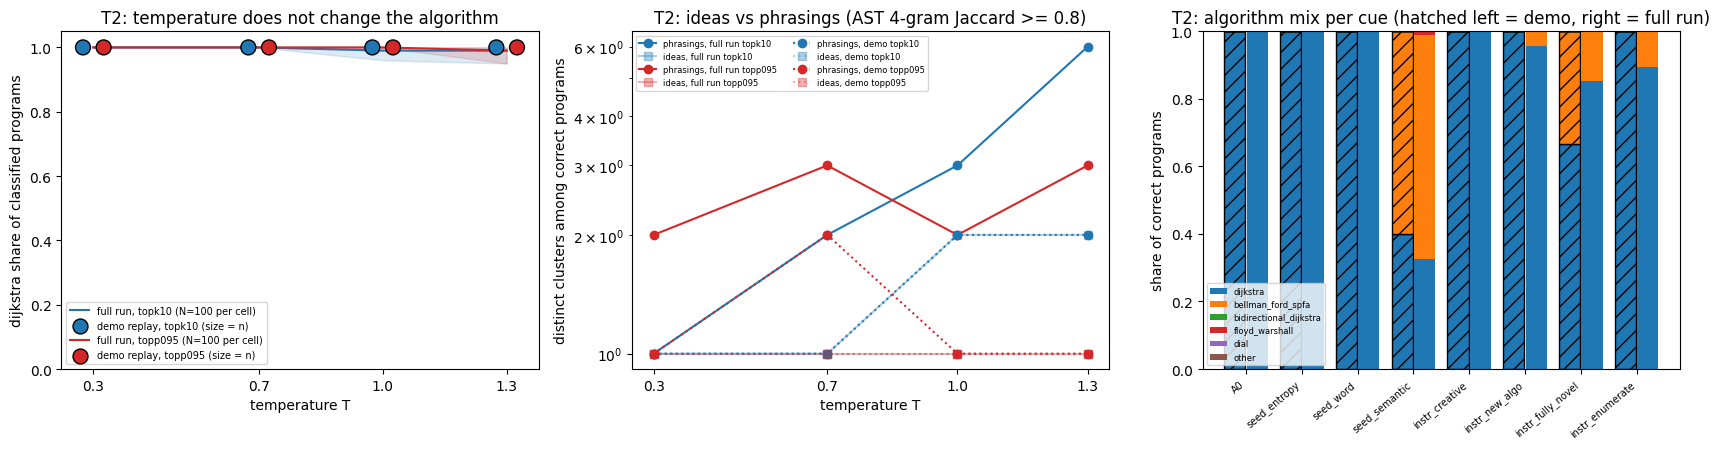

In [42]:
# ---- figure 1: behaviour ----
COLS = {"topk10": "#1f77b4", "topp095": "#d62728"}
mode_cols = {m: plt.get_cmap("tab10")(i) for i, m in enumerate(MODES[task] + ["other"])}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
for sampler, col in COLS.items():
    fr = sorted([r for r in FULL_A["bfs_dijkstra_table"] if r["task"] == task and r["arm"] == "A1"
                 and r["sampler"] == sampler and not r["thinking"]], key=lambda r: r["T"])
    ax.plot([r["T"] for r in fr], [r["share_classified"]["share"] for r in fr], "-", color=col,
            label=f"full run, {sampler} (N=100 per cell)")
    ax.fill_between([r["T"] for r in fr], [r["share_classified"]["cluster_boot95"][0] for r in fr],
                    [r["share_classified"]["cluster_boot95"][1] for r in fr], color=col, alpha=0.15)
    dr = [r for r in A["bfs_dijkstra_table"] if r["task"] == task and r["arm"] == "A1" and r["sampler"] == sampler
          and r["share_classified"]["share"] is not None]
    ax.scatter([r["T"] + (0.025 if sampler == "topp095" else -0.025) for r in dr],
               [r["share_classified"]["share"] for r in dr], s=[25 + 15 * r["share_classified"]["n"] for r in dr],
               color=col, edgecolor="k", zorder=3, label=f"demo replay, {sampler} (size = n)")
ax.set_ylim(0, 1.05)
ax.set_xticks([0.3, 0.7, 1.0, 1.3])
ax.set_xlabel("temperature T")
ax.set_ylabel(f"{prim} share of classified programs")
ax.set_title(f"{task}: temperature does not change the algorithm")
ax.legend(fontsize=7, loc="lower left")

ax = axes[1]
for src, A_, ls in (("full run", FULL_A, "-"), ("demo", A, ":")):
    for sampler, col in COLS.items():
        rows = sorted([r for r in A_["ideas_by_phrasings"]["table"] if r["task"] == task and r["arm"] == "A1"
                       and r["sampler"] == sampler], key=lambda r: r["T"])
        if not rows:
            continue
        x = [r["T"] for r in rows]
        ax.plot(x, [r["theta0.8_single"]["n_phrasings"] for r in rows], ls, marker="o", color=col,
                label=f"phrasings, {src} {sampler}")
        ax.plot(x, [r["theta0.8_single"]["n_ideas"] for r in rows], ls, marker="s", color=col, alpha=0.35,
                label=f"ideas, {src} {sampler}")
ax.set_yscale("log")
ax.set_xticks([0.3, 0.7, 1.0, 1.3])
ax.set_xlabel("temperature T")
ax.set_ylabel("distinct clusters among correct programs")
ax.set_title(f"{task}: ideas vs phrasings (AST 4-gram Jaccard >= 0.8)")
ax.legend(fontsize=6, ncol=2)

ax = axes[2]
names = ["A0"] + cues
for j, (src, A_) in enumerate((("demo", A), ("full run", FULL_A))):
    rows = [si(A_, c) for c in cues]
    base = next(r for r in rows if r is not None)["base_label_dist_correct"]
    dists = [base] + [r["label_dist_correct"] if r else {} for r in rows]
    bottom = np.zeros(len(names))
    for m in MODES[task] + ["other"]:
        v = np.array([dd.get(m, 0) / max(sum(dd.values()), 1) for dd in dists])
        ax.bar(np.arange(len(names)) + (j - 0.5) * 0.4, v, width=0.38, bottom=bottom, color=mode_cols[m],
               edgecolor="k" if j == 0 else "none", hatch="//" if j == 0 else None, label=m if j == 1 else None)
        bottom += v
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=40, ha="right", fontsize=7)
ax.set_ylabel("share of correct programs")
ax.set_title(f"{task}: algorithm mix per cue (hatched left = demo, right = full run)")
ax.legend(fontsize=6, loc="lower left")
plt.tight_layout()
plt.show()

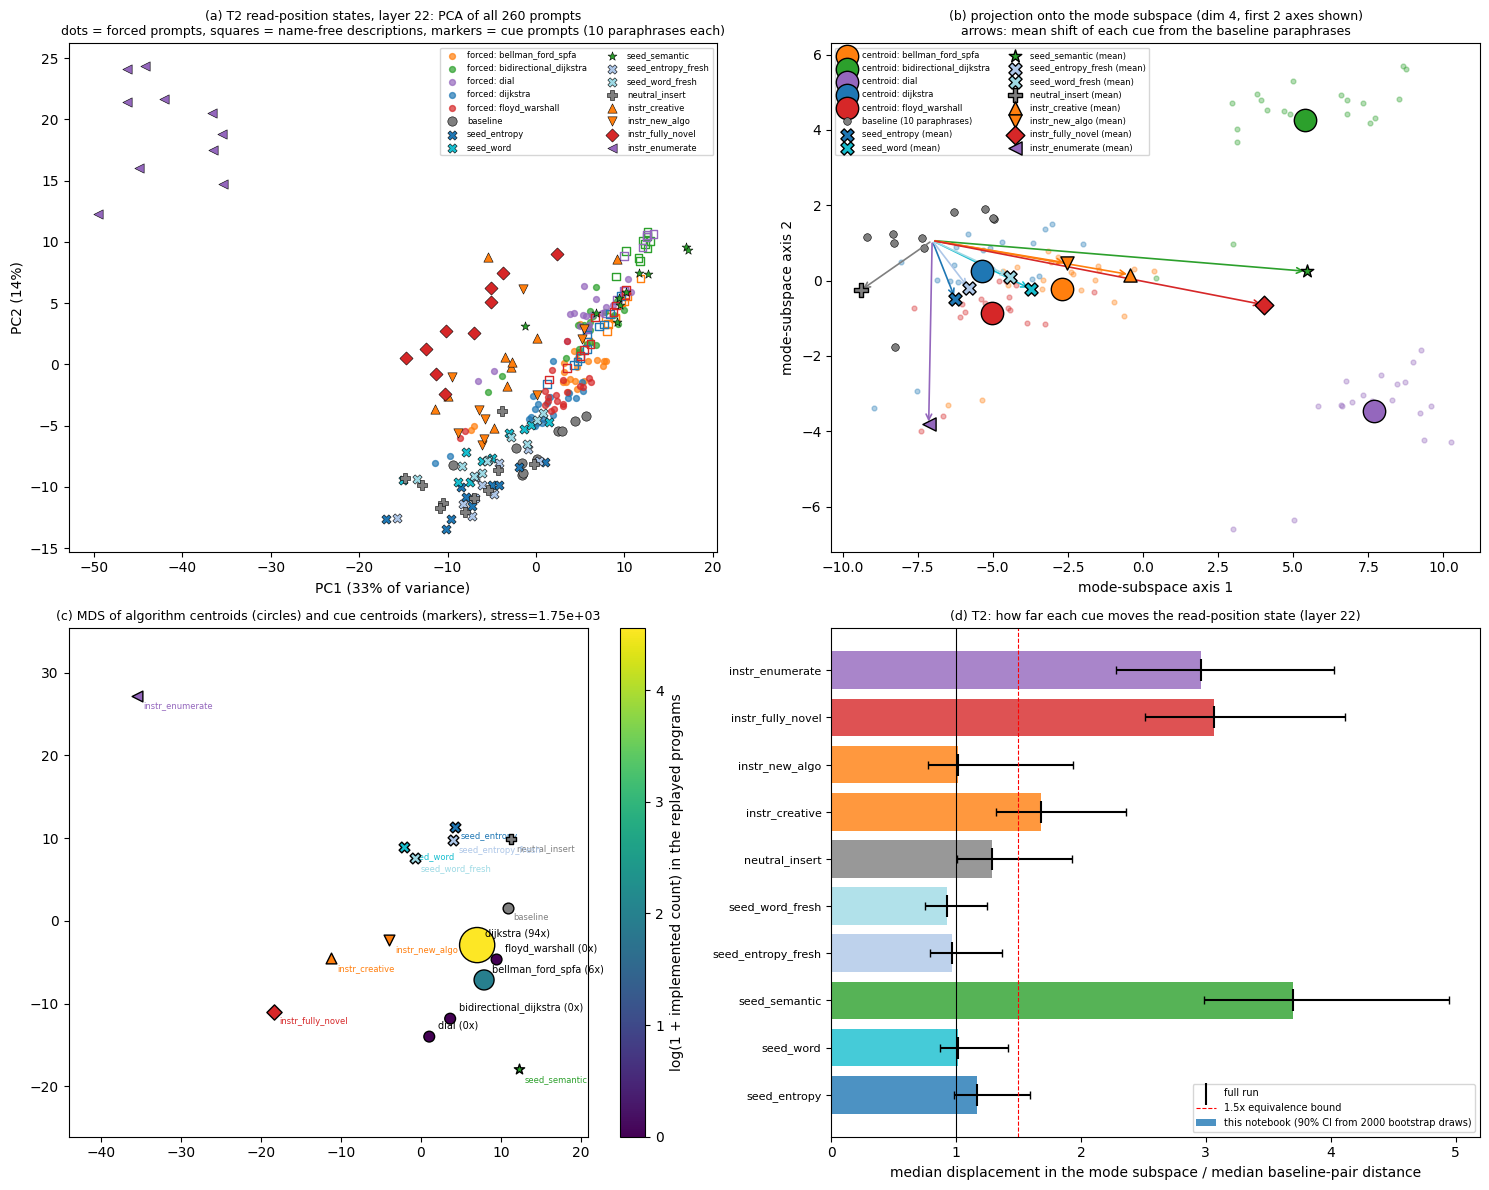

In [43]:
# ---- figure 2: the activation space at the read position (actual Qwen3-8B hidden states, layer l*) ----
from sklearn.manifold import MDS

meta = json.loads((STATES_DIR / "meta.json").read_text())
l = meta["l_star"][task]
Hn = np.load(STATES_DIR / f"R_named_{task}.npy", mmap_mode="r")[:, l].astype(np.float64)
Hd = np.load(STATES_DIR / f"R_described_{task}.npy", mmap_mode="r")[:, l].astype(np.float64)
Hc = np.load(STATES_DIR / f"R_conditions_{task}.npy", mmap_mode="r")[:, l].astype(np.float64)
yn = np.array([r["condition"].split(":")[1] for r in meta[f"R_named_{task}"]])
yd = np.array([r["condition"].split(":")[1] for r in meta[f"R_described_{task}"]])
yc = np.array([r["condition"] for r in meta[f"R_conditions_{task}"]])
modes = sorted(set(yn.tolist()))
COND_STYLE = {"baseline": ("o", "#7f7f7f"), "seed_entropy": ("X", "#1f77b4"), "seed_word": ("X", "#17becf"),
              "seed_semantic": ("*", "#2ca02c"), "seed_entropy_fresh": ("X", "#aec7e8"),
              "seed_word_fresh": ("X", "#9edae5"), "neutral_insert": ("P", "#7f7f7f"),
              "instr_creative": ("^", "#ff7f0e"), "instr_new_algo": ("v", "#ff7f0e"),
              "instr_fully_novel": ("D", "#d62728"), "instr_enumerate": ("<", "#9467bd")}
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# (a) PCA of every read-position state
ax = axes[0, 0]
allR = np.concatenate([Hn, Hd, Hc])
mu = allR.mean(0)
_, S, Vt = np.linalg.svd(allR - mu, full_matrices=False)
pc = lambda X: (X - mu) @ Vt[:2].T
ev = S[:2] ** 2 / (S ** 2).sum()
for m in modes:
    ax.scatter(*pc(Hn[yn == m]).T, s=18, color=mode_cols[m], alpha=0.7, label=f"forced: {m}")
    ax.scatter(*pc(Hd[yd == m]).T, s=30, facecolor="none", edgecolor=mode_cols[m], marker="s")
for c, (mk, col) in COND_STYLE.items():
    if (yc == c).any():
        ax.scatter(*pc(Hc[yc == c]).T, s=45, marker=mk, color=col, edgecolor="k", linewidth=0.4, label=c)
ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({ev[1]:.0%})")
ax.set_title(f"(a) {task} read-position states, layer {l}: PCA of all {len(allR)} prompts\n"
              "dots = forced prompts, squares = name-free descriptions, markers = cue prompts (10 paraphrases each)",
              fontsize=9)
ax.legend(fontsize=6, ncol=2, loc="best")

# (b) the mode subspace S_R: orthonormal basis of the centred forced-prompt centroids (subspace.basis_from_groups)
ax = axes[0, 1]
B, modes_b, Cc = subspace.basis_from_groups(Hn, yn)
centre = np.stack([Hn[yn == m].mean(0) for m in modes_b]).mean(0)
pj = lambda X: (np.atleast_2d(X) - centre) @ B[:, :2]
for i, m in enumerate(modes_b):
    ax.scatter(*pj(Hn[yn == m]).T, s=12, color=mode_cols[m], alpha=0.35)
    ax.scatter(*pj(Hn[yn == m].mean(0)).T, s=260, color=mode_cols[m], edgecolor="k", zorder=4, label=f"centroid: {m}")
base_mean = pj(Hc[yc == "baseline"].mean(0))[0]
ax.scatter(*pj(Hc[yc == "baseline"]).T, s=30, color="#7f7f7f", edgecolor="k", linewidth=0.4,
           label="baseline (10 paraphrases)")
for c, (mk, col) in COND_STYLE.items():
    if c == "baseline" or not (yc == c).any():
        continue
    cm = pj(Hc[yc == c].mean(0))[0]
    ax.annotate("", xy=cm, xytext=base_mean, arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
    ax.scatter(*cm, s=90, marker=mk, color=col, edgecolor="k", zorder=5, label=f"{c} (mean)")
ax.set_xlabel("mode-subspace axis 1")
ax.set_ylabel("mode-subspace axis 2")
ax.set_title(f"(b) projection onto the mode subspace (dim {B.shape[1]}, first 2 axes shown)\n"
             "arrows: mean shift of each cue from the baseline paraphrases", fontsize=9)
ax.legend(fontsize=6, ncol=2, loc="best")

# (c) MDS of the R-state centroids (as in the original figure 5), algorithm centroids sized/coloured by how often the
# algorithm was implemented in the replayed programs
ax = axes[1, 0]
conds = sorted(set(yc.tolist()))
P = np.array([Hn[yn == m].mean(0) for m in modes] + [Hc[yc == c].mean(0) for c in conds])
D = np.linalg.norm(P[:, None] - P[None], axis=2)
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, normalized_stress="auto")
Y = mds.fit_transform(D)
nat = Counter(s["label"] for s in samples if s["task"] == task)
sc = ax.scatter(Y[:len(modes), 0], Y[:len(modes), 1], s=[60 + 60 * np.sqrt(nat.get(m, 0)) for m in modes],
                c=[np.log1p(nat.get(m, 0)) for m in modes], cmap="viridis", edgecolor="k", zorder=3)
for k, m in enumerate(modes):
    ax.annotate(f"{m} ({nat.get(m, 0)}x)", Y[k], fontsize=7, xytext=(6, 6), textcoords="offset points")
for k, c in enumerate(conds):
    mk, col = COND_STYLE.get(c, ("X", "r"))
    ax.scatter(*Y[len(modes) + k], marker=mk, color=col, edgecolor="k", s=60, zorder=4)
    ax.annotate(c, Y[len(modes) + k], fontsize=6, color=col, xytext=(4, -9), textcoords="offset points")
plt.colorbar(sc, ax=ax, label="log(1 + implemented count) in the replayed programs")
ax.margins(0.18)
ax.set_title(f"(c) MDS of algorithm centroids (circles) and cue centroids (markers), stress={mds.stress_:.3g}",
             fontsize=9)

# (d) displacement in the mode subspace relative to paraphrase noise (subspace test 8d)
ax = axes[1, 1]
names_r = list(sub_demo)
y = [sub_demo[c]["ratio"] for c in names_r]
lo = [sub_demo[c]["ratio"] - sub_demo[c]["ratio_ci90"][0] for c in names_r]
hi = [sub_demo[c]["ratio_ci90"][1] - sub_demo[c]["ratio"] for c in names_r]
ax.barh(range(len(names_r)), y, xerr=[lo, hi], capsize=3, color=[COND_STYLE[c][1] for c in names_r], alpha=0.8,
        label=f"this notebook (90% CI from {N_BOOT} bootstrap draws)")
ax.scatter([sub_full[c]["ratio"] for c in names_r], range(len(names_r)), marker="|", s=250, color="k", zorder=4,
           label="full run")
ax.axvline(1.0, color="k", lw=0.8)
ax.axvline(1.5, color="r", lw=0.8, ls="--", label="1.5x equivalence bound")
ax.set_yticks(range(len(names_r)))
ax.set_yticklabels(names_r, fontsize=8)
ax.set_xlabel("median displacement in the mode subspace / median baseline-pair distance")
ax.set_title(f"(d) {task}: how far each cue moves the read-position state (layer {l})", fontsize=9)
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

## What the replay shows

The read-position numbers below come from the same stored hidden states as the full run, so the displacement ratios,
in-subspace shares, cosines and probe shifts equal the full-run values. Only their intervals and random-subspace ranks
depend on the draw counts.
- **Temperature is not an idea knob.** Across the temperature × sampler grid, essentially every replayed T2 program is
  Dijkstra, as in the full run (797/800). Higher T changes how the code is worded (the phrasing clusters in figure 1,
  middle), not the algorithm.
- **Random seeds act like rewording the preamble.** The entropy and word seeds leave the algorithm mix unchanged (full
  run: 100/100 Dijkstra each). At the read position they move the hidden state about as far as switching to another
  neutral preamble does: ratios 1.16 and 1.01, against 1.29 for a neutral insert. The entropy seed's 90% interval just
  passes the 1.5× equivalence bound (upper end 1.60). That is one reason the full run's mechanical verdict is MIXED.
- **A seed that describes an approach moves both the state and the behaviour.** The semantic seed is a story about news
  spreading in rounds. Its displacement is 3.7× the paraphrase noise, and 42% of it lies inside the 4-dimensional mode
  subspace, more than for any random subspace of the same size. The displacement points away from the Dijkstra
  centroid (cosine −0.63), and the probe trained on the forced prompts reads a +0.58 shift toward Bellman–Ford.
  However, the raw displacement is *not* aligned with the centred Bellman–Ford centroid (cosine −0.09). In the
  mode-subspace projection, panel (b), it heads toward the Dial / bidirectional-Dijkstra side. In behaviour, about half
  of the replayed semantic-seed programs are Bellman–Ford; in the full run, 61 of 92 correct programs are (+66 pp).
- **Instructions move the state but steer it less.** "Make a fully novel algorithm" (3.1×) and "First list 10
  approaches, then implement one" (3.0×) move the state almost as far as the semantic seed. Less of that movement lies
  in the mode subspace: 18%, and 5%, which is no more than a random subspace of the same size would capture. They
  change less of the behaviour: Dijkstra falls by 15 and 11 pp in the full run, and the programs that leave Dijkstra
  are almost all Bellman–Ford.

In short, the cue that changes the algorithm most is also the one whose read-position displacement lies most along the
directions that separate the forced algorithms. Temperature, random seeds and generic "be creative" instructions mostly
do not move the state along those directions. "List 10 approaches" changes the behaviour with little in-subspace
displacement at R. A plausible reason, not tested here, is that this choice is made later, after the list is written.

**Scaling up.** The defaults already use all 100 stored generations and the original draw counts. The full experiment
covers 5,220 generations, both tasks, the thinking-on arms and the GPU stages. It runs with `method.py all` in the
artifact folder, as described in its `README.md` and `reproducibility.md`.